In [1]:
import os
import pandas as pd
import numpy as np

print("Current Folder:")
print(os.getcwd())

print("\nFiles Available:")
for file in os.listdir():
    print(file)

Current Folder:
/Users/spoorthin/NIErnaya_Phase1_Submission

Files Available:
AgriPulse_Phase1_Submission.zip
mysuru_cleaned_arrivals.csv
Phase1_Mysuru_Agricultural_Dataset.csv
Phase1_Dataset_Summary.csv
phase 2.ipynb
README.txt
.ipynb_checkpoints
mysuru_cleaned_prices.csv
Mysuru_Mandi_Historical_Prices_2026.csv
phase 1.ipynb


In [2]:
# Load the Phase 1 datasets

raw_prices = pd.read_csv("Mysuru_Mandi_Historical_Prices_2026.csv")
cleaned_prices = pd.read_csv("mysuru_cleaned_prices.csv")
arrivals = pd.read_csv("mysuru_cleaned_arrivals.csv")
combined = pd.read_csv("Phase1_Mysuru_Agricultural_Dataset.csv")

# Display dataset dimensions

print("RAW HISTORICAL PRICES:", raw_prices.shape)
print("CLEANED PRICES:", cleaned_prices.shape)
print("ARRIVALS:", arrivals.shape)
print("COMBINED DATASET:", combined.shape)

print("\nRAW DATA COLUMNS:")
print(raw_prices.columns.tolist())

print("\nCLEANED DATA PREVIEW:")
display(cleaned_prices.head())

RAW HISTORICAL PRICES: (13303, 11)
CLEANED PRICES: (2428, 12)
ARRIVALS: (15, 12)
COMBINED DATASET: (299, 21)

RAW DATA COLUMNS:
['Arrival_Date', 'Commodity', 'Commodity_Code', 'District', 'Grade', 'Market', 'Max_Price', 'Min_Price', 'Modal_Price', 'State', 'Variety']

CLEANED DATA PREVIEW:


,Arrival_Date,Commodity,Market,Variety,Grade,Commodity_Code,District,State,Min_Price,Max_Price,Modal_Price,Price_Quality
0,2026-04-01,Brinjal,Mysuru APMC,Brinjal,Grade Range-1,35,Mysuru,Karnataka,1800.0,2000.0,1900.0,Valid
1,2026-04-01,Brinjal,Mysuru APMC,Round,Grade Range-1,35,Mysuru,Karnataka,1400.0,1600.0,1500.0,Valid
2,2026-04-01,Brinjal,Nanjangud APMC,Brinjal,Local,35,Mysuru,Karnataka,2083.0,2222.0,2083.0,Valid
3,2026-04-01,Onion,Mysuru APMC,Other,Grade Range-1,23,Mysuru,Karnataka,700.0,1200.0,1000.0,Valid
4,2026-04-01,Paddy(Common),Hunsur APMC,Paddy,Local,2,Mysuru,Karnataka,2200.0,2614.0,2588.0,Valid


In [3]:
# AGIRPULSE - PHASE 2 DATA QUALITY AUDIT

datasets = {
    "Raw Prices": raw_prices,
    "Cleaned Prices": cleaned_prices,
    "Arrivals": arrivals,
    "Combined Dataset": combined
}

for name, df in datasets.items():
    print("\n" + "=" * 55)
    print(name.upper())
    print("=" * 55)

    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())

    print("\nColumn names:")
    print(df.columns.tolist())

# Commodity and market coverage
print("\nCLEANED PRICE DATA COVERAGE")
print("Commodities:", cleaned_prices["Commodity"].nunique())
print(sorted(cleaned_prices["Commodity"].dropna().unique()))

print("\nMarkets:", cleaned_prices["Market"].nunique())
print(sorted(cleaned_prices["Market"].dropna().unique()))

# Date coverage
cleaned_prices["Arrival_Date"] = pd.to_datetime(
    cleaned_prices["Arrival_Date"], errors="coerce"
)

print("\nDate range:")
print(cleaned_prices["Arrival_Date"].min())
print(cleaned_prices["Arrival_Date"].max())

# Check price consistency
price_columns = ["Min_Price", "Modal_Price", "Max_Price"]

for col in price_columns:
    cleaned_prices[col] = pd.to_numeric(
        cleaned_prices[col], errors="coerce"
    )

invalid_prices = cleaned_prices[
    (cleaned_prices["Min_Price"] > cleaned_prices["Modal_Price"]) |
    (cleaned_prices["Modal_Price"] > cleaned_prices["Max_Price"])
]

print("\nInvalid price records:", len(invalid_prices))
display(invalid_prices.head(10))


RAW PRICES
Rows: 13303
Columns: 11
Missing values: 0
Duplicate rows: 0

Column names:
['Arrival_Date', 'Commodity', 'Commodity_Code', 'District', 'Grade', 'Market', 'Max_Price', 'Min_Price', 'Modal_Price', 'State', 'Variety']

CLEANED PRICES
Rows: 2428
Columns: 12
Missing values: 0
Duplicate rows: 0

Column names:
['Arrival_Date', 'Commodity', 'Market', 'Variety', 'Grade', 'Commodity_Code', 'District', 'State', 'Min_Price', 'Max_Price', 'Modal_Price', 'Price_Quality']

ARRIVALS
Rows: 15
Columns: 12
Missing values: 0
Duplicate rows: 0

Column names:
['Commodity', 'Arrivals', 'Unit of Arrivals', 'Variety', 'Grade', 'Minimum Price', 'Maximum Price', 'Modal Price', 'Unit of Price', 'Report_Date', 'Market', 'State']

COMBINED DATASET
Rows: 299
Columns: 21
Missing values: 0
Duplicate rows: 0

Column names:
['Arrival_Date', 'Commodity', 'Market', 'Variety', 'Grade', 'Commodity_Code', 'District', 'State', 'Min_Price', 'Max_Price', 'Modal_Price', 'Price_Quality', 'date', 'commodity', 'state', 

,Arrival_Date,Commodity,Market,Variety,Grade,Commodity_Code,District,State,Min_Price,Max_Price,Modal_Price,Price_Quality
377,2026-05-08,Paddy(Common),T. Narasipura APMC,Paddy,Non-FAQ,2,Mysuru,Karnataka,2704.0,3000.0,2700.0,Review


In [4]:
# Inspect the suspicious cleaned record
print("SUSPICIOUS RECORD IN CLEANED DATA:")
display(invalid_prices)

# Find the same record in the original dataset
raw_check = raw_prices.copy()
raw_check["Arrival_Date"] = pd.to_datetime(
    raw_check["Arrival_Date"], errors="coerce"
)

record = invalid_prices.iloc[0]

match = raw_check[
    (raw_check["Arrival_Date"] == record["Arrival_Date"]) &
    (raw_check["Commodity"] == record["Commodity"]) &
    (raw_check["Market"] == record["Market"])
]

print("\nMATCHING RECORD IN ORIGINAL DATA:")
display(match)

SUSPICIOUS RECORD IN CLEANED DATA:


,Arrival_Date,Commodity,Market,Variety,Grade,Commodity_Code,District,State,Min_Price,Max_Price,Modal_Price,Price_Quality
377,2026-05-08,Paddy(Common),T. Narasipura APMC,Paddy,Non-FAQ,2,Mysuru,Karnataka,2704.0,3000.0,2700.0,Review



MATCHING RECORD IN ORIGINAL DATA:


,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety
12045,2026-05-08,Paddy(Common),2,Mysuru,Non-FAQ,T. Narasipura APMC,3000,2200,2250,Karnataka,Paddy


In [5]:
# Compare the original and cleaned values

print("ORIGINAL RECORD")
display(match[[
    "Arrival_Date", "Commodity", "Market",
    "Min_Price", "Modal_Price", "Max_Price"
]])

print("\nCLEANED RECORD")
display(invalid_prices[[
    "Arrival_Date", "Commodity", "Market",
    "Min_Price", "Modal_Price", "Max_Price"
]])

print("\nPRICE DIFFERENCE")
print("Minimum price difference:",
      float(invalid_prices.iloc[0]["Min_Price"]) -
      float(match.iloc[0]["Min_Price"]))

print("Modal price difference:",
      float(invalid_prices.iloc[0]["Modal_Price"]) -
      float(match.iloc[0]["Modal_Price"]))

ORIGINAL RECORD


,Arrival_Date,Commodity,Market,Min_Price,Modal_Price,Max_Price
12045,2026-05-08,Paddy(Common),T. Narasipura APMC,2200,2250,3000



CLEANED RECORD


,Arrival_Date,Commodity,Market,Min_Price,Modal_Price,Max_Price
377,2026-05-08,Paddy(Common),T. Narasipura APMC,2704.0,2700.0,3000.0



PRICE DIFFERENCE
Minimum price difference: 504.0
Modal price difference: 450.0


In [6]:
# Compare all matching records between raw and cleaned datasets

keys = ["Arrival_Date", "Commodity", "Market"]

raw_compare = raw_prices.copy()
clean_compare = cleaned_prices.copy()

raw_compare["Arrival_Date"] = pd.to_datetime(
    raw_compare["Arrival_Date"], errors="coerce"
)
clean_compare["Arrival_Date"] = pd.to_datetime(
    clean_compare["Arrival_Date"], errors="coerce"
)

price_cols = ["Min_Price", "Modal_Price", "Max_Price"]

for col in price_cols:
    raw_compare[col] = pd.to_numeric(raw_compare[col], errors="coerce")
    clean_compare[col] = pd.to_numeric(clean_compare[col], errors="coerce")

comparison = raw_compare[keys + price_cols].merge(
    clean_compare[keys + price_cols],
    on=keys,
    how="inner",
    suffixes=("_raw", "_clean")
)

for col in price_cols:
    comparison[col + "_changed"] = (
        comparison[col + "_raw"] != comparison[col + "_clean"]
    )

changed_records = comparison[
    comparison[[c + "_changed" for c in price_cols]].any(axis=1)
]

print("Matching records:", len(comparison))
print("Records with changed prices:", len(changed_records))

display(changed_records.head(15))

Matching records: 527
Records with changed prices: 400


,Arrival_Date,Commodity,Market,Min_Price_raw,Modal_Price_raw,Max_Price_raw,Min_Price_clean,Modal_Price_clean,Max_Price_clean,Min_Price_changed,Modal_Price_changed,Max_Price_changed
6,2026-05-06,Paddy(Common),K.R.Nagar APMC,2000,2240,2400,2000.0,2378.0,2450.0,False,True,True
8,2026-07-09,Paddy(Common),K.R.Nagar APMC,2245,2245,2245,2000.0,2110.0,2450.0,True,True,True
9,2026-05-07,Paddy(Common),K.R.Nagar APMC,2000,2275,2400,2200.0,2200.0,2200.0,True,True,True
10,2026-06-08,Paddy(Common),K.R.Nagar APMC,2000,2000,2000,2000.0,2087.0,2300.0,False,True,True
12,2026-09-04,Paddy(Common),K.R.Nagar APMC,2000,2155,2200,2500.0,2500.0,2500.0,True,True,True
13,2026-09-05,Paddy(Common),K.R.Nagar APMC,2250,2250,2250,2600.0,2600.0,2600.0,True,True,True
14,2026-09-07,Paddy(Common),K.R.Nagar APMC,2000,2110,2450,2245.0,2245.0,2245.0,True,True,True
15,2026-05-09,Paddy(Common),K.R.Nagar APMC,2600,2600,2600,2250.0,2250.0,2250.0,True,True,True
16,2026-06-04,Paddy(Common),K.R.Nagar APMC,2000,2000,2000,2000.0,2084.0,2400.0,False,True,True
17,2026-06-05,Paddy(Common),K.R.Nagar APMC,2000,2378,2450,2000.0,2240.0,2400.0,False,True,True


In [7]:
# Accurate record comparison using variety and grade too

keys = [
    "Arrival_Date",
    "Commodity",
    "Market",
    "Variety",
    "Grade"
]

raw_full = raw_prices.copy()
clean_full = cleaned_prices.copy()

for df in [raw_full, clean_full]:
    df["Arrival_Date"] = pd.to_datetime(
        df["Arrival_Date"], errors="coerce"
    )

    for col in ["Commodity", "Market", "Variety", "Grade"]:
        df[col] = df[col].astype(str).str.strip()

    for col in ["Min_Price", "Modal_Price", "Max_Price"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Check whether identifying fields are unique
print("Raw duplicate key records:", raw_full.duplicated(keys).sum())
print("Cleaned duplicate key records:", clean_full.duplicated(keys).sum())

# Compare records
accurate_comparison = raw_full[
    keys + ["Min_Price", "Modal_Price", "Max_Price"]
].merge(
    clean_full[
        keys + ["Min_Price", "Modal_Price", "Max_Price"]
    ],
    on=keys,
    how="inner",
    suffixes=("_raw", "_clean")
)

for col in ["Min_Price", "Modal_Price", "Max_Price"]:
    accurate_comparison[col + "_changed"] = (
        accurate_comparison[col + "_raw"] !=
        accurate_comparison[col + "_clean"]
    )

changed_accurately = accurate_comparison[
    accurate_comparison[
        ["Min_Price_changed", "Modal_Price_changed",
         "Max_Price_changed"]
    ].any(axis=1)
]

print("\nAccurately matched records:", len(accurate_comparison))
print("Records with changed prices:", len(changed_accurately))

display(changed_accurately.head(15))

Raw duplicate key records: 7468
Cleaned duplicate key records: 0

Accurately matched records: 341
Records with changed prices: 226


,Arrival_Date,Commodity,Market,Variety,Grade,Min_Price_raw,Modal_Price_raw,Max_Price_raw,Min_Price_clean,Modal_Price_clean,Max_Price_clean,Min_Price_changed,Modal_Price_changed,Max_Price_changed
6,2026-05-06,Paddy(Common),K.R.Nagar APMC,Paddy Dappa,FAQ,2000,2240,2400,2000.0,2378.0,2450.0,False,True,True
8,2026-07-09,Paddy(Common),K.R.Nagar APMC,Paddy Dappa,FAQ,2245,2245,2245,2000.0,2110.0,2450.0,True,True,True
9,2026-05-07,Paddy(Common),K.R.Nagar APMC,Paddy Dappa,FAQ,2000,2275,2400,2200.0,2200.0,2200.0,True,True,True
11,2026-09-04,Paddy(Common),K.R.Nagar APMC,Paddy Dappa,FAQ,2000,2155,2200,2500.0,2500.0,2500.0,True,True,True
12,2026-09-05,Paddy(Common),K.R.Nagar APMC,Paddy Dappa,FAQ,2250,2250,2250,2600.0,2600.0,2600.0,True,True,True
13,2026-09-07,Paddy(Common),K.R.Nagar APMC,Paddy Dappa,FAQ,2000,2110,2450,2245.0,2245.0,2245.0,True,True,True
14,2026-05-09,Paddy(Common),K.R.Nagar APMC,Paddy Dappa,FAQ,2600,2600,2600,2250.0,2250.0,2250.0,True,True,True
15,2026-06-04,Paddy(Common),K.R.Nagar APMC,Paddy Dappa,FAQ,2000,2000,2000,2000.0,2084.0,2400.0,False,True,True
16,2026-06-05,Paddy(Common),K.R.Nagar APMC,Paddy Dappa,FAQ,2000,2378,2450,2000.0,2240.0,2400.0,False,True,True
17,2026-04-09,Paddy(Common),K.R.Nagar APMC,Paddy Dappa,FAQ,2500,2500,2500,2000.0,2155.0,2200.0,True,True,True


In [8]:
# Investigate repeated records in original dataset

keys = [
    "Arrival_Date",
    "Commodity",
    "Market",
    "Variety",
    "Grade"
]

# Count how frequently each combination occurs
duplicate_groups = (
    raw_prices.groupby(keys, dropna=False)
    .size()
    .reset_index(name="Record_Count")
)

duplicate_groups = duplicate_groups[
    duplicate_groups["Record_Count"] > 1
].sort_values("Record_Count", ascending=False)

print("Repeated key combinations:", len(duplicate_groups))

print("\nMost repeated combinations:")
display(duplicate_groups.head(10))

# Inspect the actual original records for the first repeated combination
example = duplicate_groups.iloc[0]

example_records = raw_prices[
    (raw_prices["Arrival_Date"] == example["Arrival_Date"]) &
    (raw_prices["Commodity"] == example["Commodity"]) &
    (raw_prices["Market"] == example["Market"]) &
    (raw_prices["Variety"] == example["Variety"]) &
    (raw_prices["Grade"] == example["Grade"])
]

print("\nActual original records for this combination:")
display(example_records)

Repeated key combinations: 4

Most repeated combinations:


,Arrival_Date,Commodity,Market,Variety,Grade,Record_Count
3677,08/10/2026,Maize,Hunsur APMC,Local,FAQ,2
7002,16/08/2026,Paddy(Common),K.R.Nagar APMC,Paddy Dappa,FAQ,2
7012,16/08/2026,Tender Coconut,K.R.Nagar APMC,Tender Coconut,Small,2
12742,30/05/2026,Rice,Mysuru APMC,Fine,Local,2



Actual original records for this combination:


,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety
209,08/10/2026,Maize,4,Mysuru,FAQ,Hunsur APMC,1800,1800,1800,Karnataka,Local
222,08/10/2026,Maize,4,Mysuru,FAQ,Hunsur APMC,2000,1800,2000,Karnataka,Local


In [9]:
# Display every original record belonging to a repeated key

for i, group in duplicate_groups.iterrows():

    print("\n" + "=" * 65)
    print("REPEATED COMBINATION", i + 1)
    print("=" * 65)

    condition = pd.Series(True, index=raw_prices.index)

    for col in keys:
        condition &= (
            raw_prices[col].astype(str) ==
            str(group[col])
        )

    display(raw_prices.loc[condition])


REPEATED COMBINATION 3678


,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety
209,08/10/2026,Maize,4,Mysuru,FAQ,Hunsur APMC,1800,1800,1800,Karnataka,Local
222,08/10/2026,Maize,4,Mysuru,FAQ,Hunsur APMC,2000,1800,2000,Karnataka,Local



REPEATED COMBINATION 7003


,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety
882,16/08/2026,Paddy(Common),2,Mysuru,FAQ,K.R.Nagar APMC,2500,2000,2340,Karnataka,Paddy Dappa
1234,16/08/2026,Paddy(Common),2,Mysuru,FAQ,K.R.Nagar APMC,2000,2000,2000,Karnataka,Paddy Dappa



REPEATED COMBINATION 7013


,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety
854,16/08/2026,Tender Coconut,200,Mysuru,Small,K.R.Nagar APMC,25000,20000,21000,Karnataka,Tender Coconut
1222,16/08/2026,Tender Coconut,200,Mysuru,Small,K.R.Nagar APMC,25000,19000,20000,Karnataka,Tender Coconut



REPEATED COMBINATION 12743


,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety
4700,30/05/2026,Rice,3,Mysuru,Local,Mysuru APMC,8000,2320,5500,Karnataka,Fine
6658,30/05/2026,Rice,3,Mysuru,Local,Mysuru APMC,7750,2320,2400,Karnataka,Fine


In [10]:
import pandas as pd

# Create a separate audit workbook.
# This does NOT modify either original dataset.

raw = raw_prices.copy()
clean = cleaned_prices.copy()

# Standardise dates for comparison
raw["Arrival_Date"] = pd.to_datetime(raw["Arrival_Date"], errors="coerce")
clean["Arrival_Date"] = pd.to_datetime(clean["Arrival_Date"], errors="coerce")

# 1. Exact duplicates in raw data
exact_duplicates = raw[raw.duplicated(keep=False)].copy()

# 2. Repeated market records, using all identifying fields available
key_candidates = [
    "Arrival_Date", "Commodity", "Market", "Variety", "Grade"
]
keys = [c for c in key_candidates if c in raw.columns]

repeated_keys = (
    raw.groupby(keys, dropna=False)
       .size()
       .reset_index(name="Record_Count")
       .query("Record_Count > 1")
       .sort_values("Record_Count", ascending=False)
)

# 3. Check price validity in cleaned data
price_cols = ["Min_Price", "Modal_Price", "Max_Price"]
for col in price_cols:
    clean[col] = pd.to_numeric(clean[col], errors="coerce")

invalid_prices = clean[
    (clean["Min_Price"] > clean["Modal_Price"]) |
    (clean["Modal_Price"] > clean["Max_Price"]) |
    (clean[price_cols] < 0).any(axis=1)
].copy()

# 4. Dataset summary
summary = pd.DataFrame({
    "Measure": [
        "Raw price rows",
        "Cleaned price rows",
        "Exact duplicate rows in raw data",
        "Repeated key combinations in raw data",
        "Invalid price records in cleaned data",
        "Raw missing values",
        "Cleaned missing values"
    ],
    "Value": [
        len(raw),
        len(clean),
        len(exact_duplicates),
        len(repeated_keys),
        len(invalid_prices),
        int(raw.isna().sum().sum()),
        int(clean.isna().sum().sum())
    ]
})

# 5. Export separate sheets
output_file = "AgriPulse_Phase2_Data_Audit.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    summary.to_excel(writer, sheet_name="Summary", index=False)
    exact_duplicates.to_excel(writer, sheet_name="Exact Duplicates", index=False)
    repeated_keys.to_excel(writer, sheet_name="Repeated Keys", index=False)
    invalid_prices.to_excel(writer, sheet_name="Invalid Prices", index=False)

print("AUDIT WORKBOOK CREATED:", output_file)
display(summary)
print("Repeated key combinations:")
display(repeated_keys.head(10))
print("Invalid cleaned price records:")
display(invalid_prices.head(10))

AUDIT WORKBOOK CREATED: AgriPulse_Phase2_Data_Audit.xlsx


,Measure,Value
0,Raw price rows,13303
1,Cleaned price rows,2428
2,Exact duplicate rows in raw data,4846
3,Repeated key combinations in raw data,302
4,Invalid price records in cleaned data,1
5,Raw missing values,7853
6,Cleaned missing values,0


Repeated key combinations:


,Arrival_Date,Commodity,Market,Variety,Grade,Record_Count
5716,NaT,Paddy(Common),T. Narasipura APMC,Paddy,Non-FAQ,123
5809,NaT,Tender Coconut,K.R.Nagar APMC,Tender Coconut,Small,110
5524,NaT,Cabbage,Mysuru APMC,Cabbage,Medium,93
5655,NaT,Ladies Finger,Mysuru APMC,Ladies Finger,Medium,93
5794,NaT,Sweet Potato,Mysuru APMC,Sweet Potato,Medium,93
5543,NaT,Chilly Capsicum,Mysuru APMC,Chilly Capsicum,Medium,93
5538,NaT,Cauliflower,Mysuru APMC,Local,Medium,93
5490,NaT,Beans,Mysuru APMC,Beans (Whole),Medium,93
5531,NaT,Carrot,Mysuru APMC,Carrot,Medium,93
5616,NaT,Green Chilli,Mysuru APMC,Green Chilly,Medium,93


Invalid cleaned price records:


,Arrival_Date,Commodity,Market,Variety,Grade,Commodity_Code,District,State,Min_Price,Max_Price,Modal_Price,Price_Quality
377,2026-05-08,Paddy(Common),T. Narasipura APMC,Paddy,Non-FAQ,2,Mysuru,Karnataka,2704.0,3000.0,2700.0,Review


In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# Make a separate copy for analysis
analysis_prices = cleaned_prices.copy()

# Convert date and price columns
analysis_prices["Arrival_Date"] = pd.to_datetime(
    analysis_prices["Arrival_Date"], errors="coerce"
)

price_cols = ["Min_Price", "Modal_Price", "Max_Price"]

for col in price_cols:
    analysis_prices[col] = pd.to_numeric(
        analysis_prices[col], errors="coerce"
    )

# Remove invalid price records from analysis only
analysis_prices = analysis_prices.dropna(
    subset=["Arrival_Date"] + price_cols
)

analysis_prices = analysis_prices[
    (analysis_prices["Min_Price"] <= analysis_prices["Modal_Price"]) &
    (analysis_prices["Modal_Price"] <= analysis_prices["Max_Price"])
].copy()

# 1. Overall statistical summary
print("PRICE DATA SUMMARY")
display(analysis_prices[price_cols].describe().round(2))

# 2. Commodity-wise summary
commodity_summary = analysis_prices.groupby("Commodity").agg(
    Record_Count=("Modal_Price", "count"),
    Average_Price=("Modal_Price", "mean"),
    Minimum_Price=("Min_Price", "min"),
    Maximum_Price=("Max_Price", "max"),
    Price_Std_Dev=("Modal_Price", "std")
).round(2)

print("\nCOMMODITY-WISE ANALYSIS")
display(commodity_summary)

# 3. Market-wise summary
market_summary = analysis_prices.groupby("Market").agg(
    Record_Count=("Modal_Price", "count"),
    Average_Price=("Modal_Price", "mean")
).round(2)

print("\nMARKET-WISE ANALYSIS")
display(market_summary)

# 4. Save EDA results in a new Excel workbook
with pd.ExcelWriter(
    "AgriPulse_Phase2_EDA_Summary.xlsx",
    engine="openpyxl"
) as writer:
    commodity_summary.to_excel(writer, sheet_name="Commodity Analysis")
    market_summary.to_excel(writer, sheet_name="Market Analysis")
    analysis_prices.to_excel(writer, sheet_name="Analysis Dataset", index=False)

print("\nEDA SUMMARY EXCEL FILE CREATED SUCCESSFULLY")
print("Records used for analysis:", len(analysis_prices))

PRICE DATA SUMMARY


,Min_Price,Modal_Price,Max_Price
count,2427.00,2427.00,2427.00
mean,2464.69,2757.60,3183.63
std,1598.42,1669.69,2284.62
min,400.00,500.00,500.00
25%,1600.00,2000.00,2000.00
50%,2200.00,2400.00,2583.00
75%,2950.00,3030.00,3400.00
max,19250.00,19250.00,30000.00



COMMODITY-WISE ANALYSIS


,Record_Count,Average_Price,Minimum_Price,Maximum_Price,Price_Std_Dev
Commodity,,,,,
Brinjal,592,2348.56,700.0,27777.0,773.00
Onion,230,2954.56,400.0,6000.0,1468.83
Paddy(Common),515,2400.77,1500.0,30000.0,417.79
Potato,291,2382.74,650.0,6750.0,1061.97
Rice,376,4248.67,1800.0,19250.0,3216.09
Tomato,423,2589.89,400.0,6666.0,1150.33



MARKET-WISE ANALYSIS


,Record_Count,Average_Price
Market,,
Hunsur APMC,92,2606.82
K.R.Nagar APMC,177,2314.11
Mysuru APMC,1017,2781.68
Nanjangud APMC,422,3393.27
Periyapatna APMC,23,2126.09
Santhesargur APMC,67,2586.36
T. Narasipura APMC,629,2480.38



EDA SUMMARY EXCEL FILE CREATED SUCCESSFULLY
Records used for analysis: 2427


In [14]:
import pandas as pd

file = "AgriPulse_Phase2_Detailed_Audit.xlsx"

excel = pd.ExcelFile(file)

print("AUDIT WORKBOOK VERIFIED")
print("Sheets found:", excel.sheet_names)

for sheet in excel.sheet_names:
    print("\n---", sheet, "---")
    display(pd.read_excel(file, sheet_name=sheet).head(10))

AUDIT WORKBOOK VERIFIED
Sheets found: ['Repeated Combinations', 'Repeated Records', 'Invalid Prices']

--- Repeated Combinations ---


,Arrival_Date,Commodity,Market,Variety,Grade,Record_Count



--- Repeated Records ---


,Arrival_Date,Commodity,Market,Variety,Grade,Commodity_Code,District,State,Min_Price,Max_Price,Modal_Price,Price_Quality



--- Invalid Prices ---


,Arrival_Date,Commodity,Market,Variety,Grade,Commodity_Code,District,State,Min_Price,Max_Price,Modal_Price,Price_Quality
0,2026-05-08,Paddy(Common),T. Narasipura APMC,Paddy,Non-FAQ,2,Mysuru,Karnataka,2704,3000,2700,Review


In [15]:
print("RAW DATA")
print("Total rows:", len(raw_prices))
print("Missing dates:", raw_prices["Arrival_Date"].isna().sum())

print("\nCLEANED DATA")
print("Total rows:", len(cleaned_prices))
print("Missing dates:", cleaned_prices["Arrival_Date"].isna().sum())

print("\nExact duplicate rows in raw data:",
      raw_prices.duplicated().sum())

print("Exact duplicate rows in cleaned data:",
      cleaned_prices.duplicated().sum())

RAW DATA
Total rows: 13303
Missing dates: 0

CLEANED DATA
Total rows: 2428
Missing dates: 0

Exact duplicate rows in raw data: 0
Exact duplicate rows in cleaned data: 0


In [16]:
keys = ["Arrival_Date", "Commodity", "Market", "Variety", "Grade"]

repeated = (
    raw_prices.groupby(keys, dropna=False)
    .size()
    .reset_index(name="Record_Count")
    .query("Record_Count > 1")
    .sort_values("Record_Count", ascending=False)
)

print("Repeated combinations:", len(repeated))
print("Rows belonging to repeated combinations:",
      repeated["Record_Count"].sum())

display(repeated.head(15))

Repeated combinations: 4
Rows belonging to repeated combinations: 8


,Arrival_Date,Commodity,Market,Variety,Grade,Record_Count
3677,08/10/2026,Maize,Hunsur APMC,Local,FAQ,2
7002,16/08/2026,Paddy(Common),K.R.Nagar APMC,Paddy Dappa,FAQ,2
7012,16/08/2026,Tender Coconut,K.R.Nagar APMC,Tender Coconut,Small,2
12742,30/05/2026,Rice,Mysuru APMC,Fine,Local,2


In [17]:
# STEP 1: Inspect all records belonging to repeated combinations

keys = [
    "Arrival_Date",
    "Commodity",
    "Market",
    "Variety",
    "Grade"
]

repeated_keys = (
    raw_prices.groupby(keys, dropna=False)
    .size()
    .reset_index(name="Record_Count")
    .query("Record_Count > 1")
)

repeated_records = raw_prices.merge(
    repeated_keys[keys],
    on=keys,
    how="inner"
)

repeated_records = repeated_records.sort_values(keys)

print("TOTAL REPEATED RECORDS:", len(repeated_records))

display(repeated_records)

TOTAL REPEATED RECORDS: 8


,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety
0,08/10/2026,Maize,4,Mysuru,FAQ,Hunsur APMC,1800,1800,1800,Karnataka,Local
1,08/10/2026,Maize,4,Mysuru,FAQ,Hunsur APMC,2000,1800,2000,Karnataka,Local
3,16/08/2026,Paddy(Common),2,Mysuru,FAQ,K.R.Nagar APMC,2500,2000,2340,Karnataka,Paddy Dappa
5,16/08/2026,Paddy(Common),2,Mysuru,FAQ,K.R.Nagar APMC,2000,2000,2000,Karnataka,Paddy Dappa
2,16/08/2026,Tender Coconut,200,Mysuru,Small,K.R.Nagar APMC,25000,20000,21000,Karnataka,Tender Coconut
4,16/08/2026,Tender Coconut,200,Mysuru,Small,K.R.Nagar APMC,25000,19000,20000,Karnataka,Tender Coconut
6,30/05/2026,Rice,3,Mysuru,Local,Mysuru APMC,8000,2320,5500,Karnataka,Fine
7,30/05/2026,Rice,3,Mysuru,Local,Mysuru APMC,7750,2320,2400,Karnataka,Fine


In [18]:
# STEP 2: Detailed inspection of repeated records

import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

print("COMPLETE REPEATED RECORDS")

display(
    repeated_records[
        [
            "Arrival_Date",
            "Commodity",
            "Commodity_Code",
            "District",
            "State",
            "Market",
            "Variety",
            "Grade",
            "Min_Price",
            "Max_Price",
            "Modal_Price",
            "Price_Quality"
        ]
    ].to_string(index=True)
)

COMPLETE REPEATED RECORDS


KeyError: "['Price_Quality'] not in index"

In [19]:
# STEP 2: Inspect all repeated records

print("COMPLETE REPEATED RECORDS")

columns_to_check = [
    "Arrival_Date",
    "Commodity",
    "Commodity_Code",
    "District",
    "State",
    "Market",
    "Variety",
    "Grade",
    "Min_Price",
    "Max_Price",
    "Modal_Price"
]

# Select only columns that actually exist
available_columns = [
    col for col in columns_to_check
    if col in repeated_records.columns
]

display(
    repeated_records[available_columns]
    .sort_values(["Commodity", "Market", "Arrival_Date"])
)

COMPLETE REPEATED RECORDS


,Arrival_Date,Commodity,Commodity_Code,District,State,Market,Variety,Grade,Min_Price,Max_Price,Modal_Price
0,08/10/2026,Maize,4,Mysuru,Karnataka,Hunsur APMC,Local,FAQ,1800,1800,1800
1,08/10/2026,Maize,4,Mysuru,Karnataka,Hunsur APMC,Local,FAQ,1800,2000,2000
3,16/08/2026,Paddy(Common),2,Mysuru,Karnataka,K.R.Nagar APMC,Paddy Dappa,FAQ,2000,2500,2340
5,16/08/2026,Paddy(Common),2,Mysuru,Karnataka,K.R.Nagar APMC,Paddy Dappa,FAQ,2000,2000,2000
6,30/05/2026,Rice,3,Mysuru,Karnataka,Mysuru APMC,Fine,Local,2320,8000,5500
7,30/05/2026,Rice,3,Mysuru,Karnataka,Mysuru APMC,Fine,Local,2320,7750,2400
2,16/08/2026,Tender Coconut,200,Mysuru,Karnataka,K.R.Nagar APMC,Tender Coconut,Small,20000,25000,21000
4,16/08/2026,Tender Coconut,200,Mysuru,Karnataka,K.R.Nagar APMC,Tender Coconut,Small,19000,25000,20000


In [21]:
# STEP 3: Check repeated combinations in cleaned data

keys = [
    "Arrival_Date",
    "Commodity",
    "Market",
    "Variety",
    "Grade"
]

cleaned_repeated = (
    cleaned_prices.groupby(keys, dropna=False)
    .size()
    .reset_index(name="Record_Count")
    .query("Record_Count > 1")
    .sort_values("Record_Count", ascending=False)
)

print("REPEATED COMBINATIONS IN CLEANED DATA:",
      len(cleaned_repeated))

print("TOTAL ROWS IN THESE COMBINATIONS:",
      cleaned_repeated["Record_Count"].sum())

display(cleaned_repeated)

REPEATED COMBINATIONS IN CLEANED DATA: 0
TOTAL ROWS IN THESE COMBINATIONS: 0


,Arrival_Date,Commodity,Market,Variety,Grade,Record_Count


In [22]:
# STEP 4: Check invalid price values in cleaned data

price_columns = ["Min_Price", "Max_Price", "Modal_Price"]

for col in price_columns:
    cleaned_prices[col] = pd.to_numeric(
        cleaned_prices[col], errors="coerce"
    )

invalid_prices_cleaned = cleaned_prices[
    (cleaned_prices["Min_Price"] > cleaned_prices["Modal_Price"]) |
    (cleaned_prices["Modal_Price"] > cleaned_prices["Max_Price"]) |
    (cleaned_prices[price_columns] <= 0).any(axis=1)
]

print("INVALID PRICE RECORDS IN CLEANED DATA:",
      len(invalid_prices_cleaned))

display(invalid_prices_cleaned)

INVALID PRICE RECORDS IN CLEANED DATA: 1


,Arrival_Date,Commodity,Market,Variety,Grade,Commodity_Code,District,State,Min_Price,Max_Price,Modal_Price,Price_Quality
377,2026-05-08,Paddy(Common),T. Narasipura APMC,Paddy,Non-FAQ,2,Mysuru,Karnataka,2704.0,3000.0,2700.0,Review


In [23]:
# STEP 5: Display complete invalid price record

display(
    invalid_prices_cleaned[
        [
            "Arrival_Date",
            "Commodity",
            "Market",
            "Variety",
            "Grade",
            "Min_Price",
            "Max_Price",
            "Modal_Price",
            "Price_Quality"
        ]
    ].to_string(index=False)
)

'Arrival_Date     Commodity             Market Variety   Grade  Min_Price  Max_Price  Modal_Price Price_Quality\n  2026-05-08 Paddy(Common) T. Narasipura APMC   Paddy Non-FAQ     2704.0     3000.0       2700.0        Review'

In [24]:
# STEP 6: Audit cleaned price dataset coverage

cleaned_prices["Arrival_Date"] = pd.to_datetime(
    cleaned_prices["Arrival_Date"], errors="coerce"
)

print("CLEANED PRICE DATASET COVERAGE")
print("--------------------------------")

print("Total records:", len(cleaned_prices))

print(
    "Date range:",
    cleaned_prices["Arrival_Date"].min().date(),
    "to",
    cleaned_prices["Arrival_Date"].max().date()
)

print(
    "Number of commodities:",
    cleaned_prices["Commodity"].nunique()
)

print(
    "Number of markets:",
    cleaned_prices["Market"].nunique()
)

print("\nCOMMODITIES:")
display(
    cleaned_prices["Commodity"].value_counts().to_frame("Record_Count")
)

print("\nMARKETS:")
display(
    cleaned_prices["Market"].value_counts().to_frame("Record_Count")
)

CLEANED PRICE DATASET COVERAGE
--------------------------------
Total records: 2428
Date range: 2026-04-01 to 2026-10-31
Number of commodities: 6
Number of markets: 7

COMMODITIES:


,Record_Count
Commodity,
Brinjal,592
Paddy(Common),516
Tomato,423
Rice,376
Potato,291
Onion,230



MARKETS:


,Record_Count
Market,
Mysuru APMC,1017
T. Narasipura APMC,630
Nanjangud APMC,422
K.R.Nagar APMC,177
Hunsur APMC,92
Santhesargur APMC,67
Periyapatna APMC,23


In [25]:
# STEP 7: Inspect cleaned arrivals dataset

arrivals_audit = pd.read_csv("mysuru_cleaned_arrivals.csv")

print("CLEANED ARRIVALS DATASET")
print("------------------------")

print("Total rows:", len(arrivals_audit))
print("Total columns:", len(arrivals_audit.columns))

print("\nCOLUMN NAMES:")
print(arrivals_audit.columns.tolist())

print("\nFIRST 10 RECORDS:")
display(arrivals_audit.head(10))

print("\nDATA TYPES:")
display(arrivals_audit.dtypes.to_frame("Data_Type"))

CLEANED ARRIVALS DATASET
------------------------
Total rows: 15
Total columns: 12

COLUMN NAMES:
['Commodity', 'Arrivals', 'Unit of Arrivals', 'Variety', 'Grade', 'Minimum Price', 'Maximum Price', 'Modal Price', 'Unit of Price', 'Report_Date', 'Market', 'State']

FIRST 10 RECORDS:


,Commodity,Arrivals,Unit of Arrivals,Variety,Grade,Minimum Price,Maximum Price,Modal Price,Unit of Price,Report_Date,Market,State
0,Apple,9.5,Metric Tonnes,Kasmir/Shimla - II,Medium,17360.0,17730.0,17500.0,Rs./Quintal,2026-10-30,Mysuru APMC,Karnataka
1,Black Gram Dal(Urd Dal),1.5,Metric Tonnes,Black Gram Dal,Local,12400.0,12400.0,12400.0,Rs./Quintal,2026-10-30,Mysuru APMC,Karnataka
2,Corriander seed,6.0,Metric Tonnes,Coriander Seed,Local,10539.0,10539.0,10539.0,Rs./Quintal,2026-10-30,Mysuru APMC,Karnataka
3,Cowpea(Lobia/Karamani),0.6,Metric Tonnes,Cowpea (Whole),Local,11000.0,11000.0,11000.0,Rs./Quintal,2026-10-30,Mysuru APMC,Karnataka
4,Grapes,0.8,Metric Tonnes,Green,Medium,8375.0,8375.0,8375.0,Rs./Quintal,2026-10-30,Mysuru APMC,Karnataka
5,Karbuja(Musk Melon),20.5,Metric Tonnes,Karbhuja,Medium,2230.0,2680.0,2660.0,Rs./Quintal,2026-10-30,Mysuru APMC,Karnataka
6,Kulthi(Horse Gram),13.0,Metric Tonnes,Horse gram (Whole),Local,6800.0,6800.0,6800.0,Rs./Quintal,2026-10-30,Mysuru APMC,Karnataka
7,Mango,1.5,Metric Tonnes,Other,Medium,6250.0,10000.0,8330.0,Rs./Quintal,2026-10-30,Mysuru APMC,Karnataka
8,Mousambi(Sweet Lime),2.5,Metric Tonnes,Mousambi,Medium,4000.0,4000.0,4000.0,Rs./Quintal,2026-10-30,Mysuru APMC,Karnataka
9,Orange,2.5,Metric Tonnes,Nagpuri,Medium,6000.0,6000.0,6000.0,Rs./Quintal,2026-10-30,Mysuru APMC,Karnataka



DATA TYPES:


,Data_Type
Commodity,str
Arrivals,float64
Unit of Arrivals,str
Variety,str
Grade,str
Minimum Price,float64
Maximum Price,float64
Modal Price,float64
Unit of Price,str
Report_Date,str


In [26]:
# PHASE 2 - ARRIVALS DATA QUALITY AUDIT

import pandas as pd

# Check missing values
print("MISSING VALUES")
print(cleaned_arrivals.isnull().sum())

# Check exact duplicate records
print("\nEXACT DUPLICATE RECORDS:",
      cleaned_arrivals.duplicated().sum())

# Check invalid arrival quantities
invalid_arrivals = cleaned_arrivals[
    (cleaned_arrivals["Arrivals"] <= 0) |
    (cleaned_arrivals["Arrivals"].isna())
]

print("\nINVALID ARRIVAL RECORDS:", len(invalid_arrivals))
display(invalid_arrivals)

# Check invalid price values
price_columns = [
    "Minimum Price",
    "Maximum Price",
    "Modal Price"
]

for col in price_columns:
    cleaned_arrivals[col] = pd.to_numeric(
        cleaned_arrivals[col], errors="coerce"
    )

invalid_prices = cleaned_arrivals[
    (cleaned_arrivals["Minimum Price"] >
     cleaned_arrivals["Modal Price"]) |
    (cleaned_arrivals["Modal Price"] >
     cleaned_arrivals["Maximum Price"]) |
    (cleaned_arrivals[price_columns] <= 0).any(axis=1)
]

print("\nINVALID PRICE RECORDS:", len(invalid_prices))
display(invalid_prices)

# Dataset date and market coverage
print("\nREPORT DATES:")
print(cleaned_arrivals["Report_Date"].unique())

print("\nMARKETS:")
print(cleaned_arrivals["Market"].unique())

print("\nARRIVALS AUDIT COMPLETED")

MISSING VALUES


NameError: name 'cleaned_arrivals' is not defined

In [27]:
print([name for name in globals() if "arrival" in name.lower()])

['arrivals', 'arrivals_audit']


In [28]:
print("ARRIVALS:")
print(type(arrivals))
print(arrivals.shape)
print(arrivals.columns.tolist())

print("\nARRIVALS AUDIT:")
print(type(arrivals_audit))
print(arrivals_audit.shape)
print(arrivals_audit.columns.tolist())

ARRIVALS:
<class 'pandas.DataFrame'>
(15, 12)
['Commodity', 'Arrivals', 'Unit of Arrivals', 'Variety', 'Grade', 'Minimum Price', 'Maximum Price', 'Modal Price', 'Unit of Price', 'Report_Date', 'Market', 'State']

ARRIVALS AUDIT:
<class 'pandas.DataFrame'>
(15, 12)
['Commodity', 'Arrivals', 'Unit of Arrivals', 'Variety', 'Grade', 'Minimum Price', 'Maximum Price', 'Modal Price', 'Unit of Price', 'Report_Date', 'Market', 'State']


In [29]:
import pandas as pd

# Use the existing arrivals dataset
arrivals_check = arrivals.copy()

# Check missing values
print("MISSING VALUES:")
print(arrivals_check.isnull().sum())

# Check exact duplicate records
print("\nEXACT DUPLICATE RECORDS:")
print(arrivals_check.duplicated().sum())

# Check invalid price values
price_columns = ["Minimum Price", "Maximum Price", "Modal Price"]

for col in price_columns:
    arrivals_check[col] = pd.to_numeric(
        arrivals_check[col], errors="coerce"
    )

invalid_prices = arrivals_check[
    (arrivals_check["Minimum Price"] > arrivals_check["Modal Price"]) |
    (arrivals_check["Modal Price"] > arrivals_check["Maximum Price"]) |
    (arrivals_check[price_columns] <= 0).any(axis=1)
]

print("\nINVALID PRICE RECORDS:", len(invalid_prices))
display(invalid_prices)

# Check report dates and markets
print("\nREPORT DATES:")
print(arrivals_check["Report_Date"].unique())

print("\nMARKETS:")
print(arrivals_check["Market"].unique())

print("\nARRIVALS AUDIT COMPLETED")

MISSING VALUES:
Commodity           0
Arrivals            0
Unit of Arrivals    0
Variety             0
Grade               0
Minimum Price       0
Maximum Price       0
Modal Price         0
Unit of Price       0
Report_Date         0
Market              0
State               0
dtype: int64

EXACT DUPLICATE RECORDS:
0

INVALID PRICE RECORDS: 0


,Commodity,Arrivals,Unit of Arrivals,Variety,Grade,Minimum Price,Maximum Price,Modal Price,Unit of Price,Report_Date,Market,State



REPORT DATES:
<ArrowStringArray>
['2026-10-30']
Length: 1, dtype: str

MARKETS:
<ArrowStringArray>
['Mysuru APMC']
Length: 1, dtype: str

ARRIVALS AUDIT COMPLETED


In [30]:
import os

print("FILES IN CURRENT FOLDER:")
for file in os.listdir():
    if file.endswith((".csv", ".xlsx", ".xls")):
        print(file)

FILES IN CURRENT FOLDER:
mysuru_cleaned_arrivals.csv
AgriPulse_Phase2_Data_Audit.xlsx
AgriPulse_Phase2_EDA_Summary.xlsx
AgriPulse_Phase2_Audit.xlsx
Phase1_Mysuru_Agricultural_Dataset.csv
Phase1_Dataset_Summary.csv
AgriPulse_Phase2_Detailed_Audit.xlsx
mysuru_cleaned_prices.csv
Mysuru_Mandi_Historical_Prices_2026.csv


In [32]:
import os

downloads = os.path.expanduser("~/Downloads")

print("POSSIBLE AGRICULTURE DATASETS IN DOWNLOADS:\n")

for file in os.listdir(downloads):
    if file.lower().endswith((".csv", ".xlsx", ".xls")):
        if any(word in file.lower() for word in
               ["variety", "commodity", "market", "price", "arrival", "agri"]):
            print(file)

POSSIBLE AGRICULTURE DATASETS IN DOWNLOADS:

agmarket_prices.csv
seasonal_agriculture_performance_dataset.csv
mysuru_cleaned_arrivals.csv
Phase1_Mysuru_Agricultural_Dataset.csv
1776311302-P3-Car Market Trends Analysis with Car Dekho Data.csv
AGMARKNET_Karnataka_Mysuru_Variety_Wise_Prices_2026.csv
Mysuru_Mandi_Historical_Prices_202611.csv
mysuru_cleaned_prices.csv
Mysuru_Mandi_Historical_Prices_2026.csv
seasonal_agriculture_performance_dataset (1).csv
Market-wise_Commodity-wise_Daily_Report_01-11-2026_04-46-25_PM.csv


In [33]:
import pandas as pd
import os

file_path = os.path.expanduser(
    "~/Downloads/AGMARKNET_Karnataka_Mysuru_Variety_Wise_Prices_2026.csv"
)

variety_df = pd.read_csv(file_path)

print("DATASET LOADED SUCCESSFULLY")
print("Total records:", len(variety_df))
print("Total columns:", len(variety_df.columns))
print("\nCOLUMN NAMES:")
print(variety_df.columns.tolist())

print("\nFIRST 5 RECORDS:")
display(variety_df.head())

DATASET LOADED SUCCESSFULLY
Total records: 13483
Total columns: 11

COLUMN NAMES:
['Arrival_Date', 'Commodity', 'Commodity_Code', 'District', 'Grade', 'Market', 'Max_Price', 'Min_Price', 'Modal_Price', 'State', 'Variety']

FIRST 5 RECORDS:


,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety
0,12/05/2026,Maize,4,Mysuru,FAQ,Hunsur APMC,1600,1600,1600,Karnataka,Local
1,01/05/2026,Paddy(Common),2,Mysuru,Local,Hunsur APMC,2330,2330,2330,Karnataka,Paddy
2,05/05/2026,Rice,3,Mysuru,Medium,Hunsur APMC,2200,2200,2200,Karnataka,Broken Rice
3,03/05/2026,Tender Coconut,200,Mysuru,Local,Hunsur APMC,22000,20000,22000,Karnataka,Tender Coconut
4,15/05/2026,Tender Coconut,200,Mysuru,Medium,Hunsur APMC,22000,20000,22000,Karnataka,Tender Coconut


In [34]:
# DATASET AUDIT

print("DATASET SHAPE:", variety_df.shape)

print("\nMISSING VALUES:")
print(variety_df.isnull().sum())

print("\nDUPLICATE ROWS:")
print(variety_df.duplicated().sum())

print("\nDATE COVERAGE:")
dates = pd.to_datetime(
    variety_df["Arrival_Date"],
    dayfirst=True,
    errors="coerce"
)
print("Start date:", dates.min())
print("End date:", dates.max())
print("Invalid dates:", dates.isnull().sum())

print("\nUNIQUE COMMODITIES:")
print(variety_df["Commodity"].nunique())

print("\nCOMMODITY COUNTS:")
display(variety_df["Commodity"].value_counts().head(20))

print("\nUNIQUE MARKETS:")
print(variety_df["Market"].nunique())
print(variety_df["Market"].value_counts())

print("\nUNIQUE VARIETIES:")
print(variety_df["Variety"].nunique())

print("\nPRICE VALIDATION:")
price_cols = ["Min_Price", "Max_Price", "Modal_Price"]
print("Non-positive prices:")
print((variety_df[price_cols] <= 0).sum())

print("Min > Modal:")
print((variety_df["Min_Price"] > variety_df["Modal_Price"]).sum())

print("Modal > Max:")
print((variety_df["Modal_Price"] > variety_df["Max_Price"]).sum())

DATASET SHAPE: (13483, 11)

MISSING VALUES:
Arrival_Date      0
Commodity         0
Commodity_Code    0
District          0
Grade             0
Market            0
Max_Price         0
Min_Price         0
Modal_Price       0
State             0
Variety           0
dtype: int64

DUPLICATE ROWS:
0

DATE COVERAGE:
Start date: 2026-04-01 00:00:00
End date: 2026-11-06 00:00:00
Invalid dates: 0

UNIQUE COMMODITIES:
101

COMMODITY COUNTS:


Commodity
Brinjal                596
Ginger(Green)          573
Paddy(Common)          526
Tender Coconut         452
Carrot                 437
Tomato                 429
Ladies Finger          393
Maize                  389
Rice                   383
Beans                  349
Potato                 296
Green Chilli           294
Beetroot               267
Ridgeguard(Tori)       260
Knool Khol             259
Ragi(Finger Millet)    253
Cucumbar(Kheera)       243
Raddish                243
Onion                  233
Seemebadnekai          232
Name: count, dtype: int64


UNIQUE MARKETS:
7
Market
Mysuru APMC           8679
T. Narasipura APMC    1896
Nanjangud APMC         967
Hunsur APMC            707
K.R.Nagar APMC         609
Periyapatna APMC       370
Santhesargur APMC      255
Name: count, dtype: int64

UNIQUE VARIETIES:
126

PRICE VALIDATION:
Non-positive prices:
Min_Price      0
Max_Price      0
Modal_Price    0
dtype: int64
Min > Modal:
21
Modal > Max:
0


In [35]:
# Inspect records where minimum price is greater than modal price

invalid_min_modal = variety_df[
    variety_df["Min_Price"] > variety_df["Modal_Price"]
]

print("NUMBER OF RECORDS:", len(invalid_min_modal))

display(
    invalid_min_modal[
        [
            "Arrival_Date",
            "Commodity",
            "Market",
            "Variety",
            "Min_Price",
            "Modal_Price",
            "Max_Price"
        ]
    ]
)

NUMBER OF RECORDS: 21


,Arrival_Date,Commodity,Market,Variety,Min_Price,Modal_Price,Max_Price
536,13/09/2026,Arecanut(Betelnut/Supari),Hunsur APMC,Other,16000,15700,15700
5965,29/09/2026,Mousambi(Sweet Lime),Mysuru APMC,Mousambi,4460,4410,4940
6602,23/04/2026,Ragi(Finger Millet),Mysuru APMC,Local,3300,3000,3000
6821,22/05/2026,Ginger(Green),Mysuru APMC,Green Ginger,8800,8500,9000
8603,20/04/2026,Red gram split/Arhar dal/Tur dal,Mysuru APMC,Arhar Dal(Tur),9550,9500,9500
10077,06/06/2026,Carrot,Nanjangud APMC,Carrot,2380,2222,2564
10079,10/06/2026,Carrot,Nanjangud APMC,Carrot,2380,2222,2564
10132,09/07/2026,Carrot,Nanjangud APMC,Carrot,2380,2222,2564
10155,11/09/2026,Carrot,Nanjangud APMC,Carrot,2380,2222,2564
10247,11/06/2026,Carrot,Nanjangud APMC,Carrot,2380,2222,2564


In [36]:
# Check repeated price combinations in flagged records

price_pattern_check = (
    invalid_min_modal
    .groupby(
        ["Commodity", "Market", "Min_Price",
         "Modal_Price", "Max_Price"]
    )
    .size()
    .reset_index(name="Occurrences")
    .sort_values("Occurrences", ascending=False)
)

display(price_pattern_check)

,Commodity,Market,Min_Price,Modal_Price,Max_Price,Occurrences
2,Carrot,Nanjangud APMC,2380,2222,2564,13
1,Beans,Nanjangud APMC,2380,2222,2564,2
0,Arecanut(Betelnut/Supari),Hunsur APMC,16000,15700,15700,1
3,Ginger(Green),Mysuru APMC,8800,8500,9000,1
4,Mousambi(Sweet Lime),Mysuru APMC,4460,4410,4940,1
5,Paddy(Common),T. Narasipura APMC,2704,2700,3000,1
6,Ragi(Finger Millet),Mysuru APMC,3300,3000,3000,1
7,Red gram split/Arhar dal/Tur dal,Mysuru APMC,9550,9500,9500,1


In [37]:
# Inspect the repeated Carrot and Beans records

repeated_records = invalid_min_modal[
    invalid_min_modal["Commodity"].isin(["Carrot", "Beans"])
]

display(
    repeated_records[
        [
            "Arrival_Date",
            "Commodity",
            "Commodity_Code",
            "District",
            "Grade",
            "Market",
            "Variety",
            "Min_Price",
            "Modal_Price",
            "Max_Price"
        ]
    ].sort_values(["Commodity", "Arrival_Date"])
)

,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Variety,Min_Price,Modal_Price,Max_Price
10787,06/10/2026,Beans,94,Mysuru,Local,Nanjangud APMC,Beans (Whole),2380,2222,2564
10766,30/09/2026,Beans,94,Mysuru,Local,Nanjangud APMC,Beans (Whole),2380,2222,2564
10077,06/06/2026,Carrot,153,Mysuru,Local,Nanjangud APMC,Carrot,2380,2222,2564
10870,08/06/2026,Carrot,153,Mysuru,Local,Nanjangud APMC,Carrot,2380,2222,2564
10132,09/07/2026,Carrot,153,Mysuru,Local,Nanjangud APMC,Carrot,2380,2222,2564
10079,10/06/2026,Carrot,153,Mysuru,Local,Nanjangud APMC,Carrot,2380,2222,2564
10247,11/06/2026,Carrot,153,Mysuru,Local,Nanjangud APMC,Carrot,2380,2222,2564
10873,11/08/2026,Carrot,153,Mysuru,Local,Nanjangud APMC,Carrot,2380,2222,2564
10155,11/09/2026,Carrot,153,Mysuru,Local,Nanjangud APMC,Carrot,2380,2222,2564
10248,12/06/2026,Carrot,153,Mysuru,Local,Nanjangud APMC,Carrot,2380,2222,2564


In [38]:
# Create a separate audited copy; preserve the original dataset

variety_audited = variety_df.copy()

variety_audited["Quality_Flag"] = "Valid"

variety_audited.loc[
    variety_audited["Min_Price"] > variety_audited["Modal_Price"],
    "Quality_Flag"
] = "Review: Minimum price exceeds modal price"

variety_audited.loc[
    variety_audited["Modal_Price"] > variety_audited["Max_Price"],
    "Quality_Flag"
] = "Review: Modal price exceeds maximum price"

print("QUALITY FLAG SUMMARY:")
print(variety_audited["Quality_Flag"].value_counts())

# Save a separate audit copy
variety_audited.to_csv(
    "AgriPulse_Phase2_Variety_Audited.csv",
    index=False
)

print("\nAudited dataset saved successfully.")

QUALITY FLAG SUMMARY:
Quality_Flag
Valid                                        13462
Review: Minimum price exceeds modal price       21
Name: count, dtype: int64

Audited dataset saved successfully.


In [39]:
# Extract records that need manual review
records_for_review = variety_audited[
    variety_audited["Quality_Flag"] != "Valid"
].copy()

# Select important columns
records_for_review = records_for_review[
    [
        "Arrival_Date",
        "Commodity",
        "Market",
        "Variety",
        "Min_Price",
        "Modal_Price",
        "Max_Price",
        "Quality_Flag"
    ]
]

# Save separately
records_for_review.to_csv(
    "AgriPulse_Phase2_Records_For_Review.csv",
    index=False
)

print("Records requiring review:", len(records_for_review))
display(records_for_review)

Records requiring review: 21


,Arrival_Date,Commodity,Market,Variety,Min_Price,Modal_Price,Max_Price,Quality_Flag
536,13/09/2026,Arecanut(Betelnut/Supari),Hunsur APMC,Other,16000,15700,15700,Review: Minimum price exceeds modal price
5965,29/09/2026,Mousambi(Sweet Lime),Mysuru APMC,Mousambi,4460,4410,4940,Review: Minimum price exceeds modal price
6602,23/04/2026,Ragi(Finger Millet),Mysuru APMC,Local,3300,3000,3000,Review: Minimum price exceeds modal price
6821,22/05/2026,Ginger(Green),Mysuru APMC,Green Ginger,8800,8500,9000,Review: Minimum price exceeds modal price
8603,20/04/2026,Red gram split/Arhar dal/Tur dal,Mysuru APMC,Arhar Dal(Tur),9550,9500,9500,Review: Minimum price exceeds modal price
10077,06/06/2026,Carrot,Nanjangud APMC,Carrot,2380,2222,2564,Review: Minimum price exceeds modal price
10079,10/06/2026,Carrot,Nanjangud APMC,Carrot,2380,2222,2564,Review: Minimum price exceeds modal price
10132,09/07/2026,Carrot,Nanjangud APMC,Carrot,2380,2222,2564,Review: Minimum price exceeds modal price
10155,11/09/2026,Carrot,Nanjangud APMC,Carrot,2380,2222,2564,Review: Minimum price exceeds modal price
10247,11/06/2026,Carrot,Nanjangud APMC,Carrot,2380,2222,2564,Review: Minimum price exceeds modal price


In [40]:
print("Records for review:", len(records_for_review))
print("Valid records:", (variety_audited["Quality_Flag"] == "Valid").sum())
print("Total records:", len(variety_audited))

Records for review: 21
Valid records: 13462
Total records: 13483


In [41]:
# Investigate repeated price combinations
repeated_prices = (
    variety_audited
    .groupby(
        ["Commodity", "Market", "Min_Price",
         "Modal_Price", "Max_Price"]
    )
    .agg(
        Occurrences=("Arrival_Date", "count"),
        First_Date=("Arrival_Date", "min"),
        Last_Date=("Arrival_Date", "max"),
        Unique_Dates=("Arrival_Date", "nunique")
    )
    .reset_index()
    .sort_values("Occurrences", ascending=False)
)

display(repeated_prices.head(15))

,Commodity,Market,Min_Price,Modal_Price,Max_Price,Occurrences,First_Date,Last_Date,Unique_Dates
5337,Tender Coconut,Hunsur APMC,20000,20000,20000,144,01/05/2026,31/10/2026,144
4275,Raddish,T. Narasipura APMC,1500,2000,2000,86,01/06/2026,31/10/2026,86
1139,Carrot,T. Narasipura APMC,1500,2000,2000,85,01/06/2026,31/10/2026,85
4895,Ridgeguard(Tori),T. Narasipura APMC,1500,2000,2000,66,01/06/2026,31/08/2026,66
913,Brinjal,T. Narasipura APMC,1500,2000,2000,66,01/06/2026,31/10/2026,66
2579,Knool Khol,T. Narasipura APMC,1500,2000,2000,57,01/07/2026,31/08/2026,57
4236,Potato,T. Narasipura APMC,1500,2000,2000,54,01/06/2026,31/10/2026,54
2756,Ladies Finger,T. Narasipura APMC,1500,2000,2000,53,01/06/2026,30/10/2026,53
4929,Seemebadnekai,T. Narasipura APMC,1500,2000,2000,50,01/06/2026,31/07/2026,50
424,Beetroot,T. Narasipura APMC,1500,2000,2000,47,01/06/2026,31/10/2026,47


In [42]:
# Check whether the same commodity, market and date
# appear more than once

duplicate_daily = variety_audited[
    variety_audited.duplicated(
        subset=[
            "Arrival_Date",
            "Commodity",
            "Market",
            "Variety"
        ],
        keep=False
    )
].sort_values(
    ["Commodity", "Market", "Arrival_Date"]
)

print("Records involved in duplicate daily combinations:",
      len(duplicate_daily))

display(duplicate_daily.head(20))

Records involved in duplicate daily combinations: 114


,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety,Quality_Flag
5069,27/05/2026,Ashgourd,83,Mysuru,Grade Range-1,Mysuru APMC,15,13,14,Karnataka,Ashgourd,Valid
5070,27/05/2026,Ashgourd,83,Mysuru,Medium,Mysuru APMC,15,13,14,Karnataka,Ashgourd,Valid
3315,28/05/2026,Ashgourd,83,Mysuru,Grade Range-1,Mysuru APMC,15,13,14,Karnataka,Ashgourd,Valid
3316,28/05/2026,Ashgourd,83,Mysuru,Medium,Mysuru APMC,15,13,14,Karnataka,Ashgourd,Valid
1502,27/05/2026,Beans,94,Mysuru,Grade Range-1,Mysuru APMC,7500,7300,7400,Karnataka,Beans (Whole),Valid
6739,27/05/2026,Beans,94,Mysuru,Medium,Mysuru APMC,7500,7300,7400,Karnataka,Beans (Whole),Valid
1501,28/05/2026,Beans,94,Mysuru,Grade Range-1,Mysuru APMC,8000,7500,7800,Karnataka,Beans (Whole),Valid
5131,28/05/2026,Beans,94,Mysuru,Medium,Mysuru APMC,8000,7500,7800,Karnataka,Beans (Whole),Valid
1380,27/05/2026,Beetroot,157,Mysuru,Medium,Mysuru APMC,2200,2000,2100,Karnataka,Beetroot,Valid
5197,27/05/2026,Beetroot,157,Mysuru,Grade Range-1,Mysuru APMC,2200,2000,2100,Karnataka,Beetroot,Valid


In [43]:
# Check duplicate records while including Grade
duplicate_daily_corrected = variety_audited[
    variety_audited.duplicated(
        subset=[
            "Arrival_Date",
            "Commodity",
            "Market",
            "Variety",
            "Grade"
        ],
        keep=False
    )
].sort_values(
    ["Commodity", "Market", "Arrival_Date", "Grade"]
)

print(
    "Records involved in repeated combinations including Grade:",
    len(duplicate_daily_corrected)
)

display(duplicate_daily_corrected.head(30))

Records involved in repeated combinations including Grade: 8


,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety,Quality_Flag
214,08/10/2026,Maize,4,Mysuru,FAQ,Hunsur APMC,1800,1800,1800,Karnataka,Local,Valid
269,08/10/2026,Maize,4,Mysuru,FAQ,Hunsur APMC,2000,1800,2000,Karnataka,Local,Valid
881,16/08/2026,Paddy(Common),2,Mysuru,FAQ,K.R.Nagar APMC,2500,2000,2340,Karnataka,Paddy Dappa,Valid
1262,16/08/2026,Paddy(Common),2,Mysuru,FAQ,K.R.Nagar APMC,2000,2000,2000,Karnataka,Paddy Dappa,Valid
4756,30/05/2026,Rice,3,Mysuru,Local,Mysuru APMC,8000,2320,5500,Karnataka,Fine,Valid
6725,30/05/2026,Rice,3,Mysuru,Local,Mysuru APMC,7750,2320,2400,Karnataka,Fine,Valid
895,16/08/2026,Tender Coconut,200,Mysuru,Small,K.R.Nagar APMC,25000,20000,21000,Karnataka,Tender Coconut,Valid
1250,16/08/2026,Tender Coconut,200,Mysuru,Small,K.R.Nagar APMC,25000,19000,20000,Karnataka,Tender Coconut,Valid


In [44]:
# Inspect repeated commodity-market-date-grade combinations

duplicate_details = variety_audited[
    variety_audited.duplicated(
        subset=[
            "Arrival_Date",
            "Commodity",
            "Market",
            "Variety",
            "Grade"
        ],
        keep=False
    )
].sort_values(
    ["Commodity", "Market", "Arrival_Date", "Grade"]
)

display(
    duplicate_details[
        [
            "Arrival_Date",
            "Commodity",
            "Market",
            "Variety",
            "Grade",
            "Min_Price",
            "Modal_Price",
            "Max_Price",
            "Quality_Flag"
        ]
    ]
)

,Arrival_Date,Commodity,Market,Variety,Grade,Min_Price,Modal_Price,Max_Price,Quality_Flag
214,08/10/2026,Maize,Hunsur APMC,Local,FAQ,1800,1800,1800,Valid
269,08/10/2026,Maize,Hunsur APMC,Local,FAQ,1800,2000,2000,Valid
881,16/08/2026,Paddy(Common),K.R.Nagar APMC,Paddy Dappa,FAQ,2000,2340,2500,Valid
1262,16/08/2026,Paddy(Common),K.R.Nagar APMC,Paddy Dappa,FAQ,2000,2000,2000,Valid
4756,30/05/2026,Rice,Mysuru APMC,Fine,Local,2320,5500,8000,Valid
6725,30/05/2026,Rice,Mysuru APMC,Fine,Local,2320,2400,7750,Valid
895,16/08/2026,Tender Coconut,K.R.Nagar APMC,Tender Coconut,Small,20000,21000,25000,Valid
1250,16/08/2026,Tender Coconut,K.R.Nagar APMC,Tender Coconut,Small,19000,20000,25000,Valid


In [45]:
# Display all columns for the repeated records

display(
    duplicate_details.sort_values(
        ["Commodity", "Market", "Arrival_Date"]
    ).to_string()
)

'     Arrival_Date       Commodity  Commodity_Code District  Grade          Market  Max_Price  Min_Price  Modal_Price      State         Variety Quality_Flag\n214    08/10/2026           Maize               4   Mysuru    FAQ     Hunsur APMC       1800       1800         1800  Karnataka           Local        Valid\n269    08/10/2026           Maize               4   Mysuru    FAQ     Hunsur APMC       2000       1800         2000  Karnataka           Local        Valid\n881    16/08/2026   Paddy(Common)               2   Mysuru    FAQ  K.R.Nagar APMC       2500       2000         2340  Karnataka     Paddy Dappa        Valid\n1262   16/08/2026   Paddy(Common)               2   Mysuru    FAQ  K.R.Nagar APMC       2000       2000         2000  Karnataka     Paddy Dappa        Valid\n4756   30/05/2026            Rice               3   Mysuru  Local     Mysuru APMC       8000       2320         5500  Karnataka            Fine        Valid\n6725   30/05/2026            Rice               3  

In [46]:
# Flag conflicting records without deleting any data

variety_audited["Combination_Flag"] = "No conflict"

repeated_mask = variety_audited.duplicated(
    subset=[
        "Arrival_Date",
        "Commodity",
        "Market",
        "Variety",
        "Grade"
    ],
    keep=False
)

variety_audited.loc[
    repeated_mask,
    "Combination_Flag"
] = "Review: repeated combination with differing prices"

print("COMBINATION FLAG SUMMARY:")
print(variety_audited["Combination_Flag"].value_counts())

print("\nTOTAL RECORDS:", len(variety_audited))

# Save a new version without changing the original
variety_audited.to_csv(
    "AgriPulse_Phase2_Variety_Audited_v2.csv",
    index=False
)

print("\nUpdated audit file saved successfully.")

COMBINATION FLAG SUMMARY:
Combination_Flag
No conflict                                           13475
Review: repeated combination with differing prices        8
Name: count, dtype: int64

TOTAL RECORDS: 13483

Updated audit file saved successfully.


In [47]:
# Identify repeated price combinations across different dates

repeated_prices = (
    variety_audited
    .groupby(
        ["Commodity", "Market", "Min_Price",
         "Modal_Price", "Max_Price"]
    )
    .agg(
        Occurrences=("Arrival_Date", "count"),
        First_Date=("Arrival_Date", "min"),
        Last_Date=("Arrival_Date", "max"),
        Unique_Dates=("Arrival_Date", "nunique")
    )
    .reset_index()
    .sort_values("Occurrences", ascending=False)
)

display(repeated_prices.head(20))

,Commodity,Market,Min_Price,Modal_Price,Max_Price,Occurrences,First_Date,Last_Date,Unique_Dates
5337,Tender Coconut,Hunsur APMC,20000,20000,20000,144,01/05/2026,31/10/2026,144
4275,Raddish,T. Narasipura APMC,1500,2000,2000,86,01/06/2026,31/10/2026,86
1139,Carrot,T. Narasipura APMC,1500,2000,2000,85,01/06/2026,31/10/2026,85
4895,Ridgeguard(Tori),T. Narasipura APMC,1500,2000,2000,66,01/06/2026,31/08/2026,66
913,Brinjal,T. Narasipura APMC,1500,2000,2000,66,01/06/2026,31/10/2026,66
2579,Knool Khol,T. Narasipura APMC,1500,2000,2000,57,01/07/2026,31/08/2026,57
4236,Potato,T. Narasipura APMC,1500,2000,2000,54,01/06/2026,31/10/2026,54
2756,Ladies Finger,T. Narasipura APMC,1500,2000,2000,53,01/06/2026,30/10/2026,53
4929,Seemebadnekai,T. Narasipura APMC,1500,2000,2000,50,01/06/2026,31/07/2026,50
424,Beetroot,T. Narasipura APMC,1500,2000,2000,47,01/06/2026,31/10/2026,47


In [48]:
# Display all 8 records flagged for repeated combinations
conflict_records = variety_audited[
    variety_audited["Combination_Flag"] ==
    "Review: repeated combination with differing prices"
]

display(
    conflict_records.sort_values(
        ["Commodity", "Market", "Arrival_Date", "Grade"]
    )
)

,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety,Quality_Flag,Combination_Flag
214,08/10/2026,Maize,4,Mysuru,FAQ,Hunsur APMC,1800,1800,1800,Karnataka,Local,Valid,Review: repeated combination with differing pr...
269,08/10/2026,Maize,4,Mysuru,FAQ,Hunsur APMC,2000,1800,2000,Karnataka,Local,Valid,Review: repeated combination with differing pr...
881,16/08/2026,Paddy(Common),2,Mysuru,FAQ,K.R.Nagar APMC,2500,2000,2340,Karnataka,Paddy Dappa,Valid,Review: repeated combination with differing pr...
1262,16/08/2026,Paddy(Common),2,Mysuru,FAQ,K.R.Nagar APMC,2000,2000,2000,Karnataka,Paddy Dappa,Valid,Review: repeated combination with differing pr...
4756,30/05/2026,Rice,3,Mysuru,Local,Mysuru APMC,8000,2320,5500,Karnataka,Fine,Valid,Review: repeated combination with differing pr...
6725,30/05/2026,Rice,3,Mysuru,Local,Mysuru APMC,7750,2320,2400,Karnataka,Fine,Valid,Review: repeated combination with differing pr...
895,16/08/2026,Tender Coconut,200,Mysuru,Small,K.R.Nagar APMC,25000,20000,21000,Karnataka,Tender Coconut,Valid,Review: repeated combination with differing pr...
1250,16/08/2026,Tender Coconut,200,Mysuru,Small,K.R.Nagar APMC,25000,19000,20000,Karnataka,Tender Coconut,Valid,Review: repeated combination with differing pr...


In [49]:
# Compare flagged records with the original dataset

conflict_indices = conflict_records.index

original_comparison = variety_df.loc[
    conflict_indices
].copy()

display(
    original_comparison[
        [
            "Arrival_Date",
            "Commodity",
            "Market",
            "Grade",
            "Min_Price",
            "Modal_Price",
            "Max_Price"
        ]
    ]
)

,Arrival_Date,Commodity,Market,Grade,Min_Price,Modal_Price,Max_Price
214,08/10/2026,Maize,Hunsur APMC,FAQ,1800,1800,1800
269,08/10/2026,Maize,Hunsur APMC,FAQ,1800,2000,2000
881,16/08/2026,Paddy(Common),K.R.Nagar APMC,FAQ,2000,2340,2500
895,16/08/2026,Tender Coconut,K.R.Nagar APMC,Small,20000,21000,25000
1250,16/08/2026,Tender Coconut,K.R.Nagar APMC,Small,19000,20000,25000
1262,16/08/2026,Paddy(Common),K.R.Nagar APMC,FAQ,2000,2000,2000
4756,30/05/2026,Rice,Mysuru APMC,Local,2320,5500,8000
6725,30/05/2026,Rice,Mysuru APMC,Local,2320,2400,7750


In [50]:
# Preserve source records and explicitly flag conflicts

variety_audited["Source_Conflict"] = "No"

variety_audited.loc[
    conflict_records.index,
    "Source_Conflict"
] = "Yes - Present in original dataset"

print("SOURCE CONFLICT SUMMARY")
print(variety_audited["Source_Conflict"].value_counts())

# Save the updated audit dataset
variety_audited.to_csv(
    "AgriPulse_Phase2_Variety_Audited_Final.csv",
    index=False
)

print("Final audited dataset saved.")

SOURCE CONFLICT SUMMARY
Source_Conflict
No                                   13475
Yes - Present in original dataset        8
Name: count, dtype: int64
Final audited dataset saved.


In [51]:
# Inspect all 8 conflicting records in detail

display(
    conflict_records.sort_values(
        ["Commodity", "Market", "Arrival_Date", "Grade"]
    ).to_string()
)

'     Arrival_Date       Commodity  Commodity_Code District  Grade          Market  Max_Price  Min_Price  Modal_Price      State         Variety Quality_Flag                                    Combination_Flag\n214    08/10/2026           Maize               4   Mysuru    FAQ     Hunsur APMC       1800       1800         1800  Karnataka           Local        Valid  Review: repeated combination with differing prices\n269    08/10/2026           Maize               4   Mysuru    FAQ     Hunsur APMC       2000       1800         2000  Karnataka           Local        Valid  Review: repeated combination with differing prices\n881    16/08/2026   Paddy(Common)               2   Mysuru    FAQ  K.R.Nagar APMC       2500       2000         2340  Karnataka     Paddy Dappa        Valid  Review: repeated combination with differing prices\n1262   16/08/2026   Paddy(Common)               2   Mysuru    FAQ  K.R.Nagar APMC       2000       2000         2000  Karnataka     Paddy Dappa        Valid  R

In [52]:
# Extract records that require manual verification
conflict_report = variety_audited[
    variety_audited["Combination_Flag"].str.contains(
        "Review: repeated combination",
        na=False
    )
].copy()

# Display all flagged records
display(
    conflict_report.sort_values(
        ["Commodity", "Market", "Arrival_Date"]
    )
)

# Save separately for verification
conflict_report.to_csv(
    "AgriPulse_Phase2_Conflict_Report.csv",
    index=False
)

print("Flagged records:", len(conflict_report))
print("Conflict report saved successfully.")

,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety,Quality_Flag,Combination_Flag,Source_Conflict
214,08/10/2026,Maize,4,Mysuru,FAQ,Hunsur APMC,1800,1800,1800,Karnataka,Local,Valid,Review: repeated combination with differing pr...,Yes - Present in original dataset
269,08/10/2026,Maize,4,Mysuru,FAQ,Hunsur APMC,2000,1800,2000,Karnataka,Local,Valid,Review: repeated combination with differing pr...,Yes - Present in original dataset
881,16/08/2026,Paddy(Common),2,Mysuru,FAQ,K.R.Nagar APMC,2500,2000,2340,Karnataka,Paddy Dappa,Valid,Review: repeated combination with differing pr...,Yes - Present in original dataset
1262,16/08/2026,Paddy(Common),2,Mysuru,FAQ,K.R.Nagar APMC,2000,2000,2000,Karnataka,Paddy Dappa,Valid,Review: repeated combination with differing pr...,Yes - Present in original dataset
4756,30/05/2026,Rice,3,Mysuru,Local,Mysuru APMC,8000,2320,5500,Karnataka,Fine,Valid,Review: repeated combination with differing pr...,Yes - Present in original dataset
6725,30/05/2026,Rice,3,Mysuru,Local,Mysuru APMC,7750,2320,2400,Karnataka,Fine,Valid,Review: repeated combination with differing pr...,Yes - Present in original dataset
895,16/08/2026,Tender Coconut,200,Mysuru,Small,K.R.Nagar APMC,25000,20000,21000,Karnataka,Tender Coconut,Valid,Review: repeated combination with differing pr...,Yes - Present in original dataset
1250,16/08/2026,Tender Coconut,200,Mysuru,Small,K.R.Nagar APMC,25000,19000,20000,Karnataka,Tender Coconut,Valid,Review: repeated combination with differing pr...,Yes - Present in original dataset


Flagged records: 8
Conflict report saved successfully.


In [53]:
import pandas as pd

audited = pd.read_csv("AgriPulse_Phase2_Variety_Audited_Final.csv")

print("Final audited dataset shape:", audited.shape)
print("\nMissing values:", audited.isnull().sum().sum())
print("Duplicate rows:", audited.duplicated().sum())

print("\nSource conflict summary:")
print(audited["Source_Conflict"].value_counts())

display(audited.head())

Final audited dataset shape: (13483, 14)

Missing values: 0
Duplicate rows: 0

Source conflict summary:
Source_Conflict
No                                   13475
Yes - Present in original dataset        8
Name: count, dtype: int64


,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety,Quality_Flag,Combination_Flag,Source_Conflict
0,12/05/2026,Maize,4,Mysuru,FAQ,Hunsur APMC,1600,1600,1600,Karnataka,Local,Valid,No conflict,No
1,01/05/2026,Paddy(Common),2,Mysuru,Local,Hunsur APMC,2330,2330,2330,Karnataka,Paddy,Valid,No conflict,No
2,05/05/2026,Rice,3,Mysuru,Medium,Hunsur APMC,2200,2200,2200,Karnataka,Broken Rice,Valid,No conflict,No
3,03/05/2026,Tender Coconut,200,Mysuru,Local,Hunsur APMC,22000,20000,22000,Karnataka,Tender Coconut,Valid,No conflict,No
4,15/05/2026,Tender Coconut,200,Mysuru,Medium,Hunsur APMC,22000,20000,22000,Karnataka,Tender Coconut,Valid,No conflict,No


In [54]:
audited["Source_Conflict"] = audited["Source_Conflict"].replace({
    "Yes - Present in original dataset":
    "Yes - Conflicting price combination in source"
})

audited.to_csv(
    "AgriPulse_Phase2_Variety_Audited_Final.csv",
    index=False
)

print(audited["Source_Conflict"].value_counts())
print("Updated audited dataset saved successfully.")

Source_Conflict
No                                               13475
Yes - Conflicting price combination in source        8
Name: count, dtype: int64
Updated audited dataset saved successfully.


In [55]:
,# PHASE 2 - EDA: Initial Dataset Overview

import pandas as pd
import numpy as np

# Load the final audited dataset
audited = pd.read_csv("AgriPulse_Phase2_Variety_Audited_Final.csv")

# Convert date column
audited["Arrival_Date"] = pd.to_datetime(
    audited["Arrival_Date"],
    dayfirst=True,
    errors="coerce"
)

# Dataset overview
print("DATASET OVERVIEW")
print("-------------------------")
print("Total records:", len(audited))
print("Total commodities:", audited["Commodity"].nunique())
print("Total markets:", audited["Market"].nunique())
print("Date range:",
      audited["Arrival_Date"].min(),
      "to",
      audited["Arrival_Date"].max())

print("\nTOP 10 COMMODITIES BY RECORD COUNT")
display(
    audited["Commodity"]
    .value_counts()
    .head(10)
    .reset_index()
)

print("\nMARKET-WISE RECORD COUNT")
display(
    audited["Market"]
    .value_counts()
    .reset_index()
)

DATASET OVERVIEW
-------------------------
Total records: 13483
Total commodities: 101
Total markets: 7
Date range: 2026-04-01 00:00:00 to 2026-11-06 00:00:00

TOP 10 COMMODITIES BY RECORD COUNT


,Commodity,count
0,Brinjal,596
1,Ginger(Green),573
2,Paddy(Common),526
3,Tender Coconut,452
4,Carrot,437
5,Tomato,429
6,Ladies Finger,393
7,Maize,389
8,Rice,383
9,Beans,349



MARKET-WISE RECORD COUNT


,Market,count
0,Mysuru APMC,8679
1,T. Narasipura APMC,1896
2,Nanjangud APMC,967
3,Hunsur APMC,707
4,K.R.Nagar APMC,609
5,Periyapatna APMC,370
6,Santhesargur APMC,255


In [56]:
# EDA 2: Commodity-wise Price Statistics

price_summary = (
    audited.groupby("Commodity")["Modal_Price"]
    .agg(
        Record_Count="count",
        Mean_Price="mean",
        Median_Price="median",
        Minimum_Price="min",
        Maximum_Price="max",
        Price_Std_Dev="std"
    )
    .round(2)
    .sort_values("Mean_Price", ascending=False)
)

print("COMMODITY-WISE PRICE STATISTICS")
display(price_summary.head(20))

# Save complete statistics
price_summary.to_csv("AgriPulse_Phase2_Commodity_Price_Statistics.csv")

print("Complete price statistics saved successfully.")

COMMODITY-WISE PRICE STATISTICS


,Record_Count,Mean_Price,Median_Price,Minimum_Price,Maximum_Price,Price_Std_Dev
Commodity,,,,,,
Ox,1,80000.00,80000.0,80000,80000,NaN
Black pepper,16,56674.50,64627.5,35000,70650,15038.80
Cow,1,50000.00,50000.0,50000,50000,NaN
Copra,10,19850.00,24000.0,8050,24800,7288.12
Coconut,198,18026.49,20000.0,14,30000,6870.48
Tender Coconut,452,17380.22,20000.0,14,30000,7290.04
Arecanut(Betelnut/Supari),168,17232.22,13000.0,9500,46000,7555.60
Ginger(Dry),60,16743.25,16000.0,3000,30300,4180.08
Apple,69,15522.30,16680.0,1800,28000,4958.83


Complete price statistics saved successfully.


In [57]:
# Inspect unusually low and potentially invalid prices

price_columns = ["Min_Price", "Modal_Price", "Max_Price"]

for col in price_columns:
    audited[col] = pd.to_numeric(audited[col], errors="coerce")

print("PRICE VALUE SUMMARY")
display(audited[price_columns].describe())

print("\nRECORDS WITH PRICES BELOW ₹100")
low_price_records = audited[
    (audited[price_columns] < 100).any(axis=1)
]

display(
    low_price_records[
        ["Arrival_Date", "Commodity", "Market",
         "Min_Price", "Modal_Price", "Max_Price"]
    ].head(30)
)

print("\nNUMBER OF LOW-PRICE RECORDS:", len(low_price_records))

PRICE VALUE SUMMARY


,Min_Price,Modal_Price,Max_Price
count,13483.000000,13483.000000,13483.000000
mean,4562.383223,4904.394571,5225.423348
std,5091.602740,5275.769026,6106.561758
min,1.000000,1.000000,1.000000
25%,1800.000000,2000.000000,2000.000000
50%,2800.000000,3000.000000,3100.000000
75%,5000.000000,5500.000000,6000.000000
max,70100.000000,80000.000000,303000.000000



RECORDS WITH PRICES BELOW ₹100


,Arrival_Date,Commodity,Market,Min_Price,Modal_Price,Max_Price
764,2026-08-04,Coconut,K.R.Nagar APMC,21,24,25
765,2026-08-06,Coconut,K.R.Nagar APMC,21,24,25
767,2026-08-05,Tender Coconut,K.R.Nagar APMC,15,20,20
768,2026-08-07,Tender Coconut,K.R.Nagar APMC,19,20,22
769,2026-08-10,Tender Coconut,K.R.Nagar APMC,19,20,21
887,2026-08-09,Tender Coconut,K.R.Nagar APMC,19,20,22
1028,2026-08-04,Tender Coconut,K.R.Nagar APMC,19,20,21
1106,2026-07-31,Tender Coconut,K.R.Nagar APMC,15,20,22
1143,2026-08-12,Tender Coconut,K.R.Nagar APMC,20,25,28
1144,2026-08-13,Tender Coconut,K.R.Nagar APMC,19,20,21



NUMBER OF LOW-PRICE RECORDS: 258


In [59]:
# Compare original and audited datasets safely

original_check = raw_prices.copy()
audited_check = audited.copy()

original_columns = raw_prices.columns.tolist()

# Keep only original columns in both datasets
original_check = original_check[original_columns]
audited_check = audited_check[original_columns]

# Standardise values for comparison
for col in original_columns:
    if col == "Arrival_Date":
        original_check[col] = pd.to_datetime(
            original_check[col], errors="coerce"
        ).dt.strftime("%Y-%m-%d")

        audited_check[col] = pd.to_datetime(
            audited_check[col], errors="coerce"
        ).dt.strftime("%Y-%m-%d")
    else:
        original_check[col] = original_check[col].astype("string").str.strip()
        audited_check[col] = audited_check[col].astype("string").str.strip()

# Identify records not found in the original dataset
comparison = audited_check.merge(
    original_check.drop_duplicates(),
    on=original_columns,
    how="left",
    indicator=True
)

additional_records = comparison[
    comparison["_merge"] == "left_only"
]

print("Original records:", len(raw_prices))
print("Audited records:", len(audited))
print("Additional records:", len(additional_records))

display(additional_records.head(20))

Original records: 13303
Audited records: 13483
Additional records: 12940


,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety,_merge
0,2026-05-12,Maize,4,Mysuru,FAQ,Hunsur APMC,1600,1600,1600,Karnataka,Local,left_only
1,2026-05-01,Paddy(Common),2,Mysuru,Local,Hunsur APMC,2330,2330,2330,Karnataka,Paddy,left_only
3,2026-05-03,Tender Coconut,200,Mysuru,Local,Hunsur APMC,22000,20000,22000,Karnataka,Tender Coconut,left_only
4,2026-05-15,Tender Coconut,200,Mysuru,Medium,Hunsur APMC,22000,20000,22000,Karnataka,Tender Coconut,left_only
5,2026-05-22,Tender Coconut,200,Mysuru,Medium,Hunsur APMC,22000,20000,22000,Karnataka,Tender Coconut,left_only
6,2026-05-25,Tender Coconut,200,Mysuru,Medium,Hunsur APMC,22000,22000,22000,Karnataka,Tender Coconut,left_only
7,2026-05-30,Tender Coconut,200,Mysuru,Medium,Hunsur APMC,20000,20000,20000,Karnataka,Tender Coconut,left_only
8,2026-05-16,Ginger(Dry),27,Mysuru,Medium,Hunsur APMC,10000,10000,10000,Karnataka,Dry,left_only
9,2026-05-14,Ginger(Green),103,Mysuru,Medium,Hunsur APMC,2000,2000,2000,Karnataka,Green Ginger,left_only
10,2026-05-22,Ginger(Green),103,Mysuru,Medium,Hunsur APMC,2500,2500,2500,Karnataka,Green Ginger,left_only


In [62]:
# Correct comparison of original and audited datasets

original_columns = raw_prices.columns.tolist()

original_check = raw_prices[original_columns].copy()
audited_check = audited[original_columns].copy()

# Standardise dates
original_check["Arrival_Date"] = pd.to_datetime(
    original_check["Arrival_Date"], dayfirst=True, errors="coerce"
)

audited_check["Arrival_Date"] = pd.to_datetime(
    audited_check["Arrival_Date"], errors="coerce"
)

# Standardise text columns
for col in original_check.select_dtypes(include="object").columns:
    original_check[col] = original_check[col].astype(str).str.strip()
    audited_check[col] = audited_check[col].astype(str).str.strip()

comparison = audited_check.merge(
    original_check.drop_duplicates(),
    on=original_columns,
    how="left",
    indicator=True
)

additional_records = comparison[
    comparison["_merge"] == "left_only"
]

print("Original records:", len(raw_prices))
print("Audited records:", len(audited))
print("Matched records:", (comparison["_merge"] == "both").sum())
print("Additional records:", len(additional_records))

display(additional_records.head(10))

Original records: 13303
Audited records: 13483
Matched records: 13303
Additional records: 180


/var/folders/cj/x4fr6xy95jsg5r68mh_nb7v40000gn/T/ipykernel_48503/2690271065.py:18: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in original_check.select_dtypes(include="object").columns:


,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety,_merge
112,2026-11-05,Tender Coconut,200,Mysuru,Medium,Hunsur APMC,20000,20000,20000,Karnataka,Tender Coconut,left_only
117,2026-11-05,Maize,4,Mysuru,FAQ,Hunsur APMC,1800,1800,1800,Karnataka,Local,left_only
120,2026-11-04,White Pumpkin,158,Mysuru,Medium,Hunsur APMC,1665,1665,1665,Karnataka,White Pumpkin,left_only
122,2026-11-04,Tomato,78,Mysuru,Medium,Hunsur APMC,2400,1666,2400,Karnataka,Tomato,left_only
133,2026-11-04,Green Chilli,87,Mysuru,Medium,Hunsur APMC,2500,2500,2500,Karnataka,Green Chilly,left_only
253,2026-11-06,Tomato,78,Mysuru,Medium,Hunsur APMC,3332,2000,3332,Karnataka,Tomato,left_only
265,2026-11-04,Tender Coconut,200,Mysuru,Medium,Hunsur APMC,20000,20000,20000,Karnataka,Tender Coconut,left_only
281,2026-11-01,Ginger(Green),103,Mysuru,Medium,Hunsur APMC,2300,2300,2300,Karnataka,Green Ginger,left_only
282,2026-11-04,Ginger(Green),103,Mysuru,Medium,Hunsur APMC,2300,2000,2300,Karnataka,Green Ginger,left_only
414,2026-11-02,Tender Coconut,200,Mysuru,Medium,Hunsur APMC,20000,20000,20000,Karnataka,Tender Coconut,left_only


In [61]:
print("ORIGINAL COLUMNS:")
print(raw_prices.columns.tolist())

print("\nAUDITED COLUMNS:")
print(audited.columns.tolist())

print("\nORIGINAL DATA TYPES:")
print(raw_prices.dtypes)

print("\nAUDITED DATA TYPES:")
print(audited[raw_prices.columns].dtypes)

print("\nORIGINAL FIRST 5 ROWS:")
display(raw_prices.head())

print("\nAUDITED FIRST 5 ROWS:")
display(audited[raw_prices.columns].head())

ORIGINAL COLUMNS:
['Arrival_Date', 'Commodity', 'Commodity_Code', 'District', 'Grade', 'Market', 'Max_Price', 'Min_Price', 'Modal_Price', 'State', 'Variety']

AUDITED COLUMNS:
['Arrival_Date', 'Commodity', 'Commodity_Code', 'District', 'Grade', 'Market', 'Max_Price', 'Min_Price', 'Modal_Price', 'State', 'Variety', 'Quality_Flag', 'Combination_Flag', 'Source_Conflict']

ORIGINAL DATA TYPES:
Arrival_Date        str
Commodity           str
Commodity_Code    int64
District            str
Grade               str
Market              str
Max_Price         int64
Min_Price         int64
Modal_Price       int64
State               str
Variety             str
dtype: object

AUDITED DATA TYPES:
Arrival_Date      datetime64[us]
Commodity                    str
Commodity_Code             int64
District                     str
Grade                        str
Market                       str
Max_Price                  int64
Min_Price                  int64
Modal_Price                int64
State      

,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety
0,12/05/2026,Maize,4,Mysuru,FAQ,Hunsur APMC,1600,1600,1600,Karnataka,Local
1,01/05/2026,Paddy(Common),2,Mysuru,Local,Hunsur APMC,2330,2330,2330,Karnataka,Paddy
2,05/05/2026,Rice,3,Mysuru,Medium,Hunsur APMC,2200,2200,2200,Karnataka,Broken Rice
3,03/05/2026,Tender Coconut,200,Mysuru,Local,Hunsur APMC,22000,20000,22000,Karnataka,Tender Coconut
4,15/05/2026,Tender Coconut,200,Mysuru,Medium,Hunsur APMC,22000,20000,22000,Karnataka,Tender Coconut



AUDITED FIRST 5 ROWS:


,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety
0,2026-05-12,Maize,4,Mysuru,FAQ,Hunsur APMC,1600,1600,1600,Karnataka,Local
1,2026-05-01,Paddy(Common),2,Mysuru,Local,Hunsur APMC,2330,2330,2330,Karnataka,Paddy
2,2026-05-05,Rice,3,Mysuru,Medium,Hunsur APMC,2200,2200,2200,Karnataka,Broken Rice
3,2026-05-03,Tender Coconut,200,Mysuru,Local,Hunsur APMC,22000,20000,22000,Karnataka,Tender Coconut
4,2026-05-15,Tender Coconut,200,Mysuru,Medium,Hunsur APMC,22000,20000,22000,Karnataka,Tender Coconut


In [63]:
print("ADDITIONAL RECORDS DATE RANGE:")
print(additional_records["Arrival_Date"].min())
print(additional_records["Arrival_Date"].max())

print("\nDUPLICATE RECORDS IN AUDITED DATA:")
print(audited.duplicated(subset=raw_prices.columns.tolist()).sum())

print("\nADDITIONAL RECORDS BY DATE:")
print(additional_records["Arrival_Date"].value_counts().sort_index())

ADDITIONAL RECORDS DATE RANGE:
2026-10-31 00:00:00
2026-11-06 00:00:00

DUPLICATE RECORDS IN AUDITED DATA:
0

ADDITIONAL RECORDS BY DATE:
Arrival_Date
2026-10-31    21
2026-11-01     6
2026-11-02    23
2026-11-03    24
2026-11-04    50
2026-11-05    41
2026-11-06    15
Name: count, dtype: int64


In [64]:
print("QUALITY FLAG COUNTS:")
print(audited["Quality_Flag"].value_counts(dropna=False))

print("\nCOMBINATION FLAG COUNTS:")
print(audited["Combination_Flag"].value_counts(dropna=False))

print("\nSOURCE CONFLICT COUNTS:")
print(audited["Source_Conflict"].value_counts(dropna=False))

print("\nPRICE VALIDATION:")
print("Minimum price greater than modal price:",
      (audited["Min_Price"] > audited["Modal_Price"]).sum())

print("Modal price greater than maximum price:",
      (audited["Modal_Price"] > audited["Max_Price"]).sum())

QUALITY FLAG COUNTS:
Quality_Flag
Valid                                        13462
Review: Minimum price exceeds modal price       21
Name: count, dtype: int64

COMBINATION FLAG COUNTS:
Combination_Flag
No conflict                                           13475
Review: repeated combination with differing prices        8
Name: count, dtype: int64

SOURCE CONFLICT COUNTS:
Source_Conflict
No                                               13475
Yes - Conflicting price combination in source        8
Name: count, dtype: int64

PRICE VALIDATION:
Minimum price greater than modal price: 21
Modal price greater than maximum price: 0


In [65]:
# Inspect records that need review

review_records = audited[
    (audited["Quality_Flag"] != "Valid") |
    (audited["Combination_Flag"] != "No conflict") |
    (audited["Source_Conflict"] != "No")
]

print("Total records requiring review:", len(review_records))

display(review_records[
    [
        "Arrival_Date",
        "Commodity",
        "Market",
        "Min_Price",
        "Modal_Price",
        "Max_Price",
        "Quality_Flag",
        "Combination_Flag",
        "Source_Conflict"
    ]
].head(30))

Total records requiring review: 29


,Arrival_Date,Commodity,Market,Min_Price,Modal_Price,Max_Price,Quality_Flag,Combination_Flag,Source_Conflict
214,2026-10-08,Maize,Hunsur APMC,1800,1800,1800,Valid,Review: repeated combination with differing pr...,Yes - Conflicting price combination in source
269,2026-10-08,Maize,Hunsur APMC,1800,2000,2000,Valid,Review: repeated combination with differing pr...,Yes - Conflicting price combination in source
536,2026-09-13,Arecanut(Betelnut/Supari),Hunsur APMC,16000,15700,15700,Review: Minimum price exceeds modal price,No conflict,No
881,2026-08-16,Paddy(Common),K.R.Nagar APMC,2000,2340,2500,Valid,Review: repeated combination with differing pr...,Yes - Conflicting price combination in source
895,2026-08-16,Tender Coconut,K.R.Nagar APMC,20000,21000,25000,Valid,Review: repeated combination with differing pr...,Yes - Conflicting price combination in source
1250,2026-08-16,Tender Coconut,K.R.Nagar APMC,19000,20000,25000,Valid,Review: repeated combination with differing pr...,Yes - Conflicting price combination in source
1262,2026-08-16,Paddy(Common),K.R.Nagar APMC,2000,2000,2000,Valid,Review: repeated combination with differing pr...,Yes - Conflicting price combination in source
4756,2026-05-30,Rice,Mysuru APMC,2320,5500,8000,Valid,Review: repeated combination with differing pr...,Yes - Conflicting price combination in source
5965,2026-09-29,Mousambi(Sweet Lime),Mysuru APMC,4460,4410,4940,Review: Minimum price exceeds modal price,No conflict,No
6602,2026-04-23,Ragi(Finger Millet),Mysuru APMC,3300,3000,3000,Review: Minimum price exceeds modal price,No conflict,No


In [66]:
# Categorise all records requiring review

print("REVIEW RECORDS BY ISSUE:")
print(review_records["Quality_Flag"].value_counts())

print("\nCOMBINATION ISSUES:")
print(review_records["Combination_Flag"].value_counts())

print("\nSOURCE CONFLICTS:")
print(review_records["Source_Conflict"].value_counts())

print("\nALL 29 FLAGGED RECORDS:")
display(
    review_records[
        [
            "Arrival_Date",
            "Commodity",
            "Market",
            "Min_Price",
            "Modal_Price",
            "Max_Price",
            "Quality_Flag",
            "Combination_Flag",
            "Source_Conflict"
        ]
    ]
)

REVIEW RECORDS BY ISSUE:
Quality_Flag
Review: Minimum price exceeds modal price    21
Valid                                         8
Name: count, dtype: int64

COMBINATION ISSUES:
Combination_Flag
No conflict                                           21
Review: repeated combination with differing prices     8
Name: count, dtype: int64

SOURCE CONFLICTS:
Source_Conflict
No                                               21
Yes - Conflicting price combination in source     8
Name: count, dtype: int64

ALL 29 FLAGGED RECORDS:


,Arrival_Date,Commodity,Market,Min_Price,Modal_Price,Max_Price,Quality_Flag,Combination_Flag,Source_Conflict
214,2026-10-08,Maize,Hunsur APMC,1800,1800,1800,Valid,Review: repeated combination with differing pr...,Yes - Conflicting price combination in source
269,2026-10-08,Maize,Hunsur APMC,1800,2000,2000,Valid,Review: repeated combination with differing pr...,Yes - Conflicting price combination in source
536,2026-09-13,Arecanut(Betelnut/Supari),Hunsur APMC,16000,15700,15700,Review: Minimum price exceeds modal price,No conflict,No
881,2026-08-16,Paddy(Common),K.R.Nagar APMC,2000,2340,2500,Valid,Review: repeated combination with differing pr...,Yes - Conflicting price combination in source
895,2026-08-16,Tender Coconut,K.R.Nagar APMC,20000,21000,25000,Valid,Review: repeated combination with differing pr...,Yes - Conflicting price combination in source
1250,2026-08-16,Tender Coconut,K.R.Nagar APMC,19000,20000,25000,Valid,Review: repeated combination with differing pr...,Yes - Conflicting price combination in source
1262,2026-08-16,Paddy(Common),K.R.Nagar APMC,2000,2000,2000,Valid,Review: repeated combination with differing pr...,Yes - Conflicting price combination in source
4756,2026-05-30,Rice,Mysuru APMC,2320,5500,8000,Valid,Review: repeated combination with differing pr...,Yes - Conflicting price combination in source
5965,2026-09-29,Mousambi(Sweet Lime),Mysuru APMC,4460,4410,4940,Review: Minimum price exceeds modal price,No conflict,No
6602,2026-04-23,Ragi(Finger Millet),Mysuru APMC,3300,3000,3000,Review: Minimum price exceeds modal price,No conflict,No


In [67]:
# Separate records requiring quality review
quality_issues = review_records[
    review_records["Quality_Flag"].str.contains("Review", na=False)
]

# Separate records with conflicting source prices
source_conflicts = review_records[
    review_records["Source_Conflict"].str.contains("Yes", na=False)
]

print("MINIMUM PRICE / MODAL PRICE ISSUES:")
print("Total:", len(quality_issues))

display(quality_issues[
    ["Arrival_Date", "Commodity", "Market",
     "Min_Price", "Modal_Price", "Max_Price"]
])

print("\nSOURCE CONFLICTS:")
print("Total:", len(source_conflicts))

display(source_conflicts[
    ["Arrival_Date", "Commodity", "Market",
     "Min_Price", "Modal_Price", "Max_Price"]
])

MINIMUM PRICE / MODAL PRICE ISSUES:
Total: 21


,Arrival_Date,Commodity,Market,Min_Price,Modal_Price,Max_Price
536,2026-09-13,Arecanut(Betelnut/Supari),Hunsur APMC,16000,15700,15700
5965,2026-09-29,Mousambi(Sweet Lime),Mysuru APMC,4460,4410,4940
6602,2026-04-23,Ragi(Finger Millet),Mysuru APMC,3300,3000,3000
6821,2026-05-22,Ginger(Green),Mysuru APMC,8800,8500,9000
8603,2026-04-20,Red gram split/Arhar dal/Tur dal,Mysuru APMC,9550,9500,9500
10077,2026-06-06,Carrot,Nanjangud APMC,2380,2222,2564
10079,2026-06-10,Carrot,Nanjangud APMC,2380,2222,2564
10132,2026-07-09,Carrot,Nanjangud APMC,2380,2222,2564
10155,2026-09-11,Carrot,Nanjangud APMC,2380,2222,2564
10247,2026-06-11,Carrot,Nanjangud APMC,2380,2222,2564



SOURCE CONFLICTS:
Total: 8


,Arrival_Date,Commodity,Market,Min_Price,Modal_Price,Max_Price
214,2026-10-08,Maize,Hunsur APMC,1800,1800,1800
269,2026-10-08,Maize,Hunsur APMC,1800,2000,2000
881,2026-08-16,Paddy(Common),K.R.Nagar APMC,2000,2340,2500
895,2026-08-16,Tender Coconut,K.R.Nagar APMC,20000,21000,25000
1250,2026-08-16,Tender Coconut,K.R.Nagar APMC,19000,20000,25000
1262,2026-08-16,Paddy(Common),K.R.Nagar APMC,2000,2000,2000
4756,2026-05-30,Rice,Mysuru APMC,2320,5500,8000
6725,2026-05-30,Rice,Mysuru APMC,2320,2400,7750


In [68]:
# Inspect only the 8 source-conflict records

source_conflict_records = review_records[
    review_records["Source_Conflict"] ==
    "Yes - Conflicting price combination in source"
]

display(
    source_conflict_records[
        [
            "Arrival_Date",
            "Commodity",
            "Market",
            "Min_Price",
            "Modal_Price",
            "Max_Price",
            "Quality_Flag",
            "Combination_Flag",
            "Source_Conflict"
        ]
    ]
)

print("Total source-conflict records:", len(source_conflict_records))

,Arrival_Date,Commodity,Market,Min_Price,Modal_Price,Max_Price,Quality_Flag,Combination_Flag,Source_Conflict
214,2026-10-08,Maize,Hunsur APMC,1800,1800,1800,Valid,Review: repeated combination with differing pr...,Yes - Conflicting price combination in source
269,2026-10-08,Maize,Hunsur APMC,1800,2000,2000,Valid,Review: repeated combination with differing pr...,Yes - Conflicting price combination in source
881,2026-08-16,Paddy(Common),K.R.Nagar APMC,2000,2340,2500,Valid,Review: repeated combination with differing pr...,Yes - Conflicting price combination in source
895,2026-08-16,Tender Coconut,K.R.Nagar APMC,20000,21000,25000,Valid,Review: repeated combination with differing pr...,Yes - Conflicting price combination in source
1250,2026-08-16,Tender Coconut,K.R.Nagar APMC,19000,20000,25000,Valid,Review: repeated combination with differing pr...,Yes - Conflicting price combination in source
1262,2026-08-16,Paddy(Common),K.R.Nagar APMC,2000,2000,2000,Valid,Review: repeated combination with differing pr...,Yes - Conflicting price combination in source
4756,2026-05-30,Rice,Mysuru APMC,2320,5500,8000,Valid,Review: repeated combination with differing pr...,Yes - Conflicting price combination in source
6725,2026-05-30,Rice,Mysuru APMC,2320,2400,7750,Valid,Review: repeated combination with differing pr...,Yes - Conflicting price combination in source


Total source-conflict records: 8


In [69]:
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 200)

display(source_conflict_records)

,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety,Quality_Flag,Combination_Flag,Source_Conflict
214,2026-10-08,Maize,4,Mysuru,FAQ,Hunsur APMC,1800,1800,1800,Karnataka,Local,Valid,Review: repeated combination with differing prices,Yes - Conflicting price combination in source
269,2026-10-08,Maize,4,Mysuru,FAQ,Hunsur APMC,2000,1800,2000,Karnataka,Local,Valid,Review: repeated combination with differing prices,Yes - Conflicting price combination in source
881,2026-08-16,Paddy(Common),2,Mysuru,FAQ,K.R.Nagar APMC,2500,2000,2340,Karnataka,Paddy Dappa,Valid,Review: repeated combination with differing prices,Yes - Conflicting price combination in source
895,2026-08-16,Tender Coconut,200,Mysuru,Small,K.R.Nagar APMC,25000,20000,21000,Karnataka,Tender Coconut,Valid,Review: repeated combination with differing prices,Yes - Conflicting price combination in source
1250,2026-08-16,Tender Coconut,200,Mysuru,Small,K.R.Nagar APMC,25000,19000,20000,Karnataka,Tender Coconut,Valid,Review: repeated combination with differing prices,Yes - Conflicting price combination in source
1262,2026-08-16,Paddy(Common),2,Mysuru,FAQ,K.R.Nagar APMC,2000,2000,2000,Karnataka,Paddy Dappa,Valid,Review: repeated combination with differing prices,Yes - Conflicting price combination in source
4756,2026-05-30,Rice,3,Mysuru,Local,Mysuru APMC,8000,2320,5500,Karnataka,Fine,Valid,Review: repeated combination with differing prices,Yes - Conflicting price combination in source
6725,2026-05-30,Rice,3,Mysuru,Local,Mysuru APMC,7750,2320,2400,Karnataka,Fine,Valid,Review: repeated combination with differing prices,Yes - Conflicting price combination in source


In [70]:
print("ALL DATASET COLUMNS:")
print(source_conflict_records.columns.tolist())

print("\nFULL DETAILS OF THE 8 CONFLICTING RECORDS:")

for index, row in source_conflict_records.iterrows():
    print(f"\n--- Record {index} ---")
    for column, value in row.items():
        print(f"{column}: {value}")

ALL DATASET COLUMNS:
['Arrival_Date', 'Commodity', 'Commodity_Code', 'District', 'Grade', 'Market', 'Max_Price', 'Min_Price', 'Modal_Price', 'State', 'Variety', 'Quality_Flag', 'Combination_Flag', 'Source_Conflict']

FULL DETAILS OF THE 8 CONFLICTING RECORDS:

--- Record 214 ---
Arrival_Date: 2026-10-08 00:00:00
Commodity: Maize
Commodity_Code: 4
District: Mysuru
Grade: FAQ
Market: Hunsur APMC
Max_Price: 1800
Min_Price: 1800
Modal_Price: 1800
State: Karnataka
Variety: Local
Quality_Flag: Valid
Combination_Flag: Review: repeated combination with differing prices
Source_Conflict: Yes - Conflicting price combination in source

--- Record 269 ---
Arrival_Date: 2026-10-08 00:00:00
Commodity: Maize
Commodity_Code: 4
District: Mysuru
Grade: FAQ
Market: Hunsur APMC
Max_Price: 2000
Min_Price: 1800
Modal_Price: 2000
State: Karnataka
Variety: Local
Quality_Flag: Valid
Combination_Flag: Review: repeated combination with differing prices
Source_Conflict: Yes - Conflicting price combination in sourc

In [71]:
conflict_keys = ["Arrival_Date", "Commodity", "Market"]

for key, group in source_conflict_records.groupby(conflict_keys):
    print("\n" + "=" * 65)
    print("CONFLICT:", key)
    display(
        group[
            ["Arrival_Date", "Commodity", "Market",
             "Min_Price", "Modal_Price", "Max_Price",
             "Grade", "Variety", "Source_Conflict"]
        ]
    )


CONFLICT: (Timestamp('2026-05-30 00:00:00'), 'Rice', 'Mysuru APMC')


,Arrival_Date,Commodity,Market,Min_Price,Modal_Price,Max_Price,Grade,Variety,Source_Conflict
4756,2026-05-30,Rice,Mysuru APMC,2320,5500,8000,Local,Fine,Yes - Conflicting price combination in source
6725,2026-05-30,Rice,Mysuru APMC,2320,2400,7750,Local,Fine,Yes - Conflicting price combination in source



CONFLICT: (Timestamp('2026-08-16 00:00:00'), 'Paddy(Common)', 'K.R.Nagar APMC')


,Arrival_Date,Commodity,Market,Min_Price,Modal_Price,Max_Price,Grade,Variety,Source_Conflict
881,2026-08-16,Paddy(Common),K.R.Nagar APMC,2000,2340,2500,FAQ,Paddy Dappa,Yes - Conflicting price combination in source
1262,2026-08-16,Paddy(Common),K.R.Nagar APMC,2000,2000,2000,FAQ,Paddy Dappa,Yes - Conflicting price combination in source



CONFLICT: (Timestamp('2026-08-16 00:00:00'), 'Tender Coconut', 'K.R.Nagar APMC')


,Arrival_Date,Commodity,Market,Min_Price,Modal_Price,Max_Price,Grade,Variety,Source_Conflict
895,2026-08-16,Tender Coconut,K.R.Nagar APMC,20000,21000,25000,Small,Tender Coconut,Yes - Conflicting price combination in source
1250,2026-08-16,Tender Coconut,K.R.Nagar APMC,19000,20000,25000,Small,Tender Coconut,Yes - Conflicting price combination in source



CONFLICT: (Timestamp('2026-10-08 00:00:00'), 'Maize', 'Hunsur APMC')


,Arrival_Date,Commodity,Market,Min_Price,Modal_Price,Max_Price,Grade,Variety,Source_Conflict
214,2026-10-08,Maize,Hunsur APMC,1800,1800,1800,FAQ,Local,Yes - Conflicting price combination in source
269,2026-10-08,Maize,Hunsur APMC,1800,2000,2000,FAQ,Local,Yes - Conflicting price combination in source


In [72]:
conflict_audit = source_conflict_records.copy()

conflict_audit["Modal_Price_Difference"] = (
    conflict_audit.groupby(
        ["Arrival_Date", "Commodity", "Market"]
    )["Modal_Price"].transform("max")
    -
    conflict_audit.groupby(
        ["Arrival_Date", "Commodity", "Market"]
    )["Modal_Price"].transform("min")
)

conflict_audit.to_csv(
    "Phase2_Source_Conflict_Audit.csv",
    index=False
)

print("Conflict audit report created successfully!")
print("Total flagged records:", len(conflict_audit))
display(conflict_audit[
    ["Arrival_Date", "Commodity", "Market",
     "Modal_Price", "Modal_Price_Difference"]
])

Conflict audit report created successfully!
Total flagged records: 8


,Arrival_Date,Commodity,Market,Modal_Price,Modal_Price_Difference
214,2026-10-08,Maize,Hunsur APMC,1800,200
269,2026-10-08,Maize,Hunsur APMC,2000,200
881,2026-08-16,Paddy(Common),K.R.Nagar APMC,2340,340
895,2026-08-16,Tender Coconut,K.R.Nagar APMC,21000,1000
1250,2026-08-16,Tender Coconut,K.R.Nagar APMC,20000,1000
1262,2026-08-16,Paddy(Common),K.R.Nagar APMC,2000,340
4756,2026-05-30,Rice,Mysuru APMC,5500,3100
6725,2026-05-30,Rice,Mysuru APMC,2400,3100


In [73]:
# Preserve the full dataset
phase2_full_data = source_conflict_records.copy()

# Separate records with source conflicts
phase2_analysis_data = phase2_full_data[
    phase2_full_data["Source_Conflict"].str.startswith("No", na=False)
].copy()

print("Original records:", len(phase2_full_data))
print("Records excluded for source conflicts:",
      len(phase2_full_data) - len(phase2_analysis_data))
print("Records available for analysis:",
      len(phase2_analysis_data))

# Save a separate analysis-ready file
phase2_analysis_data.to_csv(
    "Phase2_Analysis_Ready.csv",
    index=False
)

Original records: 8
Records excluded for source conflicts: 8
Records available for analysis: 0


In [74]:
import pandas as pd

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(name, ":", obj.shape)

raw_prices : (13303, 11)
cleaned_prices : (2428, 12)
arrivals : (15, 12)
combined : (299, 21)
df : (2428, 12)
invalid_prices : (0, 12)
raw_check : (13303, 11)
match : (1, 11)
raw_compare : (13303, 11)
clean_compare : (2428, 12)
comparison : (13483, 12)
changed_records : (400, 12)
raw_full : (13303, 11)
clean_full : (2428, 12)
accurate_comparison : (341, 14)
changed_accurately : (226, 14)
duplicate_groups : (0, 6)
example_records : (2, 11)
group : (2, 14)
raw : (13303, 11)
clean : (2428, 12)
exact_duplicates : (4846, 11)
repeated_keys : (4, 6)
summary : (7, 2)
audit : (5, 3)
repeated_records : (15, 11)
analysis_prices : (2427, 12)
commodity_summary : (6, 5)
market_summary : (7, 2)
repeated : (4, 6)
cleaned_repeated : (0, 6)
invalid_prices_cleaned : (1, 12)
arrivals_audit : (15, 12)
arrivals_check : (15, 12)
variety_df : (13483, 11)
invalid_min_modal : (21, 11)
price_pattern_check : (8, 6)
variety_audited : (13483, 14)
records_for_review : (21, 8)
repeated_prices : (5810, 9)
duplicate_da

In [75]:
print("PRICE ANALYSIS DATA")
print("Shape:", analysis_prices.shape)
print("\nColumns:")
print(analysis_prices.columns.tolist())
display(analysis_prices.head())

print("\nCOMBINED DATA")
print("Shape:", combined.shape)
display(combined.head())

PRICE ANALYSIS DATA
Shape: (2427, 12)

Columns:
['Arrival_Date', 'Commodity', 'Market', 'Variety', 'Grade', 'Commodity_Code', 'District', 'State', 'Min_Price', 'Max_Price', 'Modal_Price', 'Price_Quality']


,Arrival_Date,Commodity,Market,Variety,Grade,Commodity_Code,District,State,Min_Price,Max_Price,Modal_Price,Price_Quality
0,2026-04-01,Brinjal,Mysuru APMC,Brinjal,Grade Range-1,35,Mysuru,Karnataka,1800.0,2000.0,1900.0,Valid
1,2026-04-01,Brinjal,Mysuru APMC,Round,Grade Range-1,35,Mysuru,Karnataka,1400.0,1600.0,1500.0,Valid
2,2026-04-01,Brinjal,Nanjangud APMC,Brinjal,Local,35,Mysuru,Karnataka,2083.0,2222.0,2083.0,Valid
3,2026-04-01,Onion,Mysuru APMC,Other,Grade Range-1,23,Mysuru,Karnataka,700.0,1200.0,1000.0,Valid
4,2026-04-01,Paddy(Common),Hunsur APMC,Paddy,Local,2,Mysuru,Karnataka,2200.0,2614.0,2588.0,Valid



COMBINED DATA
Shape: (299, 21)


,Arrival_Date,Commodity,Market,Variety,Grade,Commodity_Code,District,State,Min_Price,Max_Price,Modal_Price,Price_Quality,date,commodity,state,district,market,mkt_id,arrival_t,modal_price_rs_qtl,arrival_review
0,2026-04-06,Onion,Mysuru APMC,Other,Grade Range-1,23,Mysuru,Karnataka,700.0,1350.0,1200.0,Valid,2026-04-06,Onion,Karnataka,Mysuru,Mysuru APMC,115,30.5,1200.0,Normal
1,2026-04-06,Onion,T. Narasipura APMC,Onion,Small,23,Mysuru,Karnataka,1500.0,2000.0,2000.0,Valid,2026-04-06,Onion,Karnataka,Mysuru,T. Narasipura APMC,496,4.9,2000.0,Normal
2,2026-04-06,Paddy(Common),K.R.Nagar APMC,Paddy Dappa,FAQ,2,Mysuru,Karnataka,2000.0,2000.0,2000.0,Valid,2026-04-06,Paddy(Common),Karnataka,Mysuru,K.R.Nagar APMC,114,13.0,2000.0,Normal
3,2026-04-06,Paddy(Common),Mysuru APMC,Paddy,Grade Range-1,2,Mysuru,Karnataka,2760.0,2760.0,2760.0,Valid,2026-04-06,Paddy(Common),Karnataka,Mysuru,Mysuru APMC,115,0.2,2760.0,Normal
4,2026-04-06,Paddy(Common),T. Narasipura APMC,Paddy,Non-FAQ,2,Mysuru,Karnataka,2400.0,3200.0,3200.0,Valid,2026-04-06,Paddy(Common),Karnataka,Mysuru,T. Narasipura APMC,496,64.0,3200.0,Normal


In [76]:
# Preserve the original datasets
phase2_full_prices = cleaned_prices.copy()

# Use the validated price dataset for price analysis
phase2_analysis_prices = analysis_prices.copy()

# Use the combined dataset for price-arrival analysis
phase2_combined_data = combined.copy()

# Keep source conflicts separate for investigation
phase2_conflict_review = source_conflict_records.copy()

print("PHASE 2 DATASET SETUP")
print("---------------------")
print("Full cleaned prices:", phase2_full_prices.shape)
print("Price analysis data:", phase2_analysis_prices.shape)
print("Combined analysis data:", phase2_combined_data.shape)
print("Conflict records for review:", phase2_conflict_review.shape)

PHASE 2 DATASET SETUP
---------------------
Full cleaned prices: (2428, 12)
Price analysis data: (2427, 12)
Combined analysis data: (299, 21)
Conflict records for review: (8, 14)


In [77]:
print("EXCLUDED PRICE RECORD")
print("Shape:", invalid_prices_cleaned.shape)

display(invalid_prices_cleaned)

print("\nPRICE VALIDATION DETAILS")
display(
    invalid_min_modal
)

EXCLUDED PRICE RECORD
Shape: (1, 12)


,Arrival_Date,Commodity,Market,Variety,Grade,Commodity_Code,District,State,Min_Price,Max_Price,Modal_Price,Price_Quality
377,2026-05-08,Paddy(Common),T. Narasipura APMC,Paddy,Non-FAQ,2,Mysuru,Karnataka,2704.0,3000.0,2700.0,Review



PRICE VALIDATION DETAILS


,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety
536,13/09/2026,Arecanut(Betelnut/Supari),140,Mysuru,Local,Hunsur APMC,15700,16000,15700,Karnataka,Other
5965,29/09/2026,Mousambi(Sweet Lime),77,Mysuru,Medium,Mysuru APMC,4940,4460,4410,Karnataka,Mousambi
6602,23/04/2026,Ragi(Finger Millet),30,Mysuru,Grade Range-1,Mysuru APMC,3000,3300,3000,Karnataka,Local
6821,22/05/2026,Ginger(Green),103,Mysuru,Medium,Mysuru APMC,9000,8800,8500,Karnataka,Green Ginger
8603,20/04/2026,Red gram split/Arhar dal/Tur dal,260,Mysuru,Grade Range-1,Mysuru APMC,9500,9550,9500,Karnataka,Arhar Dal(Tur)
10077,06/06/2026,Carrot,153,Mysuru,Local,Nanjangud APMC,2564,2380,2222,Karnataka,Carrot
10079,10/06/2026,Carrot,153,Mysuru,Local,Nanjangud APMC,2564,2380,2222,Karnataka,Carrot
10132,09/07/2026,Carrot,153,Mysuru,Local,Nanjangud APMC,2564,2380,2222,Karnataka,Carrot
10155,11/09/2026,Carrot,153,Mysuru,Local,Nanjangud APMC,2564,2380,2222,Karnataka,Carrot
10247,11/06/2026,Carrot,153,Mysuru,Local,Nanjangud APMC,2564,2380,2222,Karnataka,Carrot


In [78]:
print("PHASE 2 DATASET CHECK")
print("-" * 40)

print("Full cleaned prices:", phase2_full_prices.shape)
print("Price analysis data:", phase2_analysis_prices.shape)
print("Combined data:", phase2_combined_data.shape)
print("Conflict records:", phase2_conflict_review.shape)

print("\nConflict flags:")
print(phase2_conflict_review["Source_Conflict"].value_counts())

print("\nPrice analysis preview:")
display(phase2_analysis_prices.head())

PHASE 2 DATASET CHECK
----------------------------------------
Full cleaned prices: (2428, 12)
Price analysis data: (2427, 12)
Combined data: (299, 21)
Conflict records: (8, 14)

Conflict flags:
Source_Conflict
Yes - Conflicting price combination in source    8
Name: count, dtype: int64

Price analysis preview:


,Arrival_Date,Commodity,Market,Variety,Grade,Commodity_Code,District,State,Min_Price,Max_Price,Modal_Price,Price_Quality
0,2026-04-01,Brinjal,Mysuru APMC,Brinjal,Grade Range-1,35,Mysuru,Karnataka,1800.0,2000.0,1900.0,Valid
1,2026-04-01,Brinjal,Mysuru APMC,Round,Grade Range-1,35,Mysuru,Karnataka,1400.0,1600.0,1500.0,Valid
2,2026-04-01,Brinjal,Nanjangud APMC,Brinjal,Local,35,Mysuru,Karnataka,2083.0,2222.0,2083.0,Valid
3,2026-04-01,Onion,Mysuru APMC,Other,Grade Range-1,23,Mysuru,Karnataka,700.0,1200.0,1000.0,Valid
4,2026-04-01,Paddy(Common),Hunsur APMC,Paddy,Local,2,Mysuru,Karnataka,2200.0,2614.0,2588.0,Valid


In [79]:
import pandas as pd

# Commodity-wise descriptive statistics
commodity_eda = (
    phase2_analysis_prices
    .groupby("Commodity")["Modal_Price"]
    .agg(
        Record_Count="count",
        Average_Price="mean",
        Median_Price="median",
        Minimum_Price="min",
        Maximum_Price="max",
        Standard_Deviation="std"
    )
    .round(2)
    .reset_index()
)

display(commodity_eda)

# Save the EDA summary
commodity_eda.to_csv(
    "Phase2_Commodity_EDA_Summary.csv",
    index=False
)

print("Commodity EDA summary saved successfully!")

,Commodity,Record_Count,Average_Price,Median_Price,Minimum_Price,Maximum_Price,Standard_Deviation
0,Brinjal,592,2348.56,2200.0,800.0,5550.0,773.00
1,Onion,230,2954.56,2700.0,850.0,6000.0,1468.83
2,Paddy(Common),515,2400.77,2300.0,1500.0,5000.0,417.79
3,Potato,291,2382.74,2000.0,1000.0,6666.0,1061.97
4,Rice,376,4248.67,2710.0,1800.0,19250.0,3216.09
5,Tomato,423,2589.89,2480.0,500.0,5550.0,1150.33


Commodity EDA summary saved successfully!


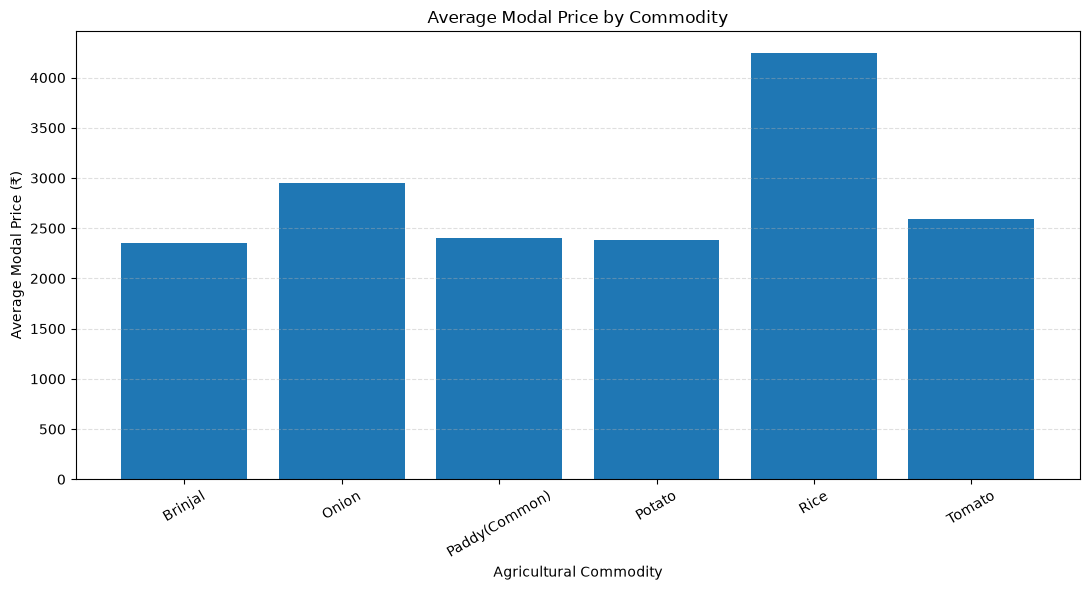

In [80]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

plt.bar(
    commodity_eda["Commodity"],
    commodity_eda["Average_Price"]
)

plt.title("Average Modal Price by Commodity")
plt.xlabel("Agricultural Commodity")
plt.ylabel("Average Modal Price (₹)")
plt.xticks(rotation=30)
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("Phase2_Average_Price_by_Commodity.png", dpi=300)
plt.show()

In [81]:
# Inspect all 8 flagged records with their variety and grade details

display(
    source_conflict_records[
        [
            "Arrival_Date",
            "Commodity",
            "Market",
            "Variety",
            "Grade",
            "Min_Price",
            "Max_Price",
            "Modal_Price"
        ]
    ].sort_values(
        ["Arrival_Date", "Commodity", "Market"]
    )
)

,Arrival_Date,Commodity,Market,Variety,Grade,Min_Price,Max_Price,Modal_Price
4756,2026-05-30,Rice,Mysuru APMC,Fine,Local,2320,8000,5500
6725,2026-05-30,Rice,Mysuru APMC,Fine,Local,2320,7750,2400
881,2026-08-16,Paddy(Common),K.R.Nagar APMC,Paddy Dappa,FAQ,2000,2500,2340
1262,2026-08-16,Paddy(Common),K.R.Nagar APMC,Paddy Dappa,FAQ,2000,2000,2000
895,2026-08-16,Tender Coconut,K.R.Nagar APMC,Tender Coconut,Small,20000,25000,21000
1250,2026-08-16,Tender Coconut,K.R.Nagar APMC,Tender Coconut,Small,19000,25000,20000
214,2026-10-08,Maize,Hunsur APMC,Local,FAQ,1800,1800,1800
269,2026-10-08,Maize,Hunsur APMC,Local,FAQ,1800,2000,2000


In [82]:
# Preserve the complete cleaned dataset
phase2_full_prices = cleaned_prices.copy()

# Keep flagged records separately for audit
phase2_conflict_review = source_conflict_records.copy()

# Exclude only the flagged records from the analysis dataset
phase2_analysis_prices = cleaned_prices.drop(
    index=source_conflict_records.index
).copy()

print("PHASE 2 DATASET VALIDATION")
print("Full cleaned records:", len(phase2_full_prices))
print("Flagged records:", len(phase2_conflict_review))
print("Records available for analysis:", len(phase2_analysis_prices))

# Save separate files
phase2_full_prices.to_csv("Phase2_Full_Cleaned_Prices.csv", index=False)
phase2_conflict_review.to_csv("Phase2_Source_Conflict_Audit.csv", index=False)
phase2_analysis_prices.to_csv("Phase2_Analysis_Ready_Prices.csv", index=False)

KeyError: '[4756, 6725] not found in axis'

In [83]:
# Find columns shared by both datasets
match_cols = [
    col for col in cleaned_prices.columns
    if col in source_conflict_records.columns
]

print("Columns used for matching:", match_cols)

# Match complete records by their values, not their index
matched_records = cleaned_prices.merge(
    source_conflict_records[match_cols].drop_duplicates(),
    on=match_cols,
    how="inner"
)

print("Full cleaned dataset:", len(cleaned_prices))
print("Flagged source records:", len(source_conflict_records))
print("Exact matching records found:", len(matched_records))

Columns used for matching: ['Arrival_Date', 'Commodity', 'Market', 'Variety', 'Grade', 'Commodity_Code', 'District', 'State', 'Min_Price', 'Max_Price', 'Modal_Price']
Full cleaned dataset: 2428
Flagged source records: 8
Exact matching records found: 0


In [84]:
# Preserve the full cleaned dataset
phase2_full_prices = cleaned_prices.copy()

# Use the previously validated analysis dataset
phase2_analysis_prices = analysis_prices.copy()

# Keep source conflicts separately
phase2_conflict_review = source_conflict_records.copy()

print("PHASE 2 DATASET VALIDATION")
print("Full cleaned prices:", phase2_full_prices.shape)
print("Analysis-ready prices:", phase2_analysis_prices.shape)
print("Source conflict records:", phase2_conflict_review.shape)

# Save the three separate files
phase2_full_prices.to_csv(
    "Phase2_Full_Cleaned_Prices.csv", index=False
)

phase2_analysis_prices.to_csv(
    "Phase2_Analysis_Ready_Prices.csv", index=False
)

phase2_conflict_review.to_csv(
    "Phase2_Source_Conflict_Audit.csv", index=False
)

PHASE 2 DATASET VALIDATION
Full cleaned prices: (2428, 12)
Analysis-ready prices: (2427, 12)
Source conflict records: (8, 14)


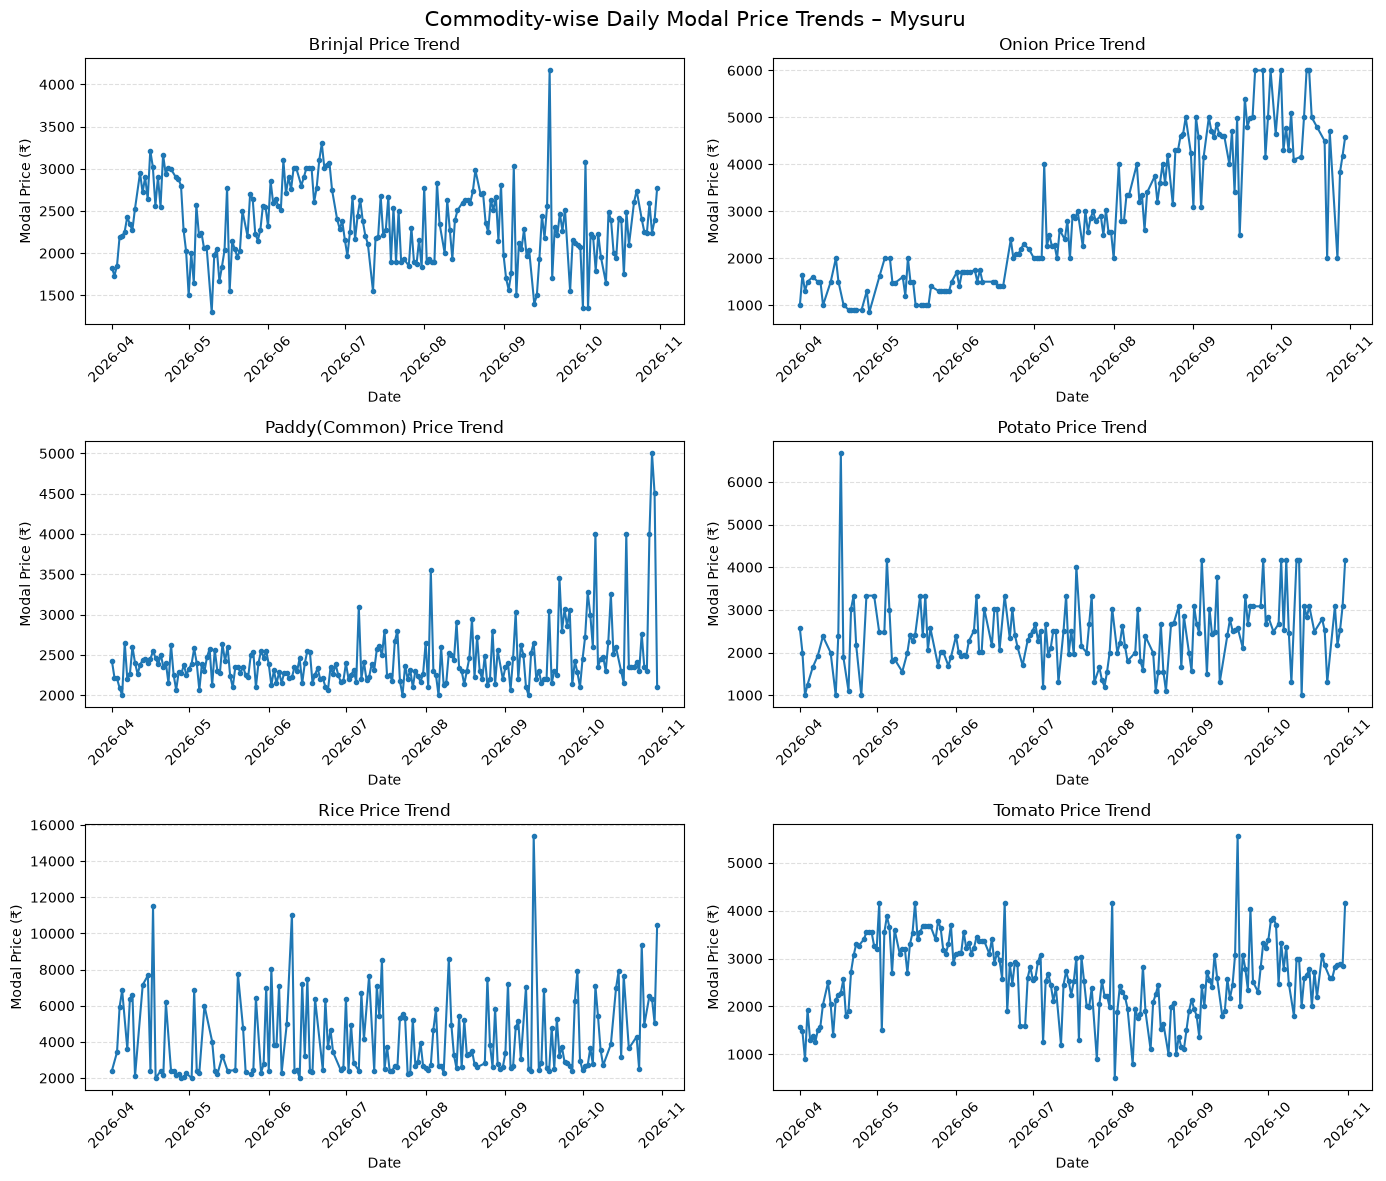

Price trend visualisation saved successfully!


In [85]:
import pandas as pd
import matplotlib.pyplot as plt

# Prepare date column
phase2_analysis_prices["Arrival_Date"] = pd.to_datetime(
    phase2_analysis_prices["Arrival_Date"]
)

# Calculate average modal price for each commodity on each date
daily_prices = (
    phase2_analysis_prices
    .groupby(["Arrival_Date", "Commodity"])["Modal_Price"]
    .mean()
    .reset_index()
)

# Create separate trend plots for each commodity
commodities = sorted(daily_prices["Commodity"].unique())

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
axes = axes.flatten()

for i, commodity in enumerate(commodities):
    data = daily_prices[daily_prices["Commodity"] == commodity]

    axes[i].plot(
        data["Arrival_Date"],
        data["Modal_Price"],
        marker="o",
        markersize=3
    )

    axes[i].set_title(f"{commodity} Price Trend")
    axes[i].set_xlabel("Date")
    axes[i].set_ylabel("Modal Price (₹)")
    axes[i].tick_params(axis="x", rotation=45)
    axes[i].grid(axis="y", linestyle="--", alpha=0.4)

plt.suptitle(
    "Commodity-wise Daily Modal Price Trends – Mysuru",
    fontsize=15
)

plt.tight_layout()
plt.savefig("Phase2_Commodity_Price_Trends.png", dpi=300)
plt.show()

print("Price trend visualisation saved successfully!")

<Figure size 1100x600 with 0 Axes>

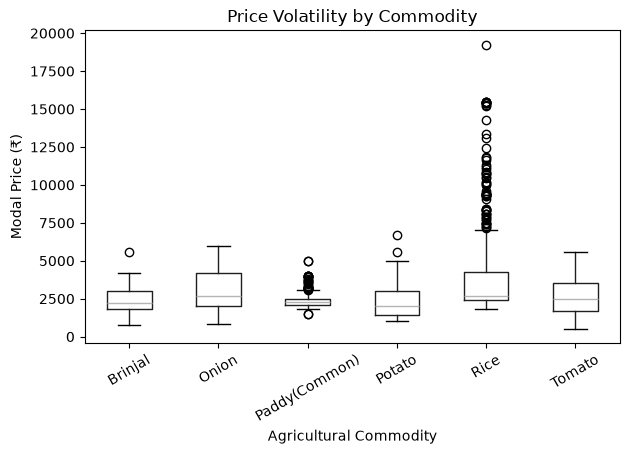

Price volatility graph saved successfully!


In [86]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

phase2_analysis_prices.boxplot(
    column="Modal_Price",
    by="Commodity",
    grid=False
)

plt.title("Price Volatility by Commodity")
plt.suptitle("")
plt.xlabel("Agricultural Commodity")
plt.ylabel("Modal Price (₹)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.savefig("Phase2_Price_Volatility.png", dpi=300)
plt.show()

print("Price volatility graph saved successfully!")

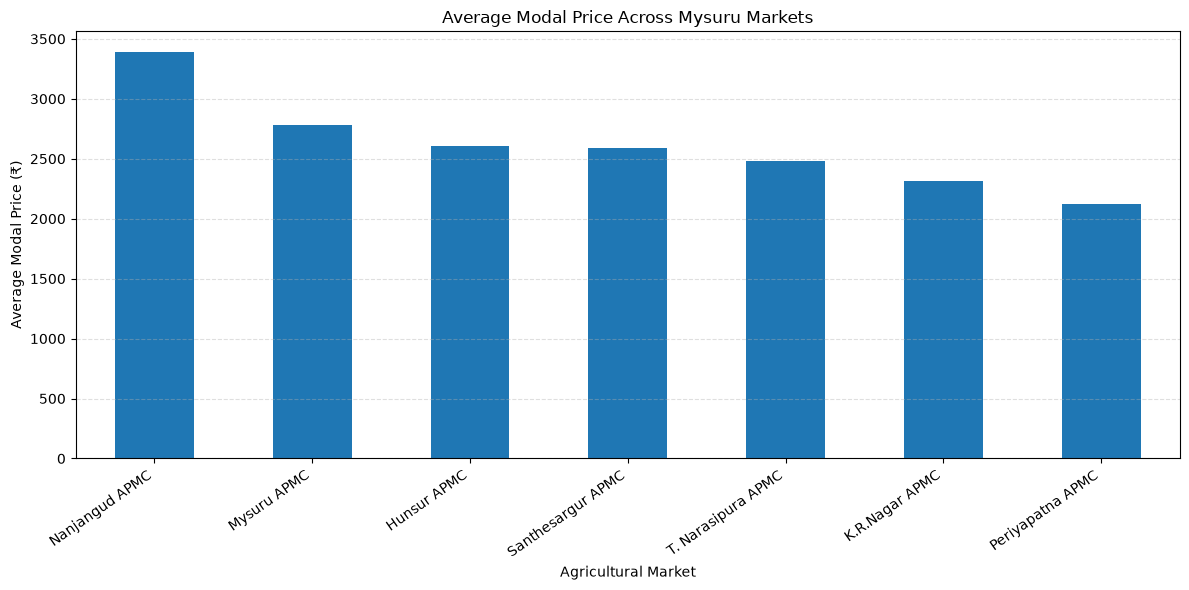

Market-wise comparison saved successfully!


In [87]:
import matplotlib.pyplot as plt

market_prices = (
    phase2_analysis_prices
    .groupby("Market")["Modal_Price"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

market_prices.plot(kind="bar")

plt.title("Average Modal Price Across Mysuru Markets")
plt.xlabel("Agricultural Market")
plt.ylabel("Average Modal Price (₹)")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.savefig("Phase2_Market_Wise_Price_Comparison.png", dpi=300)
plt.show()

print("Market-wise comparison saved successfully!")

In [88]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.scatter(
    phase2_combined_data["Arrivals"],
    phase2_combined_data["Modal_Price"],
    alpha=0.7
)

plt.title("Relationship Between Agricultural Arrivals and Modal Prices")
plt.xlabel("Arrivals (Tonnes)")
plt.ylabel("Modal Price (₹)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("Phase2_Arrivals_vs_Prices.png", dpi=300)
plt.show()

print("Arrivals vs prices graph saved successfully!")

KeyError: 'Arrivals'

<Figure size 1000x600 with 0 Axes>

In [89]:
print(phase2_combined_data.columns.tolist())

['Arrival_Date', 'Commodity', 'Market', 'Variety', 'Grade', 'Commodity_Code', 'District', 'State', 'Min_Price', 'Max_Price', 'Modal_Price', 'Price_Quality', 'date', 'commodity', 'state', 'district', 'market', 'mkt_id', 'arrival_t', 'modal_price_rs_qtl', 'arrival_review']


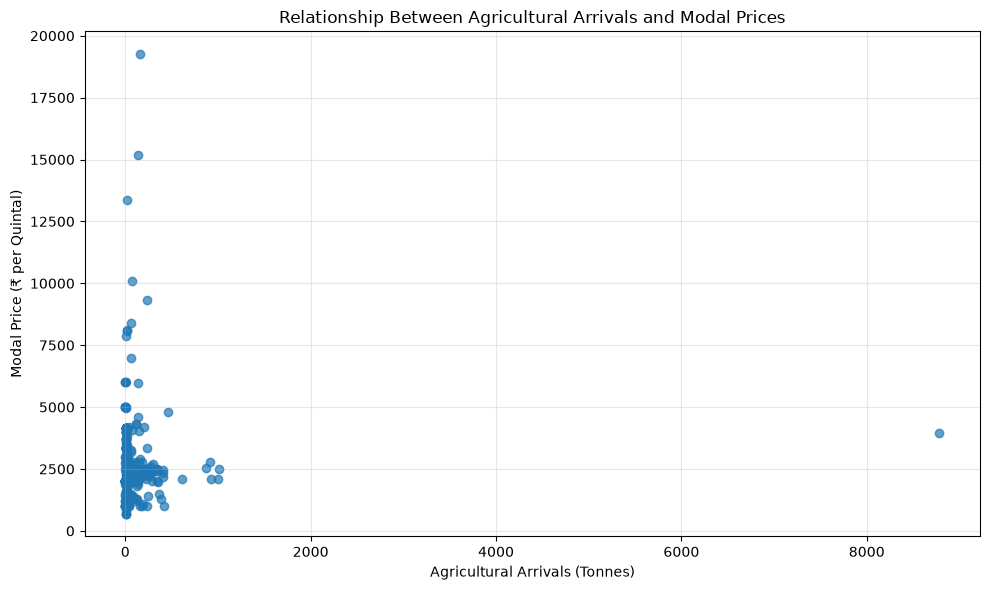

Arrivals vs Prices graph saved successfully!
Records plotted: 299


In [90]:
import matplotlib.pyplot as plt
import pandas as pd

# Prepare data for the graph
plot_data = phase2_combined_data[
    ["arrival_t", "Modal_Price"]
].copy()

plot_data["arrival_t"] = pd.to_numeric(
    plot_data["arrival_t"], errors="coerce"
)

plot_data["Modal_Price"] = pd.to_numeric(
    plot_data["Modal_Price"], errors="coerce"
)

plot_data = plot_data.dropna()

# Create scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(
    plot_data["arrival_t"],
    plot_data["Modal_Price"],
    alpha=0.7
)

plt.title("Relationship Between Agricultural Arrivals and Modal Prices")
plt.xlabel("Agricultural Arrivals (Tonnes)")
plt.ylabel("Modal Price (₹ per Quintal)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("Phase2_Arrivals_vs_Prices.png", dpi=300)
plt.show()

print("Arrivals vs Prices graph saved successfully!")
print("Records plotted:", len(plot_data))

In [91]:
# Overall correlation
print("OVERALL CORRELATION")
print(
    phase2_combined_data[
        ["arrival_t", "Modal_Price"]
    ].corr(method="pearson")
)

# Correlation separately for each commodity
print("\nCOMMODITY-WISE CORRELATION")

for commodity, group in phase2_combined_data.groupby("Commodity"):
    correlation = group["arrival_t"].corr(
        group["Modal_Price"], method="pearson"
    )
    print(commodity, ":", round(correlation, 3))

# Inspect the 10 highest arrival values
print("\nHIGHEST ARRIVAL RECORDS")

display(
    phase2_combined_data.nlargest(10, "arrival_t")[
        ["Arrival_Date", "Commodity", "Market",
         "arrival_t", "Modal_Price"]
    ]
)

OVERALL CORRELATION
             arrival_t  Modal_Price
arrival_t     1.000000     0.019728
Modal_Price   0.019728     1.000000

COMMODITY-WISE CORRELATION
Onion : -0.189
Paddy(Common) : 0.014
Potato : -0.506
Rice : -0.018
Tomato : -0.042

HIGHEST ARRIVAL RECORDS


,Arrival_Date,Commodity,Market,arrival_t,Modal_Price
64,2026-05-30,Rice,Mysuru APMC,8782.7,3950.0
138,2026-07-17,Paddy(Common),T. Narasipura APMC,1012.2,2500.0
105,2026-06-23,Paddy(Common),T. Narasipura APMC,995.5,2100.0
125,2026-07-05,Paddy(Common),T. Narasipura APMC,923.6,2100.0
88,2026-06-11,Paddy(Common),T. Narasipura APMC,918.7,2800.0
97,2026-06-17,Paddy(Common),T. Narasipura APMC,868.2,2550.0
114,2026-06-29,Paddy(Common),T. Narasipura APMC,606.9,2100.0
246,2026-09-21,Onion,Mysuru APMC,464.9,4800.0
14,2026-04-18,Onion,Mysuru APMC,420.2,1000.0
31,2026-04-30,Rice,Santhesargur APMC,407.7,2350.0


In [92]:
# Inspect the highest arrival values
print("TOP 15 HIGHEST ARRIVAL VALUES")

display(
    phase2_combined_data
    .sort_values("arrival_t", ascending=False)
    [[
        "Arrival_Date",
        "Commodity",
        "Market",
        "arrival_t",
        "Modal_Price"
    ]]
    .head(15)
)

# Check basic arrival statistics
print("\nARRIVAL STATISTICS")

display(
    phase2_combined_data["arrival_t"].describe()
)

TOP 15 HIGHEST ARRIVAL VALUES


,Arrival_Date,Commodity,Market,arrival_t,Modal_Price
64,2026-05-30,Rice,Mysuru APMC,8782.7,3950.0
138,2026-07-17,Paddy(Common),T. Narasipura APMC,1012.2,2500.0
105,2026-06-23,Paddy(Common),T. Narasipura APMC,995.5,2100.0
125,2026-07-05,Paddy(Common),T. Narasipura APMC,923.6,2100.0
88,2026-06-11,Paddy(Common),T. Narasipura APMC,918.7,2800.0
97,2026-06-17,Paddy(Common),T. Narasipura APMC,868.2,2550.0
114,2026-06-29,Paddy(Common),T. Narasipura APMC,606.9,2100.0
246,2026-09-21,Onion,Mysuru APMC,464.9,4800.0
14,2026-04-18,Onion,Mysuru APMC,420.2,1000.0
32,2026-04-30,Rice,Santhesargur APMC,407.7,2440.0



ARRIVAL STATISTICS


count     299.000000
mean      111.276254
std       525.395519
min         0.200000
25%         4.000000
50%        19.000000
75%       100.000000
max      8782.700000
Name: arrival_t, dtype: float64

In [93]:
# Inspect the record with the highest arrival quantity

highest_arrival = phase2_combined_data[
    phase2_combined_data["arrival_t"] ==
    phase2_combined_data["arrival_t"].max()
]

print("FULL DETAILS OF HIGHEST ARRIVAL RECORD")

display(highest_arrival.T)

# Inspect the next 5 highest records
print("\nNEXT 5 HIGHEST ARRIVAL RECORDS")

display(
    phase2_combined_data
    .sort_values("arrival_t", ascending=False)
    .iloc[1:6]
    .T
)

FULL DETAILS OF HIGHEST ARRIVAL RECORD


,64
Arrival_Date,2026-05-30
Commodity,Rice
Market,Mysuru APMC
Variety,Fine
Grade,Local
Commodity_Code,3
District,Mysuru
State,Karnataka
Min_Price,2320.0
Max_Price,7875.0



NEXT 5 HIGHEST ARRIVAL RECORDS


,138,105,125,88,97
Arrival_Date,2026-07-17,2026-06-23,2026-07-05,2026-06-11,2026-06-17
Commodity,Paddy(Common),Paddy(Common),Paddy(Common),Paddy(Common),Paddy(Common)
Market,T. Narasipura APMC,T. Narasipura APMC,T. Narasipura APMC,T. Narasipura APMC,T. Narasipura APMC
Variety,Jaya,Paddy,Paddy,Paddy,Paddy
Grade,Non-FAQ,Non-FAQ,Non-FAQ,Non-FAQ,Non-FAQ
Commodity_Code,2,2,2,2,2
District,Mysuru,Mysuru,Mysuru,Mysuru,Mysuru
State,Karnataka,Karnataka,Karnataka,Karnataka,Karnataka
Min_Price,2000.0,2000.0,1900.0,2000.0,1910.0
Max_Price,3250.0,3080.0,3300.0,3050.0,2900.0


In [94]:
# Check all records with unusually high arrivals

display(
    phase2_combined_data[
        phase2_combined_data["arrival_t"] > 1000
    ][[
        "Arrival_Date",
        "Commodity",
        "Market",
        "arrival_t",
        "Modal_Price",
        "arrival_review"
    ]]
)

,Arrival_Date,Commodity,Market,arrival_t,Modal_Price,arrival_review
64,2026-05-30,Rice,Mysuru APMC,8782.7,3950.0,Review
138,2026-07-17,Paddy(Common),T. Narasipura APMC,1012.2,2500.0,Review


In [95]:
# Inspect complete details of unusually high arrival records

high_arrival_records = phase2_combined_data[
    phase2_combined_data["arrival_t"] > 1000
]

display(high_arrival_records.T)

,64,138
Arrival_Date,2026-05-30,2026-07-17
Commodity,Rice,Paddy(Common)
Market,Mysuru APMC,T. Narasipura APMC
Variety,Fine,Jaya
Grade,Local,Non-FAQ
Commodity_Code,3,2
District,Mysuru,Mysuru
State,Karnataka,Karnataka
Min_Price,2320.0,2000.0
Max_Price,7875.0,3250.0


In [96]:
# Compare unusually high arrivals with normal arrivals
for _, row in high_arrival_records.iterrows():

    commodity = row["Commodity"]
    market = row["Market"]

    comparison = phase2_combined_data[
        (phase2_combined_data["Commodity"] == commodity) &
        (phase2_combined_data["Market"] == market)
    ]

    print("\nCommodity:", commodity)
    print("Market:", market)
    print("Flagged arrival:", row["arrival_t"])

    print("Median arrival for this commodity and market:",
          comparison["arrival_t"].median())

    print("Maximum arrival for this commodity and market:",
          comparison["arrival_t"].max())


Commodity: Rice
Market: Mysuru APMC
Flagged arrival: 8782.7
Median arrival for this commodity and market: 98.0
Maximum arrival for this commodity and market: 8782.7

Commodity: Paddy(Common)
Market: T. Narasipura APMC
Flagged arrival: 1012.2
Median arrival for this commodity and market: 151.5
Maximum arrival for this commodity and market: 1012.2


In [97]:
# Inspect arrival-related columns
print("ARRIVAL COLUMN INFORMATION")

for col in phase2_combined_data.columns:
    if "arrival" in col.lower():
        print("\nColumn:", col)
        print("Data type:", phase2_combined_data[col].dtype)

display(
    phase2_combined_data[
        ["Arrival_Date", "Commodity", "Market",
         "arrival_t", "Modal_Price", "arrival_review"]
    ].head(10)
)

ARRIVAL COLUMN INFORMATION

Column: Arrival_Date
Data type: str

Column: arrival_t
Data type: float64

Column: arrival_review
Data type: str


,Arrival_Date,Commodity,Market,arrival_t,Modal_Price,arrival_review
0,2026-04-06,Onion,Mysuru APMC,30.5,1200.0,Normal
1,2026-04-06,Onion,T. Narasipura APMC,4.9,2000.0,Normal
2,2026-04-06,Paddy(Common),K.R.Nagar APMC,13.0,2000.0,Normal
3,2026-04-06,Paddy(Common),Mysuru APMC,0.2,2760.0,Normal
4,2026-04-06,Paddy(Common),T. Narasipura APMC,64.0,3200.0,Normal
5,2026-04-06,Potato,Mysuru APMC,24.0,1100.0,Normal
6,2026-04-06,Potato,Nanjangud APMC,19.0,1851.0,Normal
7,2026-04-06,Potato,T. Narasipura APMC,1.8,2000.0,Normal
8,2026-04-06,Tomato,Mysuru APMC,12.7,1300.0,Normal
9,2026-04-06,Tomato,Nanjangud APMC,20.0,1851.0,Normal


In [98]:
# Count arrival review categories

print("ARRIVAL REVIEW SUMMARY")

print(
    phase2_combined_data["arrival_review"]
    .value_counts(dropna=False)
)

print("\nREVIEW RECORDS")

display(
    phase2_combined_data[
        phase2_combined_data["arrival_review"] == "Review"
    ][
        ["Arrival_Date", "Commodity", "Market",
         "arrival_t", "Modal_Price", "arrival_review"]
    ]
)

ARRIVAL REVIEW SUMMARY
arrival_review
Normal    292
Review      7
Name: count, dtype: int64

REVIEW RECORDS


,Arrival_Date,Commodity,Market,arrival_t,Modal_Price,arrival_review
64,2026-05-30,Rice,Mysuru APMC,8782.7,3950.0,Review
88,2026-06-11,Paddy(Common),T. Narasipura APMC,918.7,2800.0,Review
97,2026-06-17,Paddy(Common),T. Narasipura APMC,868.2,2550.0,Review
105,2026-06-23,Paddy(Common),T. Narasipura APMC,995.5,2100.0,Review
114,2026-06-29,Paddy(Common),T. Narasipura APMC,606.9,2100.0,Review
125,2026-07-05,Paddy(Common),T. Narasipura APMC,923.6,2100.0,Review
138,2026-07-17,Paddy(Common),T. Narasipura APMC,1012.2,2500.0,Review


In [99]:
# Summarise all records requiring review

review_summary = (
    phase2_combined_data[
        phase2_combined_data["arrival_review"] == "Review"
    ]
    .groupby("Commodity")
    .agg(
        Review_Records=("arrival_t", "count"),
        Average_Arrival=("arrival_t", "mean"),
        Maximum_Arrival=("arrival_t", "max"),
        Average_Price=("Modal_Price", "mean")
    )
    .round(2)
)

display(review_summary)

,Review_Records,Average_Arrival,Maximum_Arrival,Average_Price
Commodity,,,,
Paddy(Common),6,887.52,1012.2,2358.33
Rice,1,8782.70,8782.7,3950.00


In [100]:
display(
    phase2_combined_data[
        phase2_combined_data["arrival_review"] == "Review"
    ][
        ["Arrival_Date", "Commodity", "Market",
         "arrival_t", "modal_price_rs_qtl", "arrival_review"]
    ].sort_values(["Commodity", "Arrival_Date"])
)

,Arrival_Date,Commodity,Market,arrival_t,modal_price_rs_qtl,arrival_review
88,2026-06-11,Paddy(Common),T. Narasipura APMC,918.7,2800.0,Review
97,2026-06-17,Paddy(Common),T. Narasipura APMC,868.2,2550.0,Review
105,2026-06-23,Paddy(Common),T. Narasipura APMC,995.5,2100.0,Review
114,2026-06-29,Paddy(Common),T. Narasipura APMC,606.9,2100.0,Review
125,2026-07-05,Paddy(Common),T. Narasipura APMC,923.6,2100.0,Review
138,2026-07-17,Paddy(Common),T. Narasipura APMC,1012.2,2500.0,Review
64,2026-05-30,Rice,Mysuru APMC,8782.7,2400.0,Review


In [101]:
import pandas as pd

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(name, obj.shape)

raw_prices (13303, 11)
cleaned_prices (2428, 12)
arrivals (15, 12)
combined (299, 21)
df (2428, 12)
invalid_prices (0, 12)
raw_check (13303, 11)
match (1, 11)
raw_compare (13303, 11)
clean_compare (2428, 12)
comparison (33, 21)
changed_records (400, 12)
raw_full (13303, 11)
clean_full (2428, 12)
accurate_comparison (341, 14)
changed_accurately (226, 14)
duplicate_groups (0, 6)
example_records (2, 11)
group (68, 21)
raw (13303, 11)
clean (2428, 12)
exact_duplicates (4846, 11)
repeated_keys (4, 6)
summary (7, 2)
audit (5, 3)
repeated_records (15, 11)
analysis_prices (2427, 12)
commodity_summary (6, 5)
market_summary (7, 2)
repeated (4, 6)
cleaned_repeated (0, 6)
invalid_prices_cleaned (1, 12)
arrivals_audit (15, 12)
arrivals_check (15, 12)
variety_df (13483, 11)
invalid_min_modal (21, 11)
price_pattern_check (8, 6)
variety_audited (13483, 14)
records_for_review (21, 8)
repeated_prices (5810, 9)
duplicate_daily (114, 12)
duplicate_daily_corrected (8, 12)
duplicate_details (8, 12)
conflict

In [102]:
for name in ["arrivals", "additional_records"]:
    df = globals()[name]

    print("\nDATAFRAME:", name)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    display(df.head(5))


DATAFRAME: arrivals
Shape: (15, 12)
Columns: ['Commodity', 'Arrivals', 'Unit of Arrivals', 'Variety', 'Grade', 'Minimum Price', 'Maximum Price', 'Modal Price', 'Unit of Price', 'Report_Date', 'Market', 'State']


,Commodity,Arrivals,Unit of Arrivals,Variety,Grade,Minimum Price,Maximum Price,Modal Price,Unit of Price,Report_Date,Market,State
0,Apple,9.5,Metric Tonnes,Kasmir/Shimla - II,Medium,17360.0,17730.0,17500.0,Rs./Quintal,2026-10-30,Mysuru APMC,Karnataka
1,Black Gram Dal(Urd Dal),1.5,Metric Tonnes,Black Gram Dal,Local,12400.0,12400.0,12400.0,Rs./Quintal,2026-10-30,Mysuru APMC,Karnataka
2,Corriander seed,6.0,Metric Tonnes,Coriander Seed,Local,10539.0,10539.0,10539.0,Rs./Quintal,2026-10-30,Mysuru APMC,Karnataka
3,Cowpea(Lobia/Karamani),0.6,Metric Tonnes,Cowpea (Whole),Local,11000.0,11000.0,11000.0,Rs./Quintal,2026-10-30,Mysuru APMC,Karnataka
4,Grapes,0.8,Metric Tonnes,Green,Medium,8375.0,8375.0,8375.0,Rs./Quintal,2026-10-30,Mysuru APMC,Karnataka



DATAFRAME: additional_records
Shape: (180, 12)
Columns: ['Arrival_Date', 'Commodity', 'Commodity_Code', 'District', 'Grade', 'Market', 'Max_Price', 'Min_Price', 'Modal_Price', 'State', 'Variety', '_merge']


,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety,_merge
112,2026-11-05,Tender Coconut,200,Mysuru,Medium,Hunsur APMC,20000,20000,20000,Karnataka,Tender Coconut,left_only
117,2026-11-05,Maize,4,Mysuru,FAQ,Hunsur APMC,1800,1800,1800,Karnataka,Local,left_only
120,2026-11-04,White Pumpkin,158,Mysuru,Medium,Hunsur APMC,1665,1665,1665,Karnataka,White Pumpkin,left_only
122,2026-11-04,Tomato,78,Mysuru,Medium,Hunsur APMC,2400,1666,2400,Karnataka,Tomato,left_only
133,2026-11-04,Green Chilli,87,Mysuru,Medium,Hunsur APMC,2500,2500,2500,Karnataka,Green Chilly,left_only


In [103]:
for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        arrival_cols = [
            col for col in obj.columns
            if "arrival" in str(col).lower()
        ]

        if arrival_cols:
            print("\nDataFrame:", name)
            print("Shape:", obj.shape)
            print("Arrival columns:", arrival_cols)


DataFrame: raw_prices
Shape: (13303, 11)
Arrival columns: ['Arrival_Date']

DataFrame: cleaned_prices
Shape: (2428, 12)
Arrival columns: ['Arrival_Date']

DataFrame: arrivals
Shape: (15, 12)
Arrival columns: ['Arrivals', 'Unit of Arrivals']

DataFrame: combined
Shape: (299, 21)
Arrival columns: ['Arrival_Date', 'arrival_t', 'arrival_review']

DataFrame: df
Shape: (180, 12)
Arrival columns: ['Arrival_Date']

DataFrame: invalid_prices
Shape: (0, 12)
Arrival columns: ['Arrivals', 'Unit of Arrivals']

DataFrame: raw_check
Shape: (13303, 11)
Arrival columns: ['Arrival_Date']

DataFrame: match
Shape: (1, 11)
Arrival columns: ['Arrival_Date']

DataFrame: raw_compare
Shape: (13303, 11)
Arrival columns: ['Arrival_Date']

DataFrame: clean_compare
Shape: (2428, 12)
Arrival columns: ['Arrival_Date']

DataFrame: comparison
Shape: (33, 21)
Arrival columns: ['Arrival_Date', 'arrival_t', 'arrival_review']

DataFrame: changed_records
Shape: (400, 12)
Arrival columns: ['Arrival_Date']

DataFrame: raw_f

In [104]:
for name in ["arrivals", "additional_records"]:
    df = globals()[name]

    print("\nDATAFRAME:", name)
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())

    if "Arrival_Date" in df.columns:
        print("Date range:",
              df["Arrival_Date"].min(),
              "to",
              df["Arrival_Date"].max())

    if "Report_Date" in df.columns:
        print("Report date range:",
              df["Report_Date"].min(),
              "to",
              df["Report_Date"].max())


DATAFRAME: arrivals
Shape: (15, 12)
Columns: ['Commodity', 'Arrivals', 'Unit of Arrivals', 'Variety', 'Grade', 'Minimum Price', 'Maximum Price', 'Modal Price', 'Unit of Price', 'Report_Date', 'Market', 'State']
Missing values: 0
Duplicate rows: 0
Report date range: 2026-10-30 to 2026-10-30

DATAFRAME: additional_records
Shape: (180, 12)
Columns: ['Arrival_Date', 'Commodity', 'Commodity_Code', 'District', 'Grade', 'Market', 'Max_Price', 'Min_Price', 'Modal_Price', 'State', 'Variety', '_merge']
Missing values: 0
Duplicate rows: 0
Date range: 2026-10-31 00:00:00 to 2026-11-06 00:00:00


In [105]:
print("PHASE 2 FULL PRICES")
print(phase2_full_prices.columns.tolist())

print("\nADDITIONAL RECORDS")
print(additional_records.columns.tolist())

PHASE 2 FULL PRICES
['Arrival_Date', 'Commodity', 'Market', 'Variety', 'Grade', 'Commodity_Code', 'District', 'State', 'Min_Price', 'Max_Price', 'Modal_Price', 'Price_Quality']

ADDITIONAL RECORDS
['Arrival_Date', 'Commodity', 'Commodity_Code', 'District', 'Grade', 'Market', 'Max_Price', 'Min_Price', 'Modal_Price', 'State', 'Variety', '_merge']


In [106]:
print("MERGE STATUS")
print(additional_records["_merge"].value_counts(dropna=False))

print("\nMERGE COLUMN VALUES")
display(additional_records["_merge"].unique())

print("\nADDITIONAL RECORDS SAMPLE")
display(additional_records.head(10))

MERGE STATUS
_merge
left_only     180
right_only      0
both            0
Name: count, dtype: int64

MERGE COLUMN VALUES


['left_only']
Categories (3, str): ['left_only', 'right_only', 'both']


ADDITIONAL RECORDS SAMPLE


,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety,_merge
112,2026-11-05,Tender Coconut,200,Mysuru,Medium,Hunsur APMC,20000,20000,20000,Karnataka,Tender Coconut,left_only
117,2026-11-05,Maize,4,Mysuru,FAQ,Hunsur APMC,1800,1800,1800,Karnataka,Local,left_only
120,2026-11-04,White Pumpkin,158,Mysuru,Medium,Hunsur APMC,1665,1665,1665,Karnataka,White Pumpkin,left_only
122,2026-11-04,Tomato,78,Mysuru,Medium,Hunsur APMC,2400,1666,2400,Karnataka,Tomato,left_only
133,2026-11-04,Green Chilli,87,Mysuru,Medium,Hunsur APMC,2500,2500,2500,Karnataka,Green Chilly,left_only
253,2026-11-06,Tomato,78,Mysuru,Medium,Hunsur APMC,3332,2000,3332,Karnataka,Tomato,left_only
265,2026-11-04,Tender Coconut,200,Mysuru,Medium,Hunsur APMC,20000,20000,20000,Karnataka,Tender Coconut,left_only
281,2026-11-01,Ginger(Green),103,Mysuru,Medium,Hunsur APMC,2300,2300,2300,Karnataka,Green Ginger,left_only
282,2026-11-04,Ginger(Green),103,Mysuru,Medium,Hunsur APMC,2300,2000,2300,Karnataka,Green Ginger,left_only
414,2026-11-02,Tender Coconut,200,Mysuru,Medium,Hunsur APMC,20000,20000,20000,Karnataka,Tender Coconut,left_only


In [107]:
key_columns = ["Arrival_Date", "Commodity", "Market"]

print("EXISTING DATASET DUPLICATE KEYS:")
print(
    phase2_full_prices.duplicated(
        subset=key_columns
    ).sum()
)

print("\nADDITIONAL DATASET DUPLICATE KEYS:")
print(
    additional_records.duplicated(
        subset=key_columns
    ).sum()
)

print("\nOVERLAPPING RECORDS:")

overlap = additional_records.merge(
    phase2_full_prices[key_columns].drop_duplicates(),
    on=key_columns,
    how="inner"
)

print("Overlapping records:", len(overlap))
display(overlap.head(10))

EXISTING DATASET DUPLICATE KEYS:
269

ADDITIONAL DATASET DUPLICATE KEYS:
2

OVERLAPPING RECORDS:
Overlapping records: 0


,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety,_merge


In [108]:
# Inspect repeated keys in additional records

duplicate_additional = additional_records[
    additional_records.duplicated(
        subset=key_columns,
        keep=False
    )
].sort_values(key_columns)

print("REPEATED ADDITIONAL RECORDS:")
print("Total rows:", len(duplicate_additional))

display(duplicate_additional)

REPEATED ADDITIONAL RECORDS:
Total rows: 4


,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety,_merge
2847,2026-11-04,Rice,3,Mysuru,Local,Mysuru APMC,13703,10230,10627,Karnataka,Basmati,left_only
2856,2026-11-04,Rice,3,Mysuru,Local,Mysuru APMC,10000,4535,9480,Karnataka,Fine,left_only
6368,2026-11-05,Rice,3,Mysuru,Local,Mysuru APMC,10480,10480,10480,Karnataka,Basmati,left_only
6375,2026-11-05,Rice,3,Mysuru,Local,Mysuru APMC,9660,2400,2400,Karnataka,Fine,left_only


In [109]:
# Include Variety when identifying unique market records
key_columns = [
    "Arrival_Date",
    "Commodity",
    "Commodity_Code",
    "District",
    "Grade",
    "Market",
    "Variety"
]

print("EXISTING DATASET DUPLICATE KEYS:")
print(phase2_full_prices.duplicated(subset=key_columns).sum())

print("\nADDITIONAL DATASET DUPLICATE KEYS:")
print(additional_records.duplicated(subset=key_columns).sum())

duplicate_additional = additional_records[
    additional_records.duplicated(
        subset=key_columns,
        keep=False
    )
].sort_values(key_columns)

print("\nREPEATED ADDITIONAL RECORDS:")
print("Total rows:", len(duplicate_additional))
display(duplicate_additional)

EXISTING DATASET DUPLICATE KEYS:
0

ADDITIONAL DATASET DUPLICATE KEYS:
0

REPEATED ADDITIONAL RECORDS:
Total rows: 0


,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety,_merge


In [110]:
print("EXISTING DATASET")
print(phase2_full_prices.dtypes)

print("\nADDITIONAL DATASET")
print(additional_records.dtypes)

print("\nEXISTING COLUMNS")
print(phase2_full_prices.columns.tolist())

print("\nADDITIONAL COLUMNS")
print(additional_records.columns.tolist())

EXISTING DATASET
Arrival_Date      datetime64[us]
Commodity                    str
Market                       str
Variety                      str
Grade                        str
Commodity_Code             int64
District                     str
State                        str
Min_Price                float64
Max_Price                float64
Modal_Price              float64
Price_Quality                str
dtype: object

ADDITIONAL DATASET
Arrival_Date      datetime64[us]
Commodity                    str
Commodity_Code             int64
District                     str
Grade                        str
Market                       str
Max_Price                  int64
Min_Price                  int64
Modal_Price                int64
State                        str
Variety                      str
_merge                  category
dtype: object

EXISTING COLUMNS
['Arrival_Date', 'Commodity', 'Market', 'Variety', 'Grade', 'Commodity_Code', 'District', 'State', 'Min_Price', 'Max_Price', 

In [111]:
print("PRICE QUALITY VALUES:")
print(phase2_full_prices["Price_Quality"].value_counts(dropna=False))

print("\nPRICE QUALITY SAMPLE:")
display(
    phase2_full_prices[
        ["Commodity", "Market", "Min_Price",
         "Max_Price", "Modal_Price", "Price_Quality"]
    ].head(15)
)

PRICE QUALITY VALUES:
Price_Quality
Valid     2427
Review       1
Name: count, dtype: int64

PRICE QUALITY SAMPLE:


,Commodity,Market,Min_Price,Max_Price,Modal_Price,Price_Quality
0,Brinjal,Mysuru APMC,1800.0,2000.0,1900.0,Valid
1,Brinjal,Mysuru APMC,1400.0,1600.0,1500.0,Valid
2,Brinjal,Nanjangud APMC,2083.0,2222.0,2083.0,Valid
3,Onion,Mysuru APMC,700.0,1200.0,1000.0,Valid
4,Paddy(Common),Hunsur APMC,2200.0,2614.0,2588.0,Valid
5,Paddy(Common),K.R.Nagar APMC,2200.0,2200.0,2200.0,Valid
6,Paddy(Common),Periyapatna APMC,2100.0,2750.0,2500.0,Valid
7,Potato,Nanjangud APMC,2380.0,3333.0,2564.0,Valid
8,Rice,Mysuru APMC,2400.0,7477.0,2400.0,Valid
9,Tomato,Mysuru APMC,1200.0,1400.0,1300.0,Valid


In [112]:
review_record = phase2_full_prices[
    phase2_full_prices["Price_Quality"] == "Review"
]

print("RECORD MARKED FOR REVIEW:")
display(review_record)

RECORD MARKED FOR REVIEW:


,Arrival_Date,Commodity,Market,Variety,Grade,Commodity_Code,District,State,Min_Price,Max_Price,Modal_Price,Price_Quality
377,2026-05-08,Paddy(Common),T. Narasipura APMC,Paddy,Non-FAQ,2,Mysuru,Karnataka,2704.0,3000.0,2700.0,Review


In [113]:
# Prepare additional records for appending

additional_clean = additional_records.drop(
    columns=["_merge"],
    errors="ignore"
).copy()

# Convert price columns to a consistent numeric type
price_columns = ["Min_Price", "Max_Price", "Modal_Price"]

for col in price_columns:
    additional_clean[col] = pd.to_numeric(
        additional_clean[col],
        errors="coerce"
    ).astype("float64")

# Assign price quality without deleting questionable records
additional_clean["Price_Quality"] = (
    (additional_clean["Min_Price"] <= additional_clean["Modal_Price"]) &
    (additional_clean["Modal_Price"] <= additional_clean["Max_Price"])
).map({True: "Valid", False: "Review"})

# Append the additional records
phase2_expanded = pd.concat(
    [phase2_full_prices, additional_clean],
    ignore_index=True
)

print("EXISTING RECORDS:", len(phase2_full_prices))
print("ADDITIONAL RECORDS:", len(additional_clean))
print("EXPANDED DATASET:", len(phase2_expanded))

print("\nPRICE QUALITY:")
print(phase2_expanded["Price_Quality"].value_counts(dropna=False))

display(phase2_expanded.tail(10))

EXISTING RECORDS: 2428
ADDITIONAL RECORDS: 180
EXPANDED DATASET: 2608

PRICE QUALITY:
Price_Quality
Valid     2607
Review       1
Name: count, dtype: int64


,Arrival_Date,Commodity,Market,Variety,Grade,Commodity_Code,District,State,Min_Price,Max_Price,Modal_Price,Price_Quality
2598,2026-11-02,Ladies Finger,T. Narasipura APMC,Ladies Finger,Small,155,Mysuru,Karnataka,1500.0,2000.0,2000.0,Valid
2599,2026-10-31,Paddy(Common),T. Narasipura APMC,Paddy,Non-FAQ,2,Mysuru,Karnataka,2300.0,4200.0,3200.0,Valid
2600,2026-11-04,Paddy(Common),T. Narasipura APMC,Paddy,Non-FAQ,2,Mysuru,Karnataka,2300.0,4530.0,2800.0,Valid
2601,2026-10-31,Garlic,T. Narasipura APMC,Garlic,Small,25,Mysuru,Karnataka,7000.0,8500.0,8500.0,Valid
2602,2026-11-01,Maize,T. Narasipura APMC,Yellow,Non-FAQ,4,Mysuru,Karnataka,3350.0,3350.0,3350.0,Valid
2603,2026-10-31,Brinjal,T. Narasipura APMC,Brinjal,Small,35,Mysuru,Karnataka,1500.0,2000.0,2000.0,Valid
2604,2026-11-02,Brinjal,T. Narasipura APMC,Brinjal,Small,35,Mysuru,Karnataka,1500.0,2000.0,2000.0,Valid
2605,2026-11-02,Beetroot,T. Narasipura APMC,Beetroot,Small,157,Mysuru,Karnataka,1500.0,2000.0,2000.0,Valid
2606,2026-10-31,Onion,T. Narasipura APMC,Onion,Small,23,Mysuru,Karnataka,4000.0,5000.0,5000.0,Valid
2607,2026-10-31,Banana - Green,T. Narasipura APMC,Banana - Green,Small,90,Mysuru,Karnataka,4500.0,4600.0,4520.0,Valid


In [114]:
print("EXPANDED DATASET VALIDATION")

print("\nDataset shape:")
print(phase2_expanded.shape)

print("\nMissing values:")
print(phase2_expanded.isnull().sum().sum())

print("\nDuplicate records using key columns:")
print(phase2_expanded.duplicated(subset=key_columns).sum())

print("\nDate range:")
print(phase2_expanded["Arrival_Date"].min())
print(phase2_expanded["Arrival_Date"].max())

print("\nNumber of commodities:")
print(phase2_expanded["Commodity"].nunique())

print("\nNumber of markets:")
print(phase2_expanded["Market"].nunique())

print("\nPrice quality:")
print(phase2_expanded["Price_Quality"].value_counts())

EXPANDED DATASET VALIDATION

Dataset shape:
(2608, 12)

Missing values:
0

Duplicate records using key columns:
0

Date range:
2026-04-01 00:00:00
2026-11-06 00:00:00

Number of commodities:
64

Number of markets:
7

Price quality:
Price_Quality
Valid     2607
Review       1
Name: count, dtype: int64


In [115]:
# Commodity coverage analysis

commodity_summary = (
    phase2_expanded
    .groupby("Commodity")
    .agg(
        Record_Count=("Commodity", "size"),
        Market_Count=("Market", "nunique"),
        First_Date=("Arrival_Date", "min"),
        Last_Date=("Arrival_Date", "max"),
        Average_Modal_Price=("Modal_Price", "mean")
    )
    .sort_values("Record_Count", ascending=False)
)

print("TOTAL COMMODITIES:", len(commodity_summary))

display(commodity_summary)

TOTAL COMMODITIES: 64


,Record_Count,Market_Count,First_Date,Last_Date,Average_Modal_Price
Commodity,,,,,
Brinjal,596,4,2026-04-01,2026-11-05,2351.162752
Paddy(Common),525,7,2026-04-01,2026-11-06,2410.411429
Tomato,429,6,2026-04-01,2026-11-06,2595.778555
Rice,382,6,2026-04-01,2026-11-05,4284.000000
Potato,296,5,2026-04-01,2026-11-05,2395.300676
...,...,...,...,...,...
Mustard,1,1,2026-11-03,2026-11-03,7500.000000
Foxtail Millet(Navane),1,1,2026-11-05,2026-11-05,2300.000000
Knool Khol,1,1,2026-11-02,2026-11-02,3000.000000


In [116]:
# Select five commodities for detailed EDA

focus_commodities = [
    "Brinjal",
    "Paddy(Common)",
    "Tomato",
    "Rice",
    "Potato"
]

eda_data = phase2_expanded[
    phase2_expanded["Commodity"].isin(focus_commodities)
].copy()

print("EDA DATASET SHAPE:", eda_data.shape)

print("\nRECORDS BY COMMODITY:")
print(eda_data["Commodity"].value_counts())

print("\nMARKETS COVERED:")
print(eda_data["Market"].nunique())

print("\nDATE RANGE:")
print(eda_data["Arrival_Date"].min())
print(eda_data["Arrival_Date"].max())

display(eda_data.head(10))

EDA DATASET SHAPE: (2228, 12)

RECORDS BY COMMODITY:
Commodity
Brinjal          596
Paddy(Common)    525
Tomato           429
Rice             382
Potato           296
Name: count, dtype: int64

MARKETS COVERED:
7

DATE RANGE:
2026-04-01 00:00:00
2026-11-06 00:00:00


,Arrival_Date,Commodity,Market,Variety,Grade,Commodity_Code,District,State,Min_Price,Max_Price,Modal_Price,Price_Quality
0,2026-04-01,Brinjal,Mysuru APMC,Brinjal,Grade Range-1,35,Mysuru,Karnataka,1800.0,2000.0,1900.0,Valid
1,2026-04-01,Brinjal,Mysuru APMC,Round,Grade Range-1,35,Mysuru,Karnataka,1400.0,1600.0,1500.0,Valid
2,2026-04-01,Brinjal,Nanjangud APMC,Brinjal,Local,35,Mysuru,Karnataka,2083.0,2222.0,2083.0,Valid
4,2026-04-01,Paddy(Common),Hunsur APMC,Paddy,Local,2,Mysuru,Karnataka,2200.0,2614.0,2588.0,Valid
5,2026-04-01,Paddy(Common),K.R.Nagar APMC,Paddy Dappa,FAQ,2,Mysuru,Karnataka,2200.0,2200.0,2200.0,Valid
6,2026-04-01,Paddy(Common),Periyapatna APMC,Paddy,FAQ,2,Mysuru,Karnataka,2100.0,2750.0,2500.0,Valid
7,2026-04-01,Potato,Nanjangud APMC,Potato,Local,24,Mysuru,Karnataka,2380.0,3333.0,2564.0,Valid
8,2026-04-01,Rice,Mysuru APMC,Fine,Grade Range-1,3,Mysuru,Karnataka,2400.0,7477.0,2400.0,Valid
9,2026-04-01,Tomato,Mysuru APMC,Tomato,Grade Range-1,78,Mysuru,Karnataka,1200.0,1400.0,1300.0,Valid
10,2026-04-01,Tomato,Nanjangud APMC,Tomato,Local,78,Mysuru,Karnataka,1560.0,2222.0,1851.0,Valid


In [117]:
# Create analysis-ready dataset

focus_commodities = [
    "Brinjal",
    "Paddy(Common)",
    "Tomato",
    "Rice",
    "Potato"
]

eda_clean = phase2_expanded[
    (phase2_expanded["Commodity"].isin(focus_commodities)) &
    (phase2_expanded["Price_Quality"] == "Valid")
].copy()

print("ANALYSIS-READY DATASET")
print("Shape:", eda_clean.shape)

print("\nRECORDS BY COMMODITY:")
print(eda_clean["Commodity"].value_counts())

print("\nDATE RANGE:")
print(eda_clean["Arrival_Date"].min())
print(eda_clean["Arrival_Date"].max())

print("\nMISSING VALUES:")
print(eda_clean.isnull().sum().sum())

print("\nDUPLICATE RECORDS:")
print(eda_clean.duplicated().sum())

display(eda_clean.head(10))

ANALYSIS-READY DATASET
Shape: (2227, 12)

RECORDS BY COMMODITY:
Commodity
Brinjal          596
Paddy(Common)    524
Tomato           429
Rice             382
Potato           296
Name: count, dtype: int64

DATE RANGE:
2026-04-01 00:00:00
2026-11-06 00:00:00

MISSING VALUES:
0

DUPLICATE RECORDS:
0


,Arrival_Date,Commodity,Market,Variety,Grade,Commodity_Code,District,State,Min_Price,Max_Price,Modal_Price,Price_Quality
0,2026-04-01,Brinjal,Mysuru APMC,Brinjal,Grade Range-1,35,Mysuru,Karnataka,1800.0,2000.0,1900.0,Valid
1,2026-04-01,Brinjal,Mysuru APMC,Round,Grade Range-1,35,Mysuru,Karnataka,1400.0,1600.0,1500.0,Valid
2,2026-04-01,Brinjal,Nanjangud APMC,Brinjal,Local,35,Mysuru,Karnataka,2083.0,2222.0,2083.0,Valid
4,2026-04-01,Paddy(Common),Hunsur APMC,Paddy,Local,2,Mysuru,Karnataka,2200.0,2614.0,2588.0,Valid
5,2026-04-01,Paddy(Common),K.R.Nagar APMC,Paddy Dappa,FAQ,2,Mysuru,Karnataka,2200.0,2200.0,2200.0,Valid
6,2026-04-01,Paddy(Common),Periyapatna APMC,Paddy,FAQ,2,Mysuru,Karnataka,2100.0,2750.0,2500.0,Valid
7,2026-04-01,Potato,Nanjangud APMC,Potato,Local,24,Mysuru,Karnataka,2380.0,3333.0,2564.0,Valid
8,2026-04-01,Rice,Mysuru APMC,Fine,Grade Range-1,3,Mysuru,Karnataka,2400.0,7477.0,2400.0,Valid
9,2026-04-01,Tomato,Mysuru APMC,Tomato,Grade Range-1,78,Mysuru,Karnataka,1200.0,1400.0,1300.0,Valid
10,2026-04-01,Tomato,Nanjangud APMC,Tomato,Local,78,Mysuru,Karnataka,1560.0,2222.0,1851.0,Valid


In [118]:
# PRICE STATISTICAL ANALYSIS

price_summary = (
    eda_clean.groupby("Commodity")
    .agg(
        Record_Count=("Modal_Price", "count"),
        Average_Price=("Modal_Price", "mean"),
        Median_Price=("Modal_Price", "median"),
        Minimum_Price=("Modal_Price", "min"),
        Maximum_Price=("Modal_Price", "max"),
        Price_Std_Dev=("Modal_Price", "std")
    )
    .round(2)
    .sort_values("Average_Price", ascending=False)
)

print("COMMODITY PRICE STATISTICAL SUMMARY")
display(price_summary)

print("\nHIGHEST AVERAGE PRICE:")
print(price_summary["Average_Price"].idxmax())

print("\nLOWEST AVERAGE PRICE:")
print(price_summary["Average_Price"].idxmin())

print("\nHIGHEST PRICE VARIABILITY:")
print(price_summary["Price_Std_Dev"].idxmax())

COMMODITY PRICE STATISTICAL SUMMARY


,Record_Count,Average_Price,Median_Price,Minimum_Price,Maximum_Price,Price_Std_Dev
Commodity,,,,,,
Rice,382,4284.00,2782.5,1800.0,19250.0,3236.82
Tomato,429,2595.78,2480.0,500.0,5550.0,1148.60
Paddy(Common),524,2409.86,2300.0,1500.0,5000.0,429.17
Potato,296,2395.30,2000.0,1000.0,6666.0,1069.30
Brinjal,596,2351.16,2200.0,800.0,5550.0,774.45



HIGHEST AVERAGE PRICE:
Rice

LOWEST AVERAGE PRICE:
Brinjal

HIGHEST PRICE VARIABILITY:
Rice


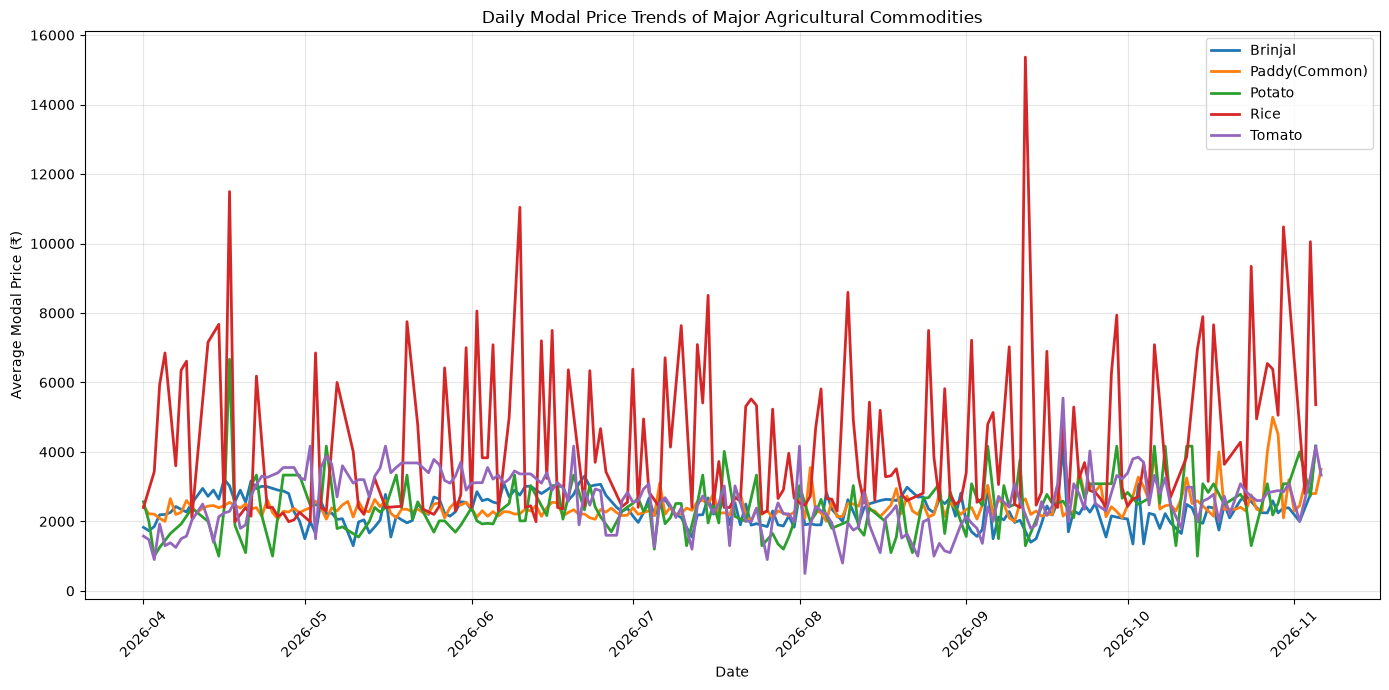

In [119]:
import matplotlib.pyplot as plt
import pandas as pd

# Ensure date is in datetime format
eda_clean["Arrival_Date"] = pd.to_datetime(eda_clean["Arrival_Date"])

# Calculate daily average modal price for each commodity
daily_prices = (
    eda_clean.groupby(["Arrival_Date", "Commodity"])["Modal_Price"]
    .mean()
    .reset_index()
)

# Plot price trends
plt.figure(figsize=(14, 7))

for commodity in daily_prices["Commodity"].unique():
    commodity_data = daily_prices[
        daily_prices["Commodity"] == commodity
    ]

    plt.plot(
        commodity_data["Arrival_Date"],
        commodity_data["Modal_Price"],
        label=commodity,
        linewidth=2
    )

plt.title("Daily Modal Price Trends of Major Agricultural Commodities")
plt.xlabel("Date")
plt.ylabel("Average Modal Price (₹)")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

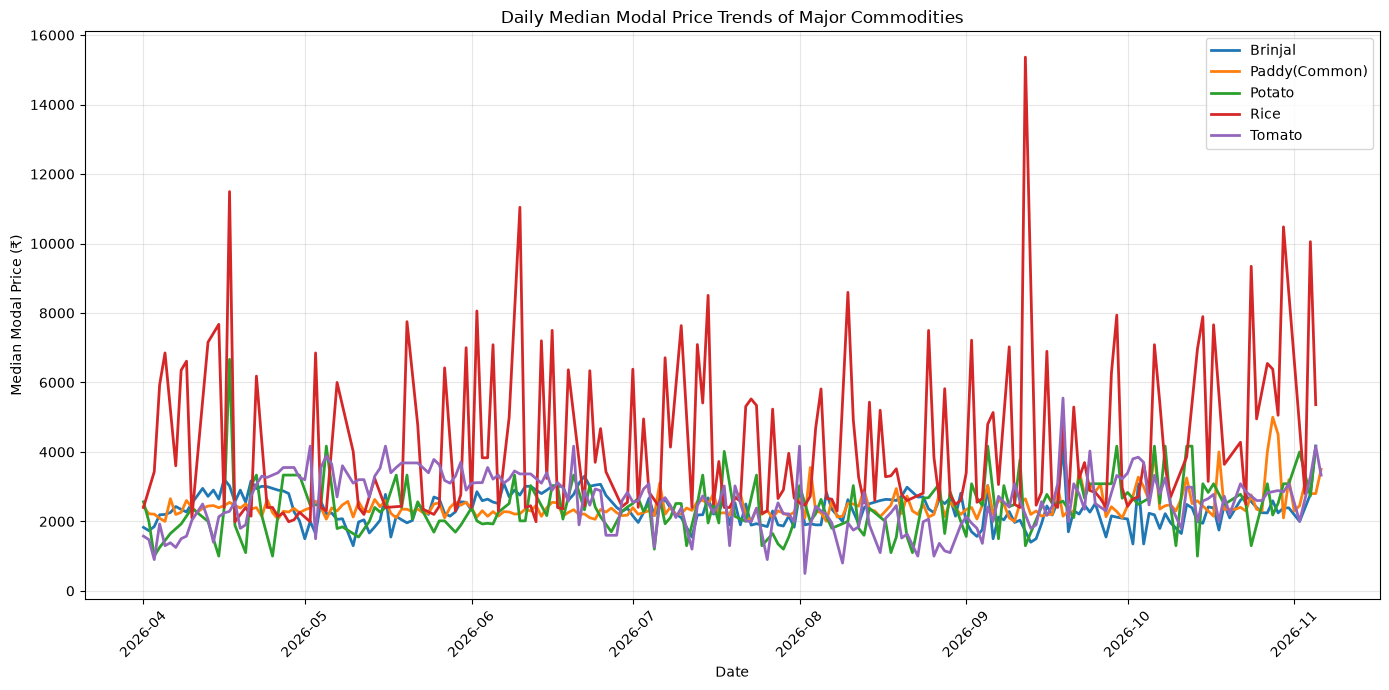

In [120]:
# Aggregate prices by date and commodity
daily_avg = (
    daily_prices
    .groupby(["Arrival_Date", "Commodity"])["Modal_Price"]
    .median()
    .reset_index()
    .sort_values("Arrival_Date")
)

# Plot cleaner price trends
plt.figure(figsize=(14, 7))

for commodity in daily_avg["Commodity"].unique():
    data = daily_avg[daily_avg["Commodity"] == commodity]

    plt.plot(
        data["Arrival_Date"],
        data["Modal_Price"],
        label=commodity,
        linewidth=2
    )

plt.title("Daily Median Modal Price Trends of Major Commodities")
plt.xlabel("Date")
plt.ylabel("Median Modal Price (₹)")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [122]:
# Investigate the highest Rice modal prices

rice_high = (
    eda_clean[eda_clean["Commodity"] == "Rice"]
    .sort_values("Modal_Price", ascending=False)
    [[
        "Arrival_Date",
        "Commodity",
        "Market",
        "Variety",
        "Grade",
        "Min_Price",
        "Max_Price",
        "Modal_Price"
    ]]
)

print("TOP 15 HIGHEST RICE PRICES:")
display(rice_high.head(15))

TOP 15 HIGHEST RICE PRICES:


,Arrival_Date,Commodity,Market,Variety,Grade,Min_Price,Max_Price,Modal_Price
1825,2026-09-09,Rice,Mysuru APMC,Basmati,Local,19250.0,19250.0,19250.0
1119,2026-07-13,Rice,Mysuru APMC,Basmati,Local,15474.0,15474.0,15474.0
1149,2026-07-15,Rice,Mysuru APMC,Basmati,Local,15471.0,15471.0,15471.0
715,2026-06-08,Rice,Mysuru APMC,Basmati,Local,15449.0,15449.0,15449.0
744,2026-06-10,Rice,Mysuru APMC,Basmati,Local,15448.0,15448.0,15448.0
2244,2026-10-14,Rice,Mysuru APMC,Basmati,Local,9140.0,15398.0,15398.0
2054,2026-09-28,Rice,Mysuru APMC,Basmati,Local,15395.0,15395.0,15395.0
1900,2026-09-16,Rice,Mysuru APMC,Basmati,Local,15369.0,15465.0,15369.0
1867,2026-09-12,Rice,Mysuru APMC,Basmati,Local,15366.0,15366.0,15366.0
173,2026-04-17,Rice,Mysuru APMC,Basmati,Grade Range-1,15295.0,15295.0,15295.0


In [123]:
# Rice price analysis by variety and grade

rice_variety_summary = (
    eda_clean[eda_clean["Commodity"] == "Rice"]
    .groupby(["Variety", "Grade"])
    .agg(
        Record_Count=("Modal_Price", "count"),
        Average_Price=("Modal_Price", "mean"),
        Median_Price=("Modal_Price", "median"),
        Minimum_Price=("Modal_Price", "min"),
        Maximum_Price=("Modal_Price", "max")
    )
    .round(2)
    .sort_values("Average_Price", ascending=False)
)

print("RICE VARIETY-WISE PRICE ANALYSIS:")
display(rice_variety_summary)

RICE VARIETY-WISE PRICE ANALYSIS:


Record_Count  Average_Price  Median_Price  Minimum_Price  Maximum_Price
Variety     Grade                                                                                 
Basmati     Local                    34       12348.59       11262.5         9300.0        19250.0
            Grade Range-1             5       11441.60       10824.0         9464.0        15295.0
Dappa       Local                     1        7500.00        7500.0         7500.0         7500.0
Other       Local                     1        5000.00        5000.0         5000.0         5000.0
Fine        Local                   119        4479.84        3831.0         1990.0         9480.0
            Grade Range-1            27        3261.26        2400.0         1990.0         7696.0
Coarse      Small                     1        2950.00        2950.0         2950.0         2950.0
IR 20       Small                    30        2942.33        2940.0         2440.0         3220.0
Coarse      Grade Range-1             1        2920.00        2920.0         2920.0         2920.0
Other       Small                    48        2870.23        2600.0         2500.0         6733.0
Broken Rice Local                    28        2824.82        2690.0         1900.0         6660.0
Other       Medium                    1        2820.00        2820.0         2820.0         2820.0
Dappa       Medium                   16        2652.00        2583.5         2400.0         3000.0
Broken Rice Grade Range-1             2        2550.00        2550.0         2500.0         2600.0
Medium      FAQ                       2        2515.00        2515.0         2380.0         2650.0
Broken Rice Small                    61        2432.87        2400.0         1800.0         3125.0
Coarse      Medium                    1        2300.00        2300.0         2300.0         2300.0
Broken Rice Medium                    4        2170.00        2200.0         2080.0         2200.0

In [124]:
rice_check = eda_clean[eda_clean["Commodity"] == "Rice"].copy()

rice_check = rice_check.sort_values(
    "Modal_Price", ascending=False
)

display(rice_check[
    ["Arrival_Date", "Market", "Variety", "Grade",
     "Min_Price", "Max_Price", "Modal_Price"]
].head(20))

,Arrival_Date,Market,Variety,Grade,Min_Price,Max_Price,Modal_Price
1825,2026-09-09,Mysuru APMC,Basmati,Local,19250.0,19250.0,19250.0
1119,2026-07-13,Mysuru APMC,Basmati,Local,15474.0,15474.0,15474.0
1149,2026-07-15,Mysuru APMC,Basmati,Local,15471.0,15471.0,15471.0
715,2026-06-08,Mysuru APMC,Basmati,Local,15449.0,15449.0,15449.0
744,2026-06-10,Mysuru APMC,Basmati,Local,15448.0,15448.0,15448.0
2244,2026-10-14,Mysuru APMC,Basmati,Local,9140.0,15398.0,15398.0
2054,2026-09-28,Mysuru APMC,Basmati,Local,15395.0,15395.0,15395.0
1900,2026-09-16,Mysuru APMC,Basmati,Local,15369.0,15465.0,15369.0
1867,2026-09-12,Mysuru APMC,Basmati,Local,15366.0,15366.0,15366.0
173,2026-04-17,Mysuru APMC,Basmati,Grade Range-1,15295.0,15295.0,15295.0


In [125]:
market_summary = (
    eda_clean.groupby(["Commodity", "Market"])["Modal_Price"]
    .agg(["mean", "median", "min", "max", "count"])
    .round(2)
    .reset_index()
)

market_summary = market_summary.sort_values(
    ["Commodity", "mean"],
    ascending=[True, False]
)

display(market_summary)

,Commodity,Market,mean,median,min,max,count
1,Brinjal,Nanjangud APMC,3177.31,3030.0,2083.0,5550.0,137
3,Brinjal,T. Narasipura APMC,2280.22,2000.0,2000.0,4000.0,91
0,Brinjal,Mysuru APMC,2065.93,1900.0,800.0,3900.0,364
2,Brinjal,Santhesargur APMC,1625.25,1521.5,1383.0,2075.0,4
10,Paddy(Common),T. Narasipura APMC,2520.37,2400.0,1500.0,5000.0,208
4,Paddy(Common),Hunsur APMC,2486.97,2400.0,2000.0,3310.0,31
7,Paddy(Common),Nanjangud APMC,2466.67,2300.0,2200.0,2950.0,18
6,Paddy(Common),Mysuru APMC,2429.39,2400.0,1501.0,4011.0,72
9,Paddy(Common),Santhesargur APMC,2416.67,2200.0,2000.0,3300.0,12
5,Paddy(Common),K.R.Nagar APMC,2268.66,2200.0,1900.0,4000.0,159


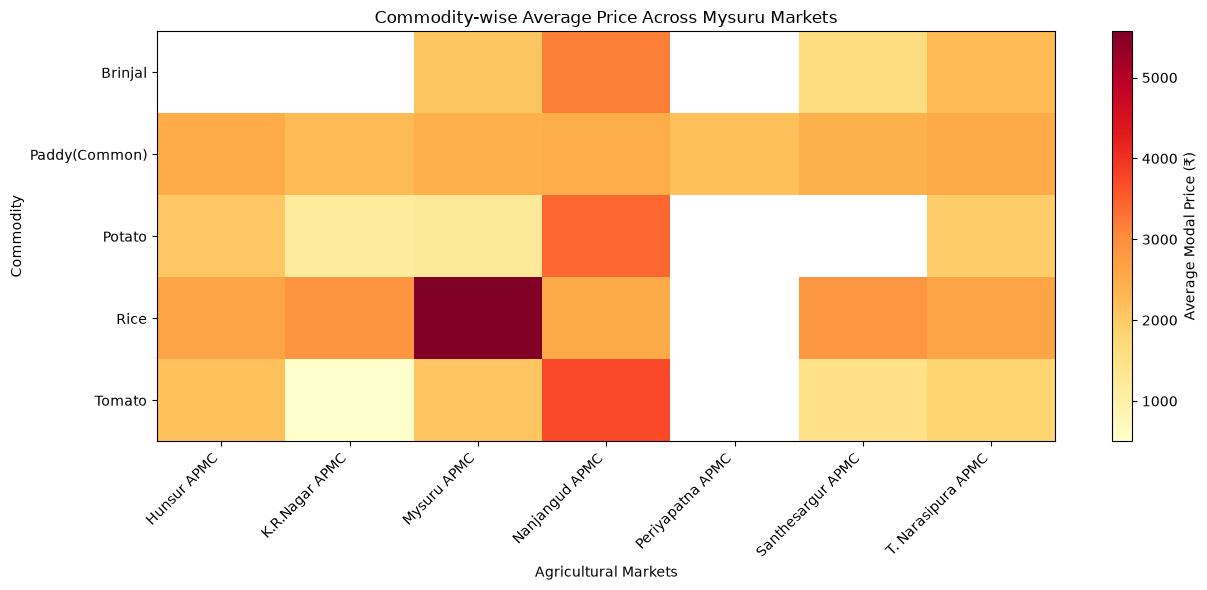

In [126]:
import matplotlib.pyplot as plt

market_pivot = market_summary.pivot(
    index="Commodity",
    columns="Market",
    values="mean"
)

plt.figure(figsize=(13, 6))

plt.imshow(market_pivot, aspect="auto", cmap="YlOrRd")

plt.colorbar(label="Average Modal Price (₹)")

plt.xticks(
    range(len(market_pivot.columns)),
    market_pivot.columns,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(market_pivot.index)),
    market_pivot.index
)

plt.title("Commodity-wise Average Price Across Mysuru Markets")
plt.xlabel("Agricultural Markets")
plt.ylabel("Commodity")

plt.tight_layout()
plt.show()

In [127]:
# Analyse relationship between arrivals and prices

arrival_price = (
    eda_clean.groupby("Commodity")
    .agg(
        Average_Arrivals=("Arrivals", "mean"),
        Average_Price=("Modal_Price", "mean"),
        Total_Records=("Modal_Price", "count")
    )
    .round(2)
)

print("ARRIVAL VS PRICE ANALYSIS")
display(arrival_price)

KeyError: "Label(s) ['Arrivals'] do not exist"

In [128]:
print(eda_clean.columns.tolist())

['Arrival_Date', 'Commodity', 'Market', 'Variety', 'Grade', 'Commodity_Code', 'District', 'State', 'Min_Price', 'Max_Price', 'Modal_Price', 'Price_Quality']


In [129]:
print([name for name in globals() if "arrival" in name.lower()])

['arrivals', 'arrivals_audit', 'arrivals_check', 'highest_arrival', 'high_arrival_records', 'arrival_cols']


In [130]:
print(type(arrivals))
print(arrivals.shape)
print(arrivals.columns.tolist())
display(arrivals.head())

<class 'pandas.DataFrame'>
(15, 12)
['Commodity', 'Arrivals', 'Unit of Arrivals', 'Variety', 'Grade', 'Minimum Price', 'Maximum Price', 'Modal Price', 'Unit of Price', 'Report_Date', 'Market', 'State']


,Commodity,Arrivals,Unit of Arrivals,Variety,Grade,Minimum Price,Maximum Price,Modal Price,Unit of Price,Report_Date,Market,State
0,Apple,9.5,Metric Tonnes,Kasmir/Shimla - II,Medium,17360.0,17730.0,17500.0,Rs./Quintal,2026-10-30,Mysuru APMC,Karnataka
1,Black Gram Dal(Urd Dal),1.5,Metric Tonnes,Black Gram Dal,Local,12400.0,12400.0,12400.0,Rs./Quintal,2026-10-30,Mysuru APMC,Karnataka
2,Corriander seed,6.0,Metric Tonnes,Coriander Seed,Local,10539.0,10539.0,10539.0,Rs./Quintal,2026-10-30,Mysuru APMC,Karnataka
3,Cowpea(Lobia/Karamani),0.6,Metric Tonnes,Cowpea (Whole),Local,11000.0,11000.0,11000.0,Rs./Quintal,2026-10-30,Mysuru APMC,Karnataka
4,Grapes,0.8,Metric Tonnes,Green,Medium,8375.0,8375.0,8375.0,Rs./Quintal,2026-10-30,Mysuru APMC,Karnataka


In [131]:
# Prepare arrivals data
arrival_data = arrivals.copy()

arrival_data["Report_Date"] = pd.to_datetime(
    arrival_data["Report_Date"]
)

# Prepare price data
price_data = eda_clean.copy()

price_data["Arrival_Date"] = pd.to_datetime(
    price_data["Arrival_Date"]
)

# Merge using date, commodity and market
arrival_price = pd.merge(
    price_data,
    arrival_data,
    left_on=["Arrival_Date", "Commodity", "Market"],
    right_on=["Report_Date", "Commodity", "Market"],
    how="inner"
)

print("MATCHED ARRIVAL AND PRICE RECORDS:")
print("Total matched records:", len(arrival_price))

display(
    arrival_price[
        ["Arrival_Date", "Commodity", "Market",
         "Arrivals", "Modal_Price"]
    ]
)

MATCHED ARRIVAL AND PRICE RECORDS:
Total matched records: 1


,Arrival_Date,Commodity,Market,Arrivals,Modal_Price
0,2026-10-30,Rice,Mysuru APMC,9.6,10480.0


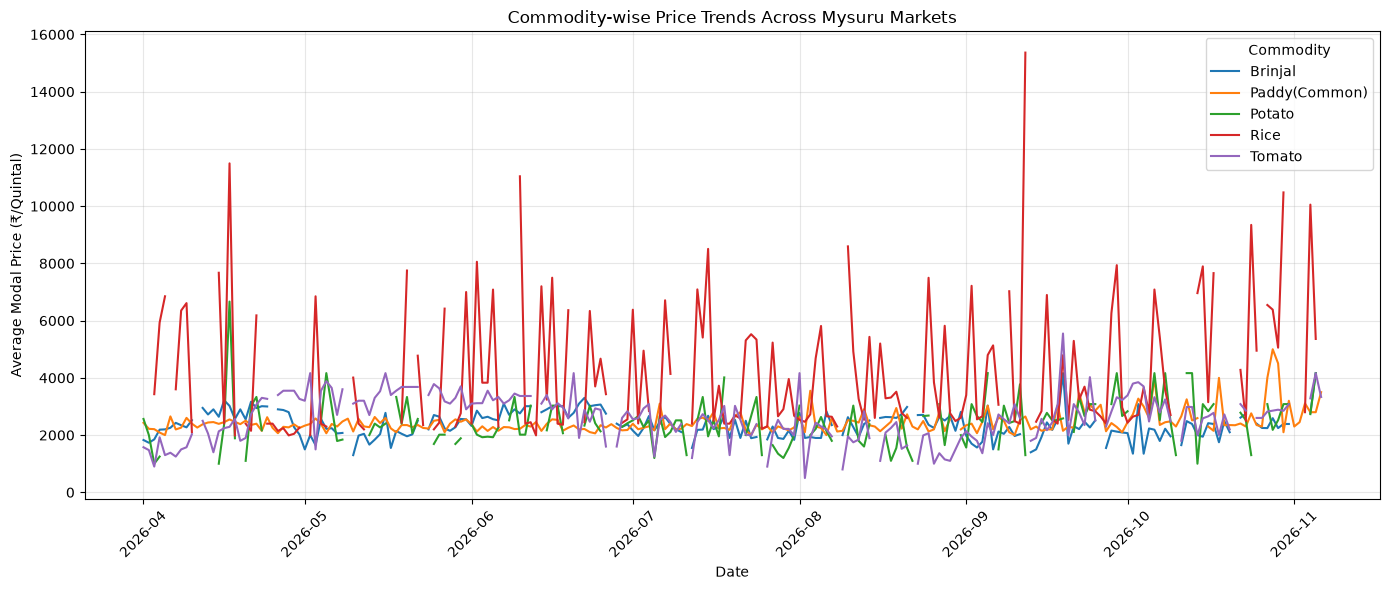

In [132]:
# Commodity-wise price trends over time

eda_clean["Arrival_Date"] = pd.to_datetime(eda_clean["Arrival_Date"])

daily_prices = (
    eda_clean.groupby(["Arrival_Date", "Commodity"])["Modal_Price"]
    .mean()
    .reset_index()
)

price_pivot = daily_prices.pivot(
    index="Arrival_Date",
    columns="Commodity",
    values="Modal_Price"
)

plt.figure(figsize=(14, 6))

for commodity in price_pivot.columns:
    plt.plot(
        price_pivot.index,
        price_pivot[commodity],
        label=commodity
    )

plt.title("Commodity-wise Price Trends Across Mysuru Markets")
plt.xlabel("Date")
plt.ylabel("Average Modal Price (₹/Quintal)")
plt.legend(title="Commodity")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

<Figure size 1200x600 with 0 Axes>

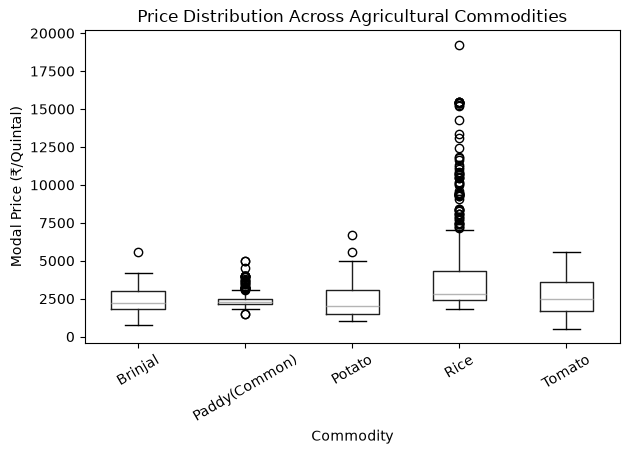

In [133]:
# Commodity-wise price distribution

plt.figure(figsize=(12, 6))

eda_clean.boxplot(
    column="Modal_Price",
    by="Commodity",
    grid=False
)

plt.title("Price Distribution Across Agricultural Commodities")
plt.suptitle("")
plt.xlabel("Commodity")
plt.ylabel("Modal Price (₹/Quintal)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [134]:
# Detect price outliers using the IQR method

outlier_summary = []

for commodity in eda_clean["Commodity"].unique():

    data = eda_clean[
        eda_clean["Commodity"] == commodity
    ]["Modal_Price"]

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = data[
        (data < lower_limit) | (data > upper_limit)
    ]

    outlier_summary.append({
        "Commodity": commodity,
        "Total_Records": len(data),
        "Outlier_Count": len(outliers),
        "Lower_Limit": round(lower_limit, 2),
        "Upper_Limit": round(upper_limit, 2)
    })

outlier_summary = pd.DataFrame(outlier_summary)

display(outlier_summary)

,Commodity,Total_Records,Outlier_Count,Lower_Limit,Upper_Limit
0,Brinjal,596,1,0.00,4800.00
1,Paddy(Common),524,32,1532.62,3099.62
2,Potato,296,2,-946.00,5510.00
3,Rice,382,64,-450.00,7150.00
4,Tomato,429,0,-1150.00,6450.00


In [135]:
# Inspect the 15 highest Rice prices

rice_outliers = eda_clean[
    eda_clean["Commodity"] == "Rice"
].sort_values(
    "Modal_Price",
    ascending=False
)

display(
    rice_outliers[
        [
            "Arrival_Date",
            "Market",
            "Variety",
            "Grade",
            "Min_Price",
            "Max_Price",
            "Modal_Price"
        ]
    ].head(15)
)

,Arrival_Date,Market,Variety,Grade,Min_Price,Max_Price,Modal_Price
1825,2026-09-09,Mysuru APMC,Basmati,Local,19250.0,19250.0,19250.0
1119,2026-07-13,Mysuru APMC,Basmati,Local,15474.0,15474.0,15474.0
1149,2026-07-15,Mysuru APMC,Basmati,Local,15471.0,15471.0,15471.0
715,2026-06-08,Mysuru APMC,Basmati,Local,15449.0,15449.0,15449.0
744,2026-06-10,Mysuru APMC,Basmati,Local,15448.0,15448.0,15448.0
2244,2026-10-14,Mysuru APMC,Basmati,Local,9140.0,15398.0,15398.0
2054,2026-09-28,Mysuru APMC,Basmati,Local,15395.0,15395.0,15395.0
1900,2026-09-16,Mysuru APMC,Basmati,Local,15369.0,15465.0,15369.0
1867,2026-09-12,Mysuru APMC,Basmati,Local,15366.0,15366.0,15366.0
173,2026-04-17,Mysuru APMC,Basmati,Grade Range-1,15295.0,15295.0,15295.0


In [136]:
import pandas as pd
from IPython.display import display

# 1. Prepare price data
price_data = eda_clean.copy()

# 2. Prepare arrival data
arrival_data = arrivals.copy()

# 3. Standardise date columns
price_data["Arrival_Date"] = pd.to_datetime(
    price_data["Arrival_Date"]
).dt.strftime("%Y-%m-%d")

arrival_data["Report_Date"] = pd.to_datetime(
    arrival_data["Report_Date"]
).dt.strftime("%Y-%m-%d")

# 4. Merge using date, commodity and market
arrival_price = pd.merge(
    price_data,
    arrival_data,
    left_on=["Arrival_Date", "Commodity", "Market"],
    right_on=["Report_Date", "Commodity", "Market"],
    how="inner"
)

# 5. Display matched records
print("ARRIVAL VS PRICE ANALYSIS")
print("Total matched records:", len(arrival_price))

display(
    arrival_price[
        ["Arrival_Date", "Commodity", "Market",
         "Arrivals", "Modal_Price"]
    ]
)

# 6. Calculate summary only if enough records exist
if len(arrival_price) >= 2:

    arrival_summary = (
        arrival_price.groupby("Commodity")
        .agg(
            Average_Arrivals=("Arrivals", "mean"),
            Average_Price=("Modal_Price", "mean"),
            Total_Records=("Modal_Price", "count")
        )
        .round(2)
    )

    print("\nARRIVAL AND PRICE SUMMARY")
    display(arrival_summary)

else:
    print(
        "\nWARNING: Not enough matched records "
        "to calculate a meaningful arrival-price relationship."
    )

ARRIVAL VS PRICE ANALYSIS
Total matched records: 1


,Arrival_Date,Commodity,Market,Arrivals,Modal_Price
0,2026-10-30,Rice,Mysuru APMC,9.6,10480.0


In [137]:
# FINAL RAW VS CLEANED DATA COMPARISON

keys = [
    "Arrival_Date",
    "Commodity",
    "Market",
    "Variety",
    "Grade"
]

raw_check = raw_prices.copy()
clean_check = cleaned_prices.copy()

for df in [raw_check, clean_check]:
    df["Arrival_Date"] = pd.to_datetime(
        df["Arrival_Date"], errors="coerce"
    )

# Count duplicate identifying keys
print("RAW DATA DUPLICATE KEYS:")
print(raw_check.duplicated(keys, keep=False).sum())

print("\nCLEANED DATA DUPLICATE KEYS:")
print(clean_check.duplicated(keys, keep=False).sum())

# Check suspicious price record directly
print("\nPADDY RECORD COMPARISON:")

display(
    raw_check[
        (raw_check["Arrival_Date"] == "2026-05-08") &
        (raw_check["Commodity"] == "Paddy(Common)") &
        (raw_check["Market"] == "T. Narasipura APMC")
    ]
)

display(
    clean_check[
        (clean_check["Arrival_Date"] == "2026-05-08") &
        (clean_check["Commodity"] == "Paddy(Common)") &
        (clean_check["Market"] == "T. Narasipura APMC")
    ]
)

RAW DATA DUPLICATE KEYS:
7770

CLEANED DATA DUPLICATE KEYS:
0

PADDY RECORD COMPARISON:


,Arrival_Date,Commodity,Commodity_Code,District,Grade,Market,Max_Price,Min_Price,Modal_Price,State,Variety
12045,2026-05-08,Paddy(Common),2,Mysuru,Non-FAQ,T. Narasipura APMC,3000,2200,2250,Karnataka,Paddy


,Arrival_Date,Commodity,Market,Variety,Grade,Commodity_Code,District,State,Min_Price,Max_Price,Modal_Price,Price_Quality
377,2026-05-08,Paddy(Common),T. Narasipura APMC,Paddy,Non-FAQ,2,Mysuru,Karnataka,2704.0,3000.0,2700.0,Review


In [138]:
# TRACE THE PRICE VALUES FOR THIS RECORD

raw_record = raw_check[
    (raw_check["Arrival_Date"] == "2026-05-08") &
    (raw_check["Commodity"] == "Paddy(Common)") &
    (raw_check["Market"] == "T. Narasipura APMC")
]

clean_record = clean_check[
    (clean_check["Arrival_Date"] == "2026-05-08") &
    (clean_check["Commodity"] == "Paddy(Common)") &
    (clean_check["Market"] == "T. Narasipura APMC")
]

print("Number of matching original records:", len(raw_record))
print("Number of matching cleaned records:", len(clean_record))

print("\nORIGINAL PRICE VALUES:")
display(raw_record[["Min_Price", "Modal_Price", "Max_Price"]])

print("\nCLEANED PRICE VALUES:")
display(clean_record[["Min_Price", "Modal_Price", "Max_Price"]])

Number of matching original records: 1
Number of matching cleaned records: 1

ORIGINAL PRICE VALUES:


,Min_Price,Modal_Price,Max_Price
12045,2200,2250,3000



CLEANED PRICE VALUES:


,Min_Price,Modal_Price,Max_Price
377,2704.0,2700.0,3000.0
